# Logistics, Delivery & Returns Insights — Documented Notebook

**Path-aware notebook recovery:** The first code cell now verifies all seven original CSV files and automatically changes Python's working directory to the project folder (`~/Documents/Python-Learning/Python-Capstone-Option-B/`) when needed. The existing relative `Data/Raw/...` imports remain unchanged.

**Run order:** Choose **Kernel → Restart Kernel and Run All Cells** (or the equivalent in your Jupyter version). Saved outputs do not restore variables after reopening a notebook; execute from the top, not just Step 103.

The historical `order_date` KeyError is preserved as a **read-only Markdown learning example**, so it will not block a full execution. No historical analytical code or source CSV files were modified.

**Checkpoint:** Steps through 102 were previously validated. Step 103 remains pending until executed and validated on your iMac.

In [3]:
# ============================================================
# NOTEBOOK CELL 001 — VERIFY ACTIVE PYTHON INTERPRETER
# ============================================================
# PURPOSE: Identify the Python executable backing this Jupyter kernel.
# INPUT: Current Python session and previously derived notebook variables.
# OUTPUT: Printed tables, charts, or diagnostic summaries; no assigned object.
# DATA SAFETY: Read-only or new in-memory objects; original input CSVs remain unchanged.
# ANALYTICAL NOTE: Use the interpreter path to troubleshoot package and environment mismatches.
# ============================================================

# SECTION — REQUIRED LIBRARIES
# Inspect the Python interpreter used by the notebook.
import sys

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print(sys.executable)

# SECTION — RESOLVE THE PROJECT FOLDER BEFORE READING RAW CSVs
# Jupyter may start in a different directory when a notebook is downloaded or moved.
# Locate the actual project using its known iMac location, then verify all raw files.
from pathlib import Path
import os

# Prefer the current working directory when it already contains the expected data.
# Otherwise check the project's established location under Documents.
project_candidates = [
    Path.cwd(),
    Path.home() / "Documents" / "Python-Learning" / "Python-Capstone-Option-B"
]

# All seven original CSVs must be present before continuing.
raw_csv_names = (
    "customers.csv", "products.csv", "orders.csv", "order_items.csv",
    "payments.csv", "shipments.csv", "returns.csv"
)

# Find a project folder containing the complete Data/Raw CSV package.
project_root = next(
    (
        path for path in project_candidates
        if all((path / "Data" / "Raw" / name).is_file() for name in raw_csv_names)
    ),
    None
)

# Stop with useful file-path guidance instead of failing at an unrelated CSV import.
if project_root is None:
    checked = "\n".join(str(path / "Data" / "Raw") for path in project_candidates)
    raise FileNotFoundError(
        "Could not locate all seven original CSV files. Checked these folders:\n"
        + checked
        + "\nKeep the seven CSVs inside the project's Data/Raw folder."
    )

# Set the working directory once so existing relative file paths work unchanged.
os.chdir(project_root)
print("Project working directory:", Path.cwd())
print("Verified raw CSV files:", len(raw_csv_names), "of", len(raw_csv_names))



/Users/imacm3/python-learning/bin/python
Project working directory: /Users/imacm3/Documents/Python-Learning/Python-Capstone-Option-B
Verified raw CSV files: 7 of 7


In [4]:
# ============================================================
# NOTEBOOK CELL 002 — LOAD SEVEN RAW RETAIL CSV FILES
# ============================================================
# PURPOSE: Import Pandas and load all seven retail/e-commerce source tables.
# INPUT: `customers`, `products`, `orders`, `order_items`, `payments`.
# OUTPUT: `customers`, `products`, `orders`, `order_items`, `payments`, `...`.
# DATA SAFETY: Read-only or new in-memory objects; original input CSVs remain unchanged.
# ANALYTICAL NOTE: Keep these raw DataFrames separate from later `_clean` working copies.
# ============================================================

# SECTION — REQUIRED LIBRARIES
# Load tabular CSVs and perform DataFrame operations.
import pandas as pd

# Load an existing CSV into customers; no source CSV content is edited.
customers = pd.read_csv("Data/Raw/customers.csv")

# Load an existing CSV into products; no source CSV content is edited.
products = pd.read_csv("Data/Raw/products.csv")

# Load an existing CSV into orders; no source CSV content is edited.
orders = pd.read_csv("Data/Raw/orders.csv")

# Load an existing CSV into order_items; no source CSV content is edited.
order_items = pd.read_csv("Data/Raw/order_items.csv")

# Load an existing CSV into payments; no source CSV content is edited.
payments = pd.read_csv("Data/Raw/payments.csv")

# Load an existing CSV into shipments; no source CSV content is edited.
shipments = pd.read_csv("Data/Raw/shipments.csv")

# Load an existing CSV into returns; no source CSV content is edited.
returns = pd.read_csv("Data/Raw/returns.csv")

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("All 7 datasets loaded successfully!")


All 7 datasets loaded successfully!


In [5]:
# ============================================================
# NOTEBOOK CELL 003 — CHECK SOURCE TABLE DIMENSIONS
# ============================================================
# PURPOSE: Print rows and columns for all seven imported CSV datasets.
# INPUT: `customers`, `products`, `orders`, `order_items`, `payments`.
# OUTPUT: Printed tables, charts, or diagnostic summaries; no assigned object.
# DATA SAFETY: Read-only or new in-memory objects; original input CSVs remain unchanged.
# ANALYTICAL NOTE: Establish a baseline before any deduplication or transformation.
# ============================================================

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("Customers:", customers.shape)
print("Products:", products.shape)
print("Orders:", orders.shape)
print("Order Items:", order_items.shape)
print("Payments:", payments.shape)
print("Shipments:", shipments.shape)
print("Returns:", returns.shape)


Customers: (5050, 13)
Products: (800, 9)
Orders: (15075, 8)
Order Items: (37763, 5)
Payments: (15000, 6)
Shipments: (15000, 7)
Returns: (1200, 6)


In [6]:
# ============================================================
# NOTEBOOK CELL 004 — INSPECT SHIPMENT AND RETURN COLUMNS
# ============================================================
# PURPOSE: Identify column names for the two main Option B subject areas.
# INPUT: `shipments`, `returns`.
# OUTPUT: Printed tables, charts, or diagnostic summaries; no assigned object.
# DATA SAFETY: Read-only or new in-memory objects; original input CSVs remain unchanged.
# ANALYTICAL NOTE: Verify the actual schema before selecting fields in later steps.
# ============================================================

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("Shipments Columns:", shipments.columns.tolist())

print("Returns Columns:", returns.columns.tolist())

Shipments Columns: ['shipment_id', 'order_id', 'courier', 'tracking_no', 'shipment_status', 'ship_date', 'delivered_date']
Returns Columns: ['return_id', 'order_id', 'return_request_date', 'reason', 'refunded_flag', 'refund_amount']


In [7]:
# ============================================================
# NOTEBOOK CELL 005 — INSPECT REMAINING SOURCE COLUMN NAMES
# ============================================================
# PURPOSE: Identify the field names for customers, products, orders, items, and payments.
# INPUT: `customers`, `products`, `orders`, `order_items`, `payments`.
# OUTPUT: Printed tables, charts, or diagnostic summaries; no assigned object.
# DATA SAFETY: Read-only or new in-memory objects; original input CSVs remain unchanged.
# ANALYTICAL NOTE: Prevent schema assumptions and mismatched column names.
# ============================================================

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("Customers:", customers.columns.tolist())
print("Products:", products.columns.tolist())
print("Orders:", orders.columns.tolist())
print("Order Items:", order_items.columns.tolist())
print("Payments:", payments.columns.tolist())

Customers: ['customer_id', 'first_name', 'last_name', 'gender', 'age', 'email', 'phone', 'region_code', 'region_name', 'city', 'barangay', 'signup_date', 'loyalty_tier']
Products: ['product_id', 'product_name', 'brand', 'category', 'unit_cost', 'unit_price', 'stock_qty', 'uom', 'launch_date']
Orders: ['order_id', 'customer_id', 'order_datetime', 'order_status', 'sales_channel', 'shipping_method', 'discount_pct', 'shipping_fee']
Order Items: ['order_item_id', 'order_id', 'product_id', 'quantity', 'unit_price_at_purchase']
Payments: ['payment_id', 'order_id', 'payment_method', 'payment_status', 'payment_date', 'amount_paid']


In [8]:
# ============================================================
# NOTEBOOK CELL 006 — INSPECT SHIPMENT DATA TYPES
# ============================================================
# PURPOSE: Review the shipment table's columns, null counts, and inferred dtypes.
# INPUT: `shipments`.
# OUTPUT: Printed tables, charts, or diagnostic summaries; no assigned object.
# DATA SAFETY: Read-only or new in-memory objects; original input CSVs remain unchanged.
# ANALYTICAL NOTE: Detect date strings that require explicit parsing before arithmetic.
# ============================================================

# Inspect schema, data types, and non-null counts without changing the source.
shipments.info()

<class 'pandas.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   shipment_id      15000 non-null  str  
 1   order_id         15000 non-null  str  
 2   courier          15000 non-null  str  
 3   tracking_no      15000 non-null  str  
 4   shipment_status  15000 non-null  str  
 5   ship_date        15000 non-null  str  
 6   delivered_date   14271 non-null  str  
dtypes: str(7)
memory usage: 1.8 MB


In [9]:
# ============================================================
# NOTEBOOK CELL 007 — COUNT MISSING SHIPMENT VALUES
# ============================================================
# PURPOSE: Profile missing values in every shipment field.
# INPUT: `shipments`.
# OUTPUT: Printed tables, charts, or diagnostic summaries; no assigned object.
# DATA SAFETY: Read-only or new in-memory objects; original input CSVs remain unchanged.
# ANALYTICAL NOTE: Missing delivery dates may be legitimate for non-delivered shipments.
# ============================================================

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print(shipments.isna().sum())

shipment_id          0
order_id             0
courier              0
tracking_no          0
shipment_status      0
ship_date            0
delivered_date     729
dtype: int64


In [10]:
# ============================================================
# NOTEBOOK CELL 008 — COUNT SHIPMENT STATUS VALUES
# ============================================================
# PURPOSE: Summarize records by recorded shipment status.
# INPUT: `shipments`.
# OUTPUT: Printed tables, charts, or diagnostic summaries; no assigned object.
# DATA SAFETY: Read-only or new in-memory objects; original input CSVs remain unchanged.
# ANALYTICAL NOTE: These are source statuses, not independently confirmed real-world outcomes.
# ============================================================

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print(shipments["shipment_status"].value_counts())

shipment_status
Delivered             11680
In Transit             2694
Returned to Sender      465
Lost                    161
Name: count, dtype: int64


In [11]:
# ============================================================
# NOTEBOOK CELL 009 — CROSS-TABULATE STATUS AND DELIVERY-DATE MISSINGNESS
# ============================================================
# PURPOSE: Compare shipment statuses against presence or absence of a delivery date.
# INPUT: `shipments`.
# OUTPUT: Printed tables, charts, or diagnostic summaries; no assigned object.
# DATA SAFETY: Read-only or new in-memory objects; original input CSVs remain unchanged.
# ANALYTICAL NOTE: A status/date disagreement is a review flag, not automatic proof of error.
# ============================================================

# Build a cross-tabulation to compare recorded statuses against another condition.
pd.crosstab(
    shipments["shipment_status"],
    shipments["delivered_date"].isna()
)

delivered_date,False,True
shipment_status,,
Delivered,11122,558
In Transit,2557,137
Lost,151,10
Returned to Sender,441,24


In [12]:
# ============================================================
# NOTEBOOK CELL 010 — INSPECT DELIVERED SHIPMENTS WITHOUT DATES
# ============================================================
# PURPOSE: Extract cases marked Delivered even though delivery dates are missing.
# INPUT: `shipments`.
# OUTPUT: `delivered_missing_date`.
# DATA SAFETY: Read-only or new in-memory objects; original input CSVs remain unchanged.
# ANALYTICAL NOTE: Keep source rows intact while reviewing these questionable combinations.
# ============================================================

# Calculate delivered_missing_date as a missing-value or quality-rule indicator.
delivered_missing_date = shipments[
    (shipments["shipment_status"] == "Delivered") &
    (shipments["delivered_date"].isna())
]

# Display sample rows or an analytical summary without changing the DataFrame.
display(delivered_missing_date.head())

,shipment_id,order_id,courier,tracking_no,shipment_status,ship_date,delivered_date
24,SHP0000025,ORD0000025,GrabExpress,04517LZLQF7U,Delivered,2024-03-19,NaN
27,SHP0000028,ORD0000028,J&T,CZKK425MUQYH,Delivered,2024-03-31,NaN
38,SHP0000039,ORD0000039,J&T,CTU7TEG2SA4R,Delivered,13-Oct-2024,NaN
64,SHP0000065,ORD0000065,NinjaVan,32AGND4SDBW2,Delivered,2024-01-19,NaN
71,SHP0000072,ORD0000072,LBC,Q2WD7BACWAMZ,Delivered,2025-04-03,NaN


In [13]:
# ============================================================
# NOTEBOOK CELL 011 — INSPECT NON-DELIVERED SHIPMENTS WITH DATES
# ============================================================
# PURPOSE: Inspect shipments with a delivery date although status is not Delivered.
# INPUT: `shipments`.
# OUTPUT: `non_delivered_with_date`.
# DATA SAFETY: Read-only or new in-memory objects; original input CSVs remain unchanged.
# ANALYTICAL NOTE: Retain the possible status/date conflicts for follow-up validation.
# ============================================================

# Create or update non_delivered_with_date using the immediately preceding source variables.
non_delivered_with_date = shipments[
    (shipments["shipment_status"] != "Delivered") &
    (shipments["delivered_date"].notna())
]

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("Matching records:", len(non_delivered_with_date))

# Display sample rows or an analytical summary without changing the DataFrame.
display(non_delivered_with_date.head())

Matching records: 3149


,shipment_id,order_id,courier,tracking_no,shipment_status,ship_date,delivered_date
1,SHP0000002,ORD0000002,NinjaVan,E8XLRMV7QVEB,In Transit,2025-02-06,2025-02-12
4,SHP0000005,ORD0000005,2GO,XQLUM80WBUSJ,In Transit,2025-09-21,2025-09-26
9,SHP0000010,ORD0000010,LBC,63PL5YHEGUNN,In Transit,08-Dec-2024,12/14/2024
12,SHP0000013,ORD0000013,2GO,J96F7RLNZM1R,In Transit,2025-11-04,11/09/2025
13,SHP0000014,ORD0000014,J&T,N6Z3GPL6H1E6,In Transit,15-Sep-2025,2025-09-18


In [14]:
# ============================================================
# NOTEBOOK CELL 012 — MEASURE EXACT DUPLICATES IN KEY TABLES
# ============================================================
# PURPOSE: Count exact duplicate rows across customers, orders, and order items.
# INPUT: `customers`, `orders`, `order_items`.
# OUTPUT: Printed tables, charts, or diagnostic summaries; no assigned object.
# DATA SAFETY: Read-only or new in-memory objects; original input CSVs remain unchanged.
# ANALYTICAL NOTE: Duplicate detection here compares whole rows, not only entity IDs.
# ============================================================

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("Customers duplicates:", customers.duplicated().sum())

print("Orders duplicates:", orders.duplicated().sum())

print("Order Items duplicates:", order_items.duplicated().sum())

Customers duplicates: 50
Orders duplicates: 75
Order Items duplicates: 262


In [15]:
# ============================================================
# NOTEBOOK CELL 013 — CREATE DEDUPLICATED WORKING COPIES
# ============================================================
# PURPOSE: Remove only exact duplicate rows from three working datasets.
# INPUT: `customers`, `orders`, `order_items`, `customers_clean`, `orders_clean`.
# OUTPUT: `customers_clean`, `orders_clean`, `order_items_clean`.
# DATA SAFETY: Read-only or new in-memory objects; original input CSVs remain unchanged.
# ANALYTICAL NOTE: Use `.copy()` to preserve the loaded raw source DataFrames.
# ============================================================

# Create customers_clean by removing verified exact duplicate rows.
customers_clean = customers.drop_duplicates().copy()

# Create orders_clean by removing verified exact duplicate rows.
orders_clean = orders.drop_duplicates().copy()

# Create order_items_clean by removing verified exact duplicate rows.
order_items_clean = order_items.drop_duplicates().copy()

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("Customers cleaned:", customers_clean.shape)
print("Orders cleaned:", orders_clean.shape)
print("Order Items cleaned:", order_items_clean.shape)

Customers cleaned: (5000, 13)
Orders cleaned: (15000, 8)
Order Items cleaned: (37501, 5)


In [16]:
# ============================================================
# NOTEBOOK CELL 014 — VALIDATE DEDUPLICATION AND IDENTIFIER UNIQUENESS
# ============================================================
# PURPOSE: Confirm there are no remaining exact duplicates or duplicate primary keys.
# INPUT: `customers_clean`, `orders_clean`, `order_items_clean`.
# OUTPUT: Printed tables, charts, or diagnostic summaries; no assigned object.
# DATA SAFETY: Read-only or new in-memory objects; original input CSVs remain unchanged.
# ANALYTICAL NOTE: Check entity-level uniqueness after removing repeated rows.
# ============================================================

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("Customers exact duplicates:", customers_clean.duplicated().sum())
print("Customers duplicate IDs:", customers_clean["customer_id"].duplicated().sum())

print("Orders exact duplicates:", orders_clean.duplicated().sum())
print("Orders duplicate IDs:", orders_clean["order_id"].duplicated().sum())

print("Order Items exact duplicates:", order_items_clean.duplicated().sum())
print("Order Items duplicate IDs:", order_items_clean["order_item_id"].duplicated().sum())

Customers exact duplicates: 0
Customers duplicate IDs: 0
Orders exact duplicates: 0
Orders duplicate IDs: 0
Order Items exact duplicates: 0
Order Items duplicate IDs: 0


## CL-001: Exact Duplicate Removal

**Status:** QA PASSED

**Objective:** Remove verified exact duplicate records
while preserving unique business entities.

**Duplicate Definition:**
Rows are considered exact duplicates when all column
values match. The first occurrence is retained.

**Detection Method:**
DataFrame.duplicated().sum()

**Cleaning Method:**
DataFrame.drop_duplicates().copy()

### Cleaning Results

| Dataset | Before | Removed | After |
|---|---:|---:|---:|
| Customers | 5,050 | 50 | 5,000 |
| Orders | 15,075 | 75 | 15,000 |
| Order Items | 37,763 | 262 | 37,501 |
| TOTAL | 57,888 | 387 | 57,501 |

### Validation Results

- Customers: 0 exact duplicates, 0 duplicate customer IDs
- Orders: 0 exact duplicates, 0 duplicate order IDs
- Order Items: 0 exact duplicates, 0 duplicate order item IDs

### Business Justification

Duplicate records can inflate transaction counts,
customer counts, and order-level analytical metrics.

Removing verified duplicate copies helps prevent
incorrect reporting and join-related overcounting.

### Data Preservation

Original CSV files in Data/Raw remain unchanged.

Cleaned DataFrames currently exist in Python memory.
Export and persistence validation are still pending.

In [17]:
# ============================================================
# NOTEBOOK CELL 015 — PROFILE NULL VALUES IN ALL WORKING TABLES
# ============================================================
# PURPOSE: Collect working tables and print missing values across all seven datasets.
# INPUT: `products`, `payments`, `shipments`, `returns`, `customers_clean`.
# OUTPUT: `datasets`.
# DATA SAFETY: Read-only or new in-memory objects; original input CSVs remain unchanged.
# ANALYTICAL NOTE: Do not fill missing values indiscriminately; interpret their meaning first.
# ============================================================

# Create or update datasets using the immediately preceding source variables.
datasets = {
    "Customers": customers_clean,
    "Products": products,
    "Orders": orders_clean,
    "Order Items": order_items_clean,
    "Payments": payments,
    "Shipments": shipments,
    "Returns": returns
}

# Iterate over observed values or column names to profile each case without altering source records.
for name, df in datasets.items():
    print()
    print(name, "missing values:")
    print(df.isna().sum())


Customers missing values:
customer_id       0
first_name        0
last_name         0
gender          298
age             149
email           104
phone           145
region_code       0
region_name       0
city              0
barangay          0
signup_date       0
loyalty_tier    264
dtype: int64

Products missing values:
product_id       0
product_name     0
brand            0
category         0
unit_cost        0
unit_price       0
stock_qty       19
uom              0
launch_date      0
dtype: int64

Orders missing values:
order_id             0
customer_id          0
order_datetime       0
order_status         0
sales_channel        0
shipping_method      0
discount_pct       756
shipping_fee       470
dtype: int64

Order Items missing values:
order_item_id                0
order_id                     0
product_id                   0
quantity                     0
unit_price_at_purchase    2236
dtype: int64

Payments missing values:
payment_id          0
order_id            0
pa

In [18]:
# ============================================================
# NOTEBOOK CELL 016 — INSPECT MISSING SHIPPING FEES BY METHOD
# ============================================================
# PURPOSE: Cross-tabulate shipping method against missing shipping fees.
# INPUT: `orders_clean`.
# OUTPUT: Printed tables, charts, or diagnostic summaries; no assigned object.
# DATA SAFETY: Read-only or new in-memory objects; original input CSVs remain unchanged.
# ANALYTICAL NOTE: Determine whether missing fees follow a known shipping method pattern.
# ============================================================

# Build a cross-tabulation to compare recorded statuses against another condition.
pd.crosstab(
    orders_clean["shipping_method"],
    orders_clean["shipping_fee"].isna(),
    margins=True
)

shipping_fee,False,True,All
shipping_method,,,
Express,4863,176,5039
Pickup,4777,147,4924
Standard,4890,147,5037
All,14530,470,15000


In [19]:
# ============================================================
# NOTEBOOK CELL 017 — COMPARE SHIPPING FEES ACROSS METHODS
# ============================================================
# PURPOSE: Summarize recorded shipping fees for each shipping method.
# INPUT: `orders_clean`.
# OUTPUT: Printed tables, charts, or diagnostic summaries; no assigned object.
# DATA SAFETY: Read-only or new in-memory objects; original input CSVs remain unchanged.
# ANALYTICAL NOTE: Use distribution checks before considering any fill policy.
# ============================================================

# Display sample rows or an analytical summary without changing the DataFrame.
display(
    orders_clean.groupby("shipping_method")["shipping_fee"].describe()
)

,count,mean,std,min,25%,50%,75%,max
shipping_method,,,,,,,,
Express,4863.0,85.507715,34.371057,0.0,61.920,85.97,108.520,198.02
Pickup,4777.0,85.809309,35.232707,0.0,62.090,85.24,109.380,208.76
Standard,4890.0,85.922063,35.178581,0.0,62.195,86.25,109.605,212.16


In [20]:
# ============================================================
# NOTEBOOK CELL 018 — FLAG MISSING SHIPPING FEES
# ============================================================
# PURPOSE: Add a Boolean missing-fee indicator to the cleaned orders table.
# INPUT: `orders_clean`.
# OUTPUT: `orders_clean['shipping_fee_missing']`.
# DATA SAFETY: Updates derived fields only in working table(s): orders_clean. Original input CSVs remain untouched.
# ANALYTICAL NOTE: Preserve the original shipping_fee field rather than fabricating amounts.
# ============================================================

# Calculate orders_clean['shipping_fee_missing'] as a missing-value or quality-rule indicator.
orders_clean["shipping_fee_missing"] = orders_clean["shipping_fee"].isna()

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print(orders_clean["shipping_fee_missing"].value_counts())

print("Original missing fees:", orders_clean["shipping_fee"].isna().sum())

shipping_fee_missing
False    14530
True       470
Name: count, dtype: int64
Original missing fees: 470


In [21]:
# ============================================================
# NOTEBOOK CELL 019 — STANDARDIZE MISSING LOYALTY LABELS
# ============================================================
# PURPOSE: Create a reporting label for customers with missing loyalty tiers.
# INPUT: `customers_clean`.
# OUTPUT: `customers_clean['loyalty_tier_clean']`.
# DATA SAFETY: Updates derived fields only in working table(s): customers_clean. Original input CSVs remain untouched.
# ANALYTICAL NOTE: Keep the raw loyalty_tier column available for QA and comparison.
# ============================================================

# Create or update customers_clean['loyalty_tier_clean'] using the immediately preceding source variables.
customers_clean["loyalty_tier_clean"] = customers_clean["loyalty_tier"].fillna("Unknown")

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("Original missing:", customers_clean["loyalty_tier"].isna().sum())

print("Cleaned missing:", customers_clean["loyalty_tier_clean"].isna().sum())

print("Unknown values:", (customers_clean["loyalty_tier_clean"] == "Unknown").sum())

Original missing: 264
Cleaned missing: 0
Unknown values: 264


In [22]:
# ============================================================
# NOTEBOOK CELL 020 — INSPECT MISSING DISCOUNTS BY ORDER STATUS
# ============================================================
# PURPOSE: Compare order status and missing discount percentages.
# INPUT: `orders_clean`.
# OUTPUT: Printed tables, charts, or diagnostic summaries; no assigned object.
# DATA SAFETY: Read-only or new in-memory objects; original input CSVs remain unchanged.
# ANALYTICAL NOTE: Avoid treating missing discounts as equivalent to zero discounts.
# ============================================================

# Build a cross-tabulation to compare recorded statuses against another condition.
pd.crosstab(
    orders_clean["order_status"],
    orders_clean["discount_pct"].isna(),
    margins=True
)

discount_pct,False,True,All
order_status,,,
Cancelled,1168,67,1235
Completed,9353,497,9850
Pending,1455,74,1529
Returned,550,28,578
Shipped,1718,90,1808
All,14244,756,15000


In [23]:
# ============================================================
# NOTEBOOK CELL 021 — PROFILE RECORDED DISCOUNTS
# ============================================================
# PURPOSE: Inspect the distribution, zero values, and missing discount entries.
# INPUT: `orders_clean`.
# OUTPUT: Printed tables, charts, or diagnostic summaries; no assigned object.
# DATA SAFETY: Read-only or new in-memory objects; original input CSVs remain unchanged.
# ANALYTICAL NOTE: Understand the existing discount values before applying any rule.
# ============================================================

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print(orders_clean["discount_pct"].describe())

print("Recorded zero discounts:", (orders_clean["discount_pct"] == 0).sum())

print("Missing discounts:", orders_clean["discount_pct"].isna().sum())

count    14244.000000
mean         0.078469
std          0.067251
min          0.000000
25%          0.016000
50%          0.070000
75%          0.124000
max          0.350000
Name: discount_pct, dtype: float64
Recorded zero discounts: 2743
Missing discounts: 756


In [24]:
# ============================================================
# NOTEBOOK CELL 022 — FLAG MISSING DISCOUNT PERCENTAGES
# ============================================================
# PURPOSE: Add an explicit discount-missing flag to working orders.
# INPUT: `orders`, `orders_clean`.
# OUTPUT: `orders_clean['discount_pct_missing']`.
# DATA SAFETY: Updates derived fields only in working table(s): orders_clean. Original input CSVs remain untouched.
# ANALYTICAL NOTE: Retain null source discounts for later defensible treatment.
# ============================================================

# Calculate orders_clean['discount_pct_missing'] as a missing-value or quality-rule indicator.
orders_clean["discount_pct_missing"] = orders_clean["discount_pct"].isna()

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("Missing discount flags:", orders_clean["discount_pct_missing"].sum())

print("Missing discounts retained:", orders_clean["discount_pct"].isna().sum())

print("Zero discounts retained:", (orders_clean["discount_pct"] == 0).sum())

print("Total orders:", len(orders_clean))

Missing discount flags: 756
Missing discounts retained: 756
Zero discounts retained: 2743
Total orders: 15000


In [25]:
# ============================================================
# NOTEBOOK CELL 023 — INITIALIZE WORKING SHIPMENT QUALITY FLAGS
# ============================================================
# PURPOSE: Copy the shipment table and mark missing dates and lead-time candidates.
# INPUT: `shipments`, `shipments_clean`.
# OUTPUT: `shipments_clean`, `shipments_clean['delivery_date_missing']`, `shipments_clean['lead_time_candidate']`.
# DATA SAFETY: Updates derived fields only in working table(s): shipments_clean. Original input CSVs remain untouched.
# ANALYTICAL NOTE: Do not calculate delivery days from incomplete or incompatible fields yet.
# ============================================================

# Create a working copy in shipments_clean to preserve previous DataFrame values.
shipments_clean = shipments.copy()

# Calculate shipments_clean['delivery_date_missing'] as a missing-value or quality-rule indicator.
shipments_clean["delivery_date_missing"] = shipments_clean["delivered_date"].isna()

# Calculate shipments_clean['lead_time_candidate'] from an explicit comparison; this flags records for review.
shipments_clean["lead_time_candidate"] = (
    (shipments_clean["shipment_status"] == "Delivered") &
    (shipments_clean["delivered_date"].notna())
)

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("Missing delivery dates:", shipments_clean["delivery_date_missing"].sum())
print("Lead-time candidates:", shipments_clean["lead_time_candidate"].sum())
print("Total shipments:", len(shipments_clean))

Missing delivery dates: 729
Lead-time candidates: 11122
Total shipments: 15000


In [26]:
# ============================================================
# NOTEBOOK CELL 024 — INITIALIZE OTHER WORKING COPIES
# ============================================================
# PURPOSE: Create separate product, payment, and return working DataFrames.
# INPUT: `products`, `payments`, `returns`, `products_clean`, `payments_clean`.
# OUTPUT: `products_clean`, `payments_clean`, `returns_clean`.
# DATA SAFETY: Read-only or new in-memory objects; original input CSVs remain unchanged.
# ANALYTICAL NOTE: Raw source DataFrames remain available for independent checks.
# ============================================================

# Create a working copy in products_clean to preserve previous DataFrame values.
products_clean = products.copy()

# Create a working copy in payments_clean to preserve previous DataFrame values.
payments_clean = payments.copy()

# Create a working copy in returns_clean to preserve previous DataFrame values.
returns_clean = returns.copy()

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("Products:", products_clean.shape)
print("Payments:", payments_clean.shape)
print("Returns:", returns_clean.shape)

Products: (800, 9)
Payments: (15000, 6)
Returns: (1200, 6)


In [27]:
# ============================================================
# NOTEBOOK CELL 025 — CROSS-TABULATE REFUND STATUS AND MISSING AMOUNTS
# ============================================================
# PURPOSE: Compare refund flags with null/non-null refund amounts.
# INPUT: `returns_clean`.
# OUTPUT: Printed tables, charts, or diagnostic summaries; no assigned object.
# DATA SAFETY: Read-only or new in-memory objects; original input CSVs remain unchanged.
# ANALYTICAL NOTE: Refund amount presence alone does not prove a refund was completed.
# ============================================================

# Build a cross-tabulation to compare recorded statuses against another condition.
pd.crosstab(
    returns_clean["refunded_flag"].fillna("Missing"),
    returns_clean["refund_amount"].isna(),
    margins=True
)

refund_amount,False,True,All
refunded_flag,,,
Missing,92,18,110
No,248,53,301
Partial,119,17,136
Yes,554,99,653
All,1013,187,1200


In [28]:
# ============================================================
# NOTEBOOK CELL 026 — PROFILE CONFLICTING REFUND COMBINATIONS
# ============================================================
# PURPOSE: Count cases with refund status and refund amount disagreements.
# INPUT: `returns_clean`.
# OUTPUT: Printed tables, charts, or diagnostic summaries; no assigned object.
# DATA SAFETY: Read-only or new in-memory objects; original input CSVs remain unchanged.
# ANALYTICAL NOTE: Identify review candidates rather than force values to agree.
# ============================================================

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print(
    "No status with positive amount:",
    ((returns_clean["refunded_flag"] == "No") &
     (returns_clean["refund_amount"] > 0)).sum()
)

print(
    "Yes status with missing amount:",
    ((returns_clean["refunded_flag"] == "Yes") &
     (returns_clean["refund_amount"].isna())).sum()
)

print(
    "Missing status with recorded amount:",
    (returns_clean["refunded_flag"].isna() &
     returns_clean["refund_amount"].notna()).sum()
)

No status with positive amount: 232
Yes status with missing amount: 99
Missing status with recorded amount: 92


In [29]:
# ============================================================
# NOTEBOOK CELL 027 — CREATE REFUND REVIEW-REQUIRED FLAG
# ============================================================
# PURPOSE: Mark return records with missing or contradictory refund fields.
# INPUT: `returns`, `returns_clean`.
# OUTPUT: `returns_clean['refund_review_required']`.
# DATA SAFETY: Updates derived fields only in working table(s): returns_clean. Original input CSVs remain untouched.
# ANALYTICAL NOTE: Preserve the original refund status and amount.
# ============================================================

# Calculate returns_clean['refund_review_required'] as a missing-value or quality-rule indicator.
returns_clean["refund_review_required"] = (
    returns_clean["refunded_flag"].isna()
    | returns_clean["refund_amount"].isna()
    | (
        (returns_clean["refunded_flag"] == "No")
        & (returns_clean["refund_amount"] > 0)
    )
)

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("Records for review:", returns_clean["refund_review_required"].sum())
print("Other records:", (~returns_clean["refund_review_required"]).sum())
print("Total returns:", len(returns_clean))

Records for review: 511
Other records: 689
Total returns: 1200


In [30]:
# ============================================================
# NOTEBOOK CELL 028 — CREATE CLEAN REFUND STATUS LABELS
# ============================================================
# PURPOSE: Label missing refund flags as Unknown in a separate field.
# INPUT: `returns`, `returns_clean`.
# OUTPUT: `returns_clean['refunded_flag_clean']`.
# DATA SAFETY: Updates derived fields only in working table(s): returns_clean. Original input CSVs remain untouched.
# ANALYTICAL NOTE: Avoid inventing Yes/No refund decisions.
# ============================================================

# Create or update returns_clean['refunded_flag_clean'] using the immediately preceding source variables.
returns_clean["refunded_flag_clean"] = returns_clean["refunded_flag"].fillna("Unknown")

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("Original missing:", returns_clean["refunded_flag"].isna().sum())

print("Cleaned missing:", returns_clean["refunded_flag_clean"].isna().sum())

print("Unknown statuses:", (returns_clean["refunded_flag_clean"] == "Unknown").sum())

print("Records for review:", returns_clean["refund_review_required"].sum())

print("Total returns:", len(returns_clean))

Original missing: 110
Cleaned missing: 0
Unknown statuses: 110
Records for review: 511
Total returns: 1200


In [31]:
# ============================================================
# NOTEBOOK CELL 029 — FLAG MISSING REFUND AMOUNTS
# ============================================================
# PURPOSE: Create a missing-value marker for refund amounts.
# INPUT: `returns`, `returns_clean`.
# OUTPUT: `returns_clean['refund_amount_missing']`.
# DATA SAFETY: Updates derived fields only in working table(s): returns_clean. Original input CSVs remain untouched.
# ANALYTICAL NOTE: Maintain original nulls for reporting limitations.
# ============================================================

# Calculate returns_clean['refund_amount_missing'] as a missing-value or quality-rule indicator.
returns_clean["refund_amount_missing"] = returns_clean["refund_amount"].isna()

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("Missing refund amounts:", returns_clean["refund_amount_missing"].sum())

print("Original missing preserved:", returns_clean["refund_amount"].isna().sum())

print("Records for review:", returns_clean["refund_review_required"].sum())

print("Total returns:", len(returns_clean))

Missing refund amounts: 187
Original missing preserved: 187
Records for review: 511
Total returns: 1200


In [32]:
# ============================================================
# NOTEBOOK CELL 030 — IDENTIFY USABLE POSITIVE REFUND CANDIDATES
# ============================================================
# PURPOSE: Flag records with applicable refund labels and positive recorded amounts.
# INPUT: `returns`, `returns_clean`.
# OUTPUT: `returns_clean['refund_amount_candidate']`.
# DATA SAFETY: Updates derived fields only in working table(s): returns_clean. Original input CSVs remain untouched.
# ANALYTICAL NOTE: A candidate is not a verified payout or final refund settlement.
# ============================================================

# Use membership checks to construct returns_clean['refund_amount_candidate']; unmatched identifiers remain visible.
returns_clean["refund_amount_candidate"] = (
    returns_clean["refunded_flag_clean"].isin(["Yes", "Partial"])
    & returns_clean["refund_amount"].notna()
    & (returns_clean["refund_amount"] > 0)
)

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("Refund amount candidates:", returns_clean["refund_amount_candidate"].sum())
print("Not candidates:", (~returns_clean["refund_amount_candidate"]).sum())
print("Total returns:", len(returns_clean))

Refund amount candidates: 625
Not candidates: 575
Total returns: 1200


In [33]:
# ============================================================
# NOTEBOOK CELL 031 — INSPECT ZERO AND MISSING REFUND CASES
# ============================================================
# PURPOSE: Examine refund status combinations with zero or missing values.
# INPUT: `returns`, `returns_clean`.
# OUTPUT: Printed tables, charts, or diagnostic summaries; no assigned object.
# DATA SAFETY: Read-only or new in-memory objects; original input CSVs remain unchanged.
# ANALYTICAL NOTE: Check edge cases before finalizing refund review rules.
# ============================================================

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print(
    "Yes/Partial with zero refund:",
    (
        returns_clean["refunded_flag_clean"].isin(["Yes", "Partial"])
        & (returns_clean["refund_amount"] == 0)
    ).sum()
)

print(
    "Yes/Partial with negative refund:",
    (
        returns_clean["refunded_flag_clean"].isin(["Yes", "Partial"])
        & (returns_clean["refund_amount"] < 0)
    ).sum()
)

print(
    "Negative amounts across all returns:",
    (returns_clean["refund_amount"] < 0).sum()
)

Yes/Partial with zero refund: 48
Yes/Partial with negative refund: 0
Negative amounts across all returns: 0


In [34]:
# ============================================================
# NOTEBOOK CELL 032 — EXTEND REFUND REVIEW FLAGS FOR ZERO AMOUNTS
# ============================================================
# PURPOSE: Flag additional zero-amount refund contradictions.
# INPUT: `returns`, `returns_clean`.
# OUTPUT: `returns_clean['refund_zero_amount_review']`, `returns_clean['refund_review_required']`.
# DATA SAFETY: Updates derived fields only in working table(s): returns_clean. Original input CSVs remain untouched.
# ANALYTICAL NOTE: Use explicit Boolean logic rather than silently changing amounts.
# ============================================================

# Use membership checks to construct returns_clean['refund_zero_amount_review']; unmatched identifiers remain visible.
returns_clean["refund_zero_amount_review"] = (
    returns_clean["refunded_flag_clean"].isin(["Yes", "Partial"])
    & (returns_clean["refund_amount"] == 0)
)

# Create or update returns_clean['refund_review_required'] using the immediately preceding source variables.
returns_clean["refund_review_required"] = (
    returns_clean["refund_review_required"]
    | returns_clean["refund_zero_amount_review"]
)

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("Zero-amount review cases:", returns_clean["refund_zero_amount_review"].sum())
print("Updated records for review:", returns_clean["refund_review_required"].sum())
print("Not flagged for review:", (~returns_clean["refund_review_required"]).sum())
print("Total returns:", len(returns_clean))

Zero-amount review cases: 48
Updated records for review: 559
Not flagged for review: 641
Total returns: 1200


In [35]:
# ============================================================
# NOTEBOOK CELL 033 — RECONCILE REFUND CANDIDATES AND EXCEPTIONS
# ============================================================
# PURPOSE: Print refund candidate and exception counts.
# INPUT: `returns_clean`.
# OUTPUT: Printed tables, charts, or diagnostic summaries; no assigned object.
# DATA SAFETY: Read-only or new in-memory objects; original input CSVs remain unchanged.
# ANALYTICAL NOTE: Confirm refund selection rules remain internally consistent.
# ============================================================

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("Positive refund candidates:",
      returns_clean["refund_amount_candidate"].sum())

print("No refund with zero amount:",
      (
          (returns_clean["refunded_flag_clean"] == "No")
          & (returns_clean["refund_amount"] == 0)
      ).sum())

print("Unflagged records:",
      (~returns_clean["refund_review_required"]).sum())

print("Candidates also flagged for review:",
      (
          returns_clean["refund_amount_candidate"]
          & returns_clean["refund_review_required"]
      ).sum())

Positive refund candidates: 625
No refund with zero amount: 16
Unflagged records: 641
Candidates also flagged for review: 0


In [36]:
# ============================================================
# NOTEBOOK CELL 034 — PROFILE ORDER-ITEM PURCHASE PRICES
# ============================================================
# PURPOSE: Inspect missing unit prices and field data type.
# INPUT: `order_items_clean`.
# OUTPUT: Printed tables, charts, or diagnostic summaries; no assigned object.
# DATA SAFETY: Read-only or new in-memory objects; original input CSVs remain unchanged.
# ANALYTICAL NOTE: Determine whether the source is numeric or currency-formatted text.
# ============================================================

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("Total order items:", len(order_items_clean))

print("Missing purchase prices:",
      order_items_clean["unit_price_at_purchase"].isna().sum())

print("Purchase price data type:",
      order_items_clean["unit_price_at_purchase"].dtype)

print("Sample recorded prices:")
print(order_items_clean["unit_price_at_purchase"].dropna().head(10))

Total order items: 37501
Missing purchase prices: 2236
Purchase price data type: str
Sample recorded prices:
0     120.67
1      83.58
2      46.96
3     100.59
4     109.18
5      54.41
6      85.94
7     117.13
9      69.87
10     73.02
Name: unit_price_at_purchase, dtype: str


In [37]:
# ============================================================
# NOTEBOOK CELL 035 — INSPECT PURCHASE PRICE TEXT PATTERNS
# ============================================================
# PURPOSE: Count missing, peso-symbol, and other price representations.
# INPUT: `order_items_clean`.
# OUTPUT: `price`.
# DATA SAFETY: Read-only or new in-memory objects; original input CSVs remain unchanged.
# ANALYTICAL NOTE: Understand formatting variations before numeric conversion.
# ============================================================

# Create or update price using the immediately preceding source variables.
price = order_items_clean["unit_price_at_purchase"]

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("Missing prices:", price.isna().sum())

print("Prices with peso sign:",
      price.str.contains("₱", regex=False, na=False).sum())

print("Prices with comma:",
      price.str.contains(",", regex=False, na=False).sum())

print("Sample prices with peso sign:")
print(price[price.str.contains("₱", regex=False, na=False)].head(10))

Missing prices: 2236
Prices with peso sign: 3017
Prices with comma: 0
Sample prices with peso sign:
14      ₱69.98
28      ₱66.65
100     ₱61.87
106    ₱187.33
115    ₱124.98
141    ₱124.98
143    ₱158.86
164     ₱47.33
165     ₱76.66
166    ₱208.43
Name: unit_price_at_purchase, dtype: str


In [38]:
# ============================================================
# NOTEBOOK CELL 036 — CONVERT PURCHASE PRICE STRINGS TO NUMERIC
# ============================================================
# PURPOSE: Parse unit-price strings into a separate numeric working column.
# INPUT: `order_items_clean`.
# OUTPUT: `order_items_clean['unit_price_numeric']`, `original_missing`, `numeric_missing`.
# DATA SAFETY: Updates derived fields only in working table(s): order_items_clean. Original input CSVs remain untouched.
# ANALYTICAL NOTE: Coercion to NaN reveals unparseable values without overwriting raw prices.
# ============================================================

# Standardize source-text representations in order_items_clean['unit_price_numeric'] without editing the original column.
order_items_clean["unit_price_numeric"] = pd.to_numeric(
    order_items_clean["unit_price_at_purchase"]
        .str.replace("₱", "", regex=False)
        .str.strip(),
    errors="coerce"
)

# Calculate original_missing as a missing-value or quality-rule indicator.
original_missing = order_items_clean["unit_price_at_purchase"].isna().sum()

# Calculate numeric_missing as a missing-value or quality-rule indicator.
numeric_missing = order_items_clean["unit_price_numeric"].isna().sum()

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("Original missing prices:", original_missing)
print("Numeric missing prices:", numeric_missing)
print("New conversion failures:", numeric_missing - original_missing)
print("Numeric data type:", order_items_clean["unit_price_numeric"].dtype)
print("Total order items:", len(order_items_clean))

Original missing prices: 2236
Numeric missing prices: 2236
New conversion failures: 0
Numeric data type: float64
Total order items: 37501


In [39]:
# ============================================================
# NOTEBOOK CELL 037 — REPEAT AND VALIDATE PURCHASE PRICE CONVERSION
# ============================================================
# PURPOSE: Re-run the numeric price conversion and its validation checks.
# INPUT: `order_items_clean`.
# OUTPUT: `order_items_clean['unit_price_numeric']`, `original_missing`, `numeric_missing`.
# DATA SAFETY: Updates derived fields only in working table(s): order_items_clean. Original input CSVs remain untouched.
# ANALYTICAL NOTE: Keep the historical repeated diagnostic cell exactly as executed.
# ============================================================

# Standardize source-text representations in order_items_clean['unit_price_numeric'] without editing the original column.
order_items_clean["unit_price_numeric"] = pd.to_numeric(
    order_items_clean["unit_price_at_purchase"]
        .str.replace("₱", "", regex=False)
        .str.strip(),
    errors="coerce"
)

# Calculate original_missing as a missing-value or quality-rule indicator.
original_missing = order_items_clean["unit_price_at_purchase"].isna().sum()

# Calculate numeric_missing as a missing-value or quality-rule indicator.
numeric_missing = order_items_clean["unit_price_numeric"].isna().sum()

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("Original missing prices:", original_missing)
print("Numeric missing prices:", numeric_missing)
print("New conversion failures:", numeric_missing - original_missing)
print("Numeric data type:", order_items_clean["unit_price_numeric"].dtype)
print("Total order items:", len(order_items_clean))

Original missing prices: 2236
Numeric missing prices: 2236
New conversion failures: 0
Numeric data type: float64
Total order items: 37501


In [40]:
# ============================================================
# NOTEBOOK CELL 038 — FLAG MISSING NUMERIC PURCHASE PRICES
# ============================================================
# PURPOSE: Create an item-level missing-price indicator.
# INPUT: `order_items_clean`.
# OUTPUT: `order_items_clean['unit_price_missing']`.
# DATA SAFETY: Updates derived fields only in working table(s): order_items_clean. Original input CSVs remain untouched.
# ANALYTICAL NOTE: Retain unmatched/missing prices rather than inventing revenue.
# ============================================================

# Calculate order_items_clean['unit_price_missing'] as a missing-value or quality-rule indicator.
order_items_clean["unit_price_missing"] = (
    order_items_clean["unit_price_numeric"].isna()
)

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("Missing prices flagged:",
      order_items_clean["unit_price_missing"].sum())

print("Non-missing prices:",
      (~order_items_clean["unit_price_missing"]).sum())

print("Zero purchase prices:",
      (order_items_clean["unit_price_numeric"] == 0).sum())

print("Negative purchase prices:",
      (order_items_clean["unit_price_numeric"] < 0).sum())

print("Total order items:", len(order_items_clean))

Missing prices flagged: 2236
Non-missing prices: 35265
Zero purchase prices: 0
Negative purchase prices: 0
Total order items: 37501


In [41]:
# ============================================================
# NOTEBOOK CELL 039 — PROFILE ITEM QUANTITIES
# ============================================================
# PURPOSE: Check quantity data type, nulls, zeroes, and other invalid counts.
# INPUT: `order_items_clean`.
# OUTPUT: `quantity_check`.
# DATA SAFETY: Read-only or new in-memory objects; original input CSVs remain unchanged.
# ANALYTICAL NOTE: Quantity validation must precede line-item revenue eligibility.
# ============================================================

# Create or update quantity_check using the immediately preceding source variables.
quantity_check = pd.to_numeric(
    order_items_clean["quantity"],
    errors="coerce"
)

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("Original quantity data type:",
      order_items_clean["quantity"].dtype)

print("Original missing quantities:",
      order_items_clean["quantity"].isna().sum())

print("Missing or nonnumeric quantities:",
      quantity_check.isna().sum())

print("Zero quantities:",
      (quantity_check == 0).sum())

print("Negative quantities:",
      (quantity_check < 0).sum())

print("Positive quantities:",
      (quantity_check > 0).sum())

print("Total order items:", len(order_items_clean))

Original quantity data type: int64
Original missing quantities: 0
Missing or nonnumeric quantities: 0
Zero quantities: 372
Negative quantities: 0
Positive quantities: 37129
Total order items: 37501


In [42]:
# ============================================================
# NOTEBOOK CELL 040 — FLAG ZERO QUANTITIES
# ============================================================
# PURPOSE: Mark source rows with zero item quantities.
# INPUT: `order_items_clean`.
# OUTPUT: `order_items_clean['quantity_zero']`.
# DATA SAFETY: Updates derived fields only in working table(s): order_items_clean. Original input CSVs remain untouched.
# ANALYTICAL NOTE: Do not treat zero-quantity records as ordinary merchandise sales.
# ============================================================

# Calculate order_items_clean['quantity_zero'] from an explicit comparison; this flags records for review.
order_items_clean["quantity_zero"] = (
    order_items_clean["quantity"] == 0
)

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("Zero quantities:",
      order_items_clean["quantity_zero"].sum())

print("Zero quantity + missing price:",
      (
          order_items_clean["quantity_zero"]
          & order_items_clean["unit_price_missing"]
      ).sum())

print("Zero quantity + recorded price:",
      (
          order_items_clean["quantity_zero"]
          & ~order_items_clean["unit_price_missing"]
      ).sum())

print("Positive quantity + recorded price:",
      (
          (order_items_clean["quantity"] > 0)
          & ~order_items_clean["unit_price_missing"]
      ).sum())

print("Total order items:", len(order_items_clean))

Zero quantities: 372
Zero quantity + missing price: 19
Zero quantity + recorded price: 353
Positive quantity + recorded price: 34912
Total order items: 37501


In [43]:
# ============================================================
# NOTEBOOK CELL 041 — IDENTIFY LINE-VALUE CALCULATION CANDIDATES
# ============================================================
# PURPOSE: Mark item rows with valid positive quantity and usable numeric price.
# INPUT: `order_items_clean`.
# OUTPUT: `order_items_clean['line_item_value_candidate']`.
# DATA SAFETY: Updates derived fields only in working table(s): order_items_clean. Original input CSVs remain untouched.
# ANALYTICAL NOTE: This is calculation eligibility, not a final verified revenue metric.
# ============================================================

# Calculate order_items_clean['line_item_value_candidate'] from an explicit comparison; this flags records for review.
order_items_clean["line_item_value_candidate"] = (
    (order_items_clean["quantity"] > 0)
    & order_items_clean["unit_price_numeric"].notna()
)

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("Calculation candidates:",
      order_items_clean["line_item_value_candidate"].sum())

print("Not candidates:",
      (~order_items_clean["line_item_value_candidate"]).sum())

print("Positive quantity but missing price:",
      (
          (order_items_clean["quantity"] > 0)
          & order_items_clean["unit_price_missing"]
      ).sum())

print("Total order items:", len(order_items_clean))

Calculation candidates: 34912
Not candidates: 2589
Positive quantity but missing price: 2217
Total order items: 37501


In [44]:
# ============================================================
# NOTEBOOK CELL 042 — FLAG UNMATCHED PRODUCT IDS IN ITEMS
# ============================================================
# PURPOSE: Compare order-item product keys with the Products table.
# INPUT: `products_clean`, `order_items_clean`.
# OUTPUT: `order_items_clean['product_id_unmatched']`.
# DATA SAFETY: Updates derived fields only in working table(s): order_items_clean. Original input CSVs remain untouched.
# ANALYTICAL NOTE: An orphan product key should be flagged before any join/exclusion.
# ============================================================

# Use membership checks to construct order_items_clean['product_id_unmatched']; unmatched identifiers remain visible.
order_items_clean["product_id_unmatched"] = (
    ~order_items_clean["product_id"].isin(products_clean["product_id"])
)

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("Missing product IDs:",
      order_items_clean["product_id"].isna().sum())

print("Unmatched product IDs:",
      order_items_clean["product_id_unmatched"].sum())

print("Matched product IDs:",
      (~order_items_clean["product_id_unmatched"]).sum())

print("Total order items:", len(order_items_clean))

Missing product IDs: 0
Unmatched product IDs: 129
Matched product IDs: 37372
Total order items: 37501


In [45]:
# ============================================================
# NOTEBOOK CELL 043 — INSPECT DISTINCT ORPHAN PRODUCT KEYS
# ============================================================
# PURPOSE: List and count product identifiers missing from Products.
# INPUT: `products_clean`, `order_items_clean`.
# OUTPUT: `orphan_product_ids`.
# DATA SAFETY: Read-only or new in-memory objects; original input CSVs remain unchanged.
# ANALYTICAL NOTE: Distinguish affected line-item count from number of unique invalid IDs.
# ============================================================

# Select the qualified records or column values into orphan_product_ids without deleting source rows.
orphan_product_ids = order_items_clean.loc[
    order_items_clean["product_id_unmatched"],
    "product_id"
]

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("Unmatched order-item rows:", len(orphan_product_ids))

print("Distinct unmatched Product IDs:", orphan_product_ids.nunique())

print("Unmatched IDs and their frequencies:")
print(orphan_product_ids.value_counts().head(10))

print("Duplicate Product IDs in master:",
      products_clean["product_id"].duplicated().sum())

Unmatched order-item rows: 129
Distinct unmatched Product IDs: 1
Unmatched IDs and their frequencies:
product_id
PROD00000    129
Name: count, dtype: int64
Duplicate Product IDs in master: 0


In [46]:
# ============================================================
# NOTEBOOK CELL 044 — FLAG UNMATCHED ORDER IDS IN ITEMS
# ============================================================
# PURPOSE: Check each order-item foreign key against cleaned Orders.
# INPUT: `orders_clean`, `order_items_clean`.
# OUTPUT: `order_items_clean['order_id_unmatched']`.
# DATA SAFETY: Updates derived fields only in working table(s): order_items_clean. Original input CSVs remain untouched.
# ANALYTICAL NOTE: Preserve orphan rows for the cleaning log and QA evidence.
# ============================================================

# Use membership checks to construct order_items_clean['order_id_unmatched']; unmatched identifiers remain visible.
order_items_clean["order_id_unmatched"] = (
    ~order_items_clean["order_id"].isin(orders_clean["order_id"])
)

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("Missing Order IDs:",
      order_items_clean["order_id"].isna().sum())

print("Unmatched order-item rows:",
      order_items_clean["order_id_unmatched"].sum())

print("Matched order-item rows:",
      (~order_items_clean["order_id_unmatched"]).sum())

print("Duplicate Order IDs in Orders master:",
      orders_clean["order_id"].duplicated().sum())

print("Total order items:", len(order_items_clean))

Missing Order IDs: 0
Unmatched order-item rows: 0
Matched order-item rows: 37501
Duplicate Order IDs in Orders master: 0
Total order items: 37501


In [47]:
# ============================================================
# NOTEBOOK CELL 045 — FLAG UNMATCHED CUSTOMER IDS IN ORDERS
# ============================================================
# PURPOSE: Identify order customers absent from the customer master.
# INPUT: `orders`, `customers_clean`, `orders_clean`.
# OUTPUT: `orders_clean['customer_id_unmatched']`.
# DATA SAFETY: Updates derived fields only in working table(s): orders_clean. Original input CSVs remain untouched.
# ANALYTICAL NOTE: Missing foreign-key matches do not authorize inventing customers.
# ============================================================

# Use membership checks to construct orders_clean['customer_id_unmatched']; unmatched identifiers remain visible.
orders_clean["customer_id_unmatched"] = (
    ~orders_clean["customer_id"].isin(customers_clean["customer_id"])
)

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("Missing Customer IDs:",
      orders_clean["customer_id"].isna().sum())

print("Unmatched orders:",
      orders_clean["customer_id_unmatched"].sum())

print("Matched orders:",
      (~orders_clean["customer_id_unmatched"]).sum())

print("Duplicate Customer IDs in master:",
      customers_clean["customer_id"].duplicated().sum())

print("Total orders:", len(orders_clean))

Missing Customer IDs: 0
Unmatched orders: 43
Matched orders: 14957
Duplicate Customer IDs in master: 0
Total orders: 15000


In [48]:
# ============================================================
# NOTEBOOK CELL 046 — INSPECT DISTINCT ORPHAN CUSTOMER KEYS
# ============================================================
# PURPOSE: Summarize unmatched customer identifiers on orders.
# INPUT: `orders`, `orders_clean`.
# OUTPUT: `orphan_customer_ids`.
# DATA SAFETY: Read-only or new in-memory objects; original input CSVs remain unchanged.
# ANALYTICAL NOTE: Separate unique orphan IDs from the number of affected orders.
# ============================================================

# Select the qualified records or column values into orphan_customer_ids without deleting source rows.
orphan_customer_ids = orders_clean.loc[
    orders_clean["customer_id_unmatched"],
    "customer_id"
]

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("Unmatched orders:", len(orphan_customer_ids))

print("Distinct unmatched Customer IDs:",
      orphan_customer_ids.nunique())

print("Unmatched Customer IDs and frequencies:")
print(orphan_customer_ids.value_counts())

print("Total orders:", len(orders_clean))

Unmatched orders: 43
Distinct unmatched Customer IDs: 1
Unmatched Customer IDs and frequencies:
customer_id
CUST999999    43
Name: count, dtype: int64
Total orders: 15000


In [49]:
# ============================================================
# NOTEBOOK CELL 047 — FLAG UNMATCHED ORDERS IN PAYMENTS
# ============================================================
# PURPOSE: Test whether every payment links to a cleaned order.
# INPUT: `payments`, `orders_clean`, `payments_clean`.
# OUTPUT: `payments_clean['order_id_unmatched']`.
# DATA SAFETY: Updates derived fields only in working table(s): payments_clean. Original input CSVs remain untouched.
# ANALYTICAL NOTE: Use the verified order IDs as the relationship reference.
# ============================================================

# Use membership checks to construct payments_clean['order_id_unmatched']; unmatched identifiers remain visible.
payments_clean["order_id_unmatched"] = (
    ~payments_clean["order_id"].isin(orders_clean["order_id"])
)

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("Missing Order IDs:",
      payments_clean["order_id"].isna().sum())

print("Unmatched payments:",
      payments_clean["order_id_unmatched"].sum())

print("Matched payments:",
      (~payments_clean["order_id_unmatched"]).sum())

print("Distinct Order IDs in Payments:",
      payments_clean["order_id"].nunique())

print("Total payments:", len(payments_clean))

Missing Order IDs: 0
Unmatched payments: 0
Matched payments: 15000
Distinct Order IDs in Payments: 15000
Total payments: 15000


In [50]:
# ============================================================
# NOTEBOOK CELL 048 — FLAG UNMATCHED ORDERS IN SHIPMENTS
# ============================================================
# PURPOSE: Test whether each shipment order key matches Orders.
# INPUT: `shipments`, `orders_clean`, `shipments_clean`.
# OUTPUT: `shipments_clean['order_id_unmatched']`.
# DATA SAFETY: Updates derived fields only in working table(s): shipments_clean. Original input CSVs remain untouched.
# ANALYTICAL NOTE: Protect subsequent delivery joins against silent record loss.
# ============================================================

# Use membership checks to construct shipments_clean['order_id_unmatched']; unmatched identifiers remain visible.
shipments_clean["order_id_unmatched"] = (
    ~shipments_clean["order_id"].isin(orders_clean["order_id"])
)

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("Missing Order IDs:",
      shipments_clean["order_id"].isna().sum())

print("Unmatched shipments:",
      shipments_clean["order_id_unmatched"].sum())

print("Matched shipments:",
      (~shipments_clean["order_id_unmatched"]).sum())

print("Distinct Order IDs in Shipments:",
      shipments_clean["order_id"].nunique())

print("Total shipments:", len(shipments_clean))

Missing Order IDs: 0
Unmatched shipments: 0
Matched shipments: 15000
Distinct Order IDs in Shipments: 15000
Total shipments: 15000


In [51]:
# ============================================================
# NOTEBOOK CELL 049 — FLAG UNMATCHED ORDERS IN RETURNS
# ============================================================
# PURPOSE: Check returns against cleaned order identifiers.
# INPUT: `returns`, `orders_clean`, `returns_clean`.
# OUTPUT: `returns_clean['order_id_unmatched']`.
# DATA SAFETY: Updates derived fields only in working table(s): returns_clean. Original input CSVs remain untouched.
# ANALYTICAL NOTE: Capture unmatched relationships instead of deleting source returns.
# ============================================================

# Use membership checks to construct returns_clean['order_id_unmatched']; unmatched identifiers remain visible.
returns_clean["order_id_unmatched"] = (
    ~returns_clean["order_id"].isin(orders_clean["order_id"])
)

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("Missing Order IDs:",
      returns_clean["order_id"].isna().sum())

print("Unmatched returns:",
      returns_clean["order_id_unmatched"].sum())

print("Matched returns:",
      (~returns_clean["order_id_unmatched"]).sum())

print("Distinct Order IDs in Returns:",
      returns_clean["order_id"].nunique())

print("Repeated Order ID occurrences:",
      returns_clean["order_id"].duplicated().sum())

print("Total return records:", len(returns_clean))

Missing Order IDs: 0
Unmatched returns: 0
Matched returns: 1200
Distinct Order IDs in Returns: 1200
Repeated Order ID occurrences: 0
Total return records: 1200


In [52]:
# ============================================================
# NOTEBOOK CELL 050 — VALIDATE RETURNS-TO-ORDERS JOIN
# ============================================================
# PURPOSE: Perform a one-to-one match audit for Returns and Orders.
# INPUT: `orders_clean`, `returns_clean`.
# OUTPUT: `returns_orders_check`.
# DATA SAFETY: Read-only or new in-memory objects; original input CSVs remain unchanged.
# ANALYTICAL NOTE: The merge indicator shows unmatched records; join validation guards duplicates.
# ============================================================

# Create returns_orders_check by joining rows on explicitly chosen keys; validate join cardinality.
returns_orders_check = returns_clean[["order_id"]].merge(
    orders_clean[["order_id"]],
    on="order_id",
    how="left",
    validate="one_to_one",
    indicator=True
)

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("Returns before JOIN:", len(returns_clean))

print("Rows after JOIN:", len(returns_orders_check))

print("JOIN results:")
print(returns_orders_check["_merge"].value_counts())

Returns before JOIN: 1200
Rows after JOIN: 1200
JOIN results:
_merge
both          1200
left_only        0
right_only       0
Name: count, dtype: int64


In [53]:
# ============================================================
# NOTEBOOK CELL 051 — VALIDATE ORDERS-TO-CUSTOMERS JOIN
# ============================================================
# PURPOSE: Perform a many-to-one join audit on customer_id.
# INPUT: `customers_clean`, `orders_clean`.
# OUTPUT: `orders_customers_check`.
# DATA SAFETY: Read-only or new in-memory objects; original input CSVs remain unchanged.
# ANALYTICAL NOTE: Keep unmatched orders visible and avoid multiplying order rows.
# ============================================================

# Create orders_customers_check by joining rows on explicitly chosen keys; validate join cardinality.
orders_customers_check = orders_clean[["order_id", "customer_id"]].merge(
    customers_clean[["customer_id"]],
    on="customer_id",
    how="left",
    validate="many_to_one",
    indicator=True
)

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("Orders before JOIN:", len(orders_clean))

print("Rows after JOIN:", len(orders_customers_check))

print("JOIN results:")
print(orders_customers_check["_merge"].value_counts())

Orders before JOIN: 15000
Rows after JOIN: 15000
JOIN results:
_merge
both          14957
left_only        43
right_only        0
Name: count, dtype: int64


In [54]:
# ============================================================
# NOTEBOOK CELL 052 — VALIDATE ITEMS-TO-PRODUCTS JOIN
# ============================================================
# PURPOSE: Test order-item-to-product relationship multiplicity.
# INPUT: `products_clean`, `order_items_clean`.
# OUTPUT: `items_products_check`.
# DATA SAFETY: Read-only or new in-memory objects; original input CSVs remain unchanged.
# ANALYTICAL NOTE: Validate many-to-one keys before using product attributes for reporting.
# ============================================================

# Create items_products_check by joining rows on explicitly chosen keys; validate join cardinality.
items_products_check = order_items_clean[["order_item_id", "product_id"]].merge(
    products_clean[["product_id"]],
    on="product_id",
    how="left",
    validate="many_to_one",
    indicator=True
)

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("Order items before JOIN:", len(order_items_clean))

print("Rows after JOIN:", len(items_products_check))

print("JOIN results:")
print(items_products_check["_merge"].value_counts())

Order items before JOIN: 37501
Rows after JOIN: 37501
JOIN results:
_merge
both          37372
left_only       129
right_only        0
Name: count, dtype: int64


In [55]:
# ============================================================
# NOTEBOOK CELL 053 — VALIDATE ITEMS-TO-ORDERS JOIN
# ============================================================
# PURPOSE: Check many-to-one Order Items relationships against Orders.
# INPUT: `orders_clean`, `order_items_clean`.
# OUTPUT: `items_orders_check`.
# DATA SAFETY: Read-only or new in-memory objects; original input CSVs remain unchanged.
# ANALYTICAL NOTE: A valid join should retain the intended item grain.
# ============================================================

# Create items_orders_check by joining rows on explicitly chosen keys; validate join cardinality.
items_orders_check = order_items_clean[["order_item_id", "order_id"]].merge(
    orders_clean[["order_id"]],
    on="order_id",
    how="left",
    validate="many_to_one",
    indicator=True
)

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("Order items before JOIN:", len(order_items_clean))

print("Rows after JOIN:", len(items_orders_check))

print("JOIN results:")
print(items_orders_check["_merge"].value_counts())

Order items before JOIN: 37501
Rows after JOIN: 37501
JOIN results:
_merge
both          37501
left_only         0
right_only        0
Name: count, dtype: int64


In [56]:
# ============================================================
# NOTEBOOK CELL 054 — VALIDATE PAYMENTS-TO-ORDERS JOIN
# ============================================================
# PURPOSE: Check one-to-one payment relationships to Orders.
# INPUT: `orders_clean`, `payments_clean`.
# OUTPUT: `payments_orders_check`.
# DATA SAFETY: Read-only or new in-memory objects; original input CSVs remain unchanged.
# ANALYTICAL NOTE: Verify alignment without assuming unmatched rows can be discarded.
# ============================================================

# Create payments_orders_check by joining rows on explicitly chosen keys; validate join cardinality.
payments_orders_check = payments_clean[["order_id"]].merge(
    orders_clean[["order_id"]],
    on="order_id",
    how="left",
    validate="one_to_one",
    indicator=True
)

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("Payments before JOIN:", len(payments_clean))

print("Rows after JOIN:", len(payments_orders_check))

print("JOIN results:")
print(payments_orders_check["_merge"].value_counts())

Payments before JOIN: 15000
Rows after JOIN: 15000
JOIN results:
_merge
both          15000
left_only         0
right_only        0
Name: count, dtype: int64


In [57]:
# ============================================================
# NOTEBOOK CELL 055 — VALIDATE SHIPMENTS-TO-ORDERS JOIN
# ============================================================
# PURPOSE: Check one-to-one shipment relationships to Orders.
# INPUT: `orders_clean`, `shipments_clean`.
# OUTPUT: `shipments_orders_check`.
# DATA SAFETY: Read-only or new in-memory objects; original input CSVs remain unchanged.
# ANALYTICAL NOTE: Establish a trustworthy join structure before chronology tests.
# ============================================================

# Create shipments_orders_check by joining rows on explicitly chosen keys; validate join cardinality.
shipments_orders_check = shipments_clean[["order_id"]].merge(
    orders_clean[["order_id"]],
    on="order_id",
    how="left",
    validate="one_to_one",
    indicator=True
)

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("Shipments before JOIN:", len(shipments_clean))

print("Rows after JOIN:", len(shipments_orders_check))

print("JOIN results:")
print(shipments_orders_check["_merge"].value_counts())

Shipments before JOIN: 15000
Rows after JOIN: 15000
JOIN results:
_merge
both          15000
left_only         0
right_only        0
Name: count, dtype: int64


In [58]:
# ============================================================
# NOTEBOOK CELL 056 — PROFILE PRODUCT CATEGORIES
# ============================================================
# PURPOSE: Inspect category field completeness and distinct values.
# INPUT: `products`, `products_clean`.
# OUTPUT: Printed tables, charts, or diagnostic summaries; no assigned object.
# DATA SAFETY: Read-only or new in-memory objects; original input CSVs remain unchanged.
# ANALYTICAL NOTE: Detect aliases and inconsistent category labels before grouping.
# ============================================================

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("Total products:", len(products_clean))

print("Product columns:")
print(products_clean.columns.tolist())

print("Missing categories:",
      products_clean["category"].isna().sum())

print("Distinct category labels:",
      products_clean["category"].nunique())

print("Category distribution:")
print(products_clean["category"].value_counts(dropna=False))

Total products: 800
Product columns:
['product_id', 'product_name', 'brand', 'category', 'unit_cost', 'unit_price', 'stock_qty', 'uom', 'launch_date']
Missing categories: 0
Distinct category labels: 18
Category distribution:
category
Beauty              94
Toys                92
Books               90
Fashion             89
Groceries           77
Home & Kitchen      76
Sports              74
Electronics         71
electronics         20
Book                20
Home and Kitchen    19
Electronics         17
Grocery             12
Elec                11
Beauty & Care       11
Toy                 11
Fashon               8
Sports & Outdoor     8
Name: count, dtype: int64


In [59]:
# ============================================================
# NOTEBOOK CELL 057 — INSPECT EXACT CATEGORY LABELS
# ============================================================
# PURPOSE: Print each category value with its count and exact representation.
# INPUT: `products_clean`.
# OUTPUT: `category_counts`.
# DATA SAFETY: Read-only or new in-memory objects; original input CSVs remain unchanged.
# ANALYTICAL NOTE: Reveal casing/spelling variations hidden by display formatting.
# ============================================================

# Count distinct labels or values in category_counts to understand distribution.
category_counts = products_clean["category"].value_counts(dropna=False)

# Iterate over observed values or column names to profile each case without altering source records.
for category, count in category_counts.items():
    print(repr(category), ":", count)

'Beauty' : 94
'Toys' : 92
'Books' : 90
'Fashion' : 89
'Groceries' : 77
'Home & Kitchen' : 76
'Sports' : 74
'Electronics' : 71
'electronics' : 20
'Book' : 20
'Home and Kitchen' : 19
'Electronics ' : 17
'Grocery' : 12
'Elec' : 11
'Beauty & Care' : 11
'Toy' : 11
'Fashon' : 8
'Sports & Outdoor' : 8


In [60]:
# ============================================================
# NOTEBOOK CELL 058 — STANDARDIZE PRODUCT CATEGORY NAMES
# ============================================================
# PURPOSE: Map source category aliases into a canonical category column.
# INPUT: `products`, `products_clean`.
# OUTPUT: `category_mapping`, `products_clean['category_clean']`.
# DATA SAFETY: Updates derived fields only in working table(s): products_clean. Original input CSVs remain untouched.
# ANALYTICAL NOTE: Preserve original labels so normalization remains auditable.
# ============================================================

# Create or update category_mapping using the immediately preceding source variables.
category_mapping = {
    "Beauty": "Beauty",
    "Beauty & Care": "Beauty",
    "Toys": "Toys",
    "Toy": "Toys",
    "Books": "Books",
    "Book": "Books",
    "Fashion": "Fashion",
    "Fashon": "Fashion",
    "Groceries": "Groceries",
    "Grocery": "Groceries",
    "Home & Kitchen": "Home & Kitchen",
    "Home and Kitchen": "Home & Kitchen",
    "Sports": "Sports",
    "Sports & Outdoor": "Sports",
    "Electronics": "Electronics",
    "electronics": "Electronics",
    "Elec": "Electronics"
}

# Populate products_clean['category_clean'] by key-based lookup, independent of row ordering.
products_clean["category_clean"] = (
    products_clean["category"]
    .str.strip()
    .map(category_mapping)
)

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("Original categories:",
      products_clean["category"].nunique())

print("Cleaned categories:",
      products_clean["category_clean"].nunique())

print("Missing cleaned categories:",
      products_clean["category_clean"].isna().sum())

print("Labels changed:",
      (products_clean["category"] != products_clean["category_clean"]).sum())

print("Total products:", len(products_clean))

print("Cleaned category distribution:")
print(products_clean["category_clean"].value_counts())

Original categories: 18
Cleaned categories: 8
Missing cleaned categories: 0
Labels changed: 137
Total products: 800
Cleaned category distribution:
category_clean
Electronics       119
Books             110
Beauty            105
Toys              103
Fashion            97
Home & Kitchen     95
Groceries          89
Sports             82
Name: count, dtype: int64


In [61]:
# ============================================================
# NOTEBOOK CELL 059 — ATTACH PRODUCT CATEGORIES TO ORDER ITEMS
# ============================================================
# PURPOSE: Create a reporting copy joined to canonical product categories.
# INPUT: `products_clean`, `order_items_clean`, `order_items_reporting`.
# OUTPUT: `order_items_reporting`, `order_items_reporting['category_reporting']`.
# DATA SAFETY: Read-only or new in-memory objects; original input CSVs remain unchanged.
# ANALYTICAL NOTE: Use a many-to-one join; unmatched products get a transparent reporting label.
# ============================================================

# Create order_items_reporting by joining rows on explicitly chosen keys; validate join cardinality.
order_items_reporting = order_items_clean.merge(
    products_clean[["product_id", "category_clean"]],
    on="product_id",
    how="left",
    validate="many_to_one"
)

# Create or update order_items_reporting['category_reporting'] using the immediately preceding source variables.
order_items_reporting["category_reporting"] = (
    order_items_reporting["category_clean"].fillna("Unknown / Unmapped")
)

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("Original order items:", len(order_items_clean))

print("Reporting order items:", len(order_items_reporting))

print("Missing joined categories:",
      order_items_reporting["category_clean"].isna().sum())

print("Unknown / Unmapped:",
      (order_items_reporting["category_reporting"] == "Unknown / Unmapped").sum())

print("Missing reporting categories:",
      order_items_reporting["category_reporting"].isna().sum())

print("Reporting category distribution:")
print(order_items_reporting["category_reporting"].value_counts())

Original order items: 37501
Reporting order items: 37501
Missing joined categories: 129
Unknown / Unmapped: 129
Missing reporting categories: 0
Reporting category distribution:
category_reporting
Electronics           5430
Books                 5058
Toys                  4913
Beauty                4879
Home & Kitchen        4570
Fashion               4564
Groceries             4146
Sports                3812
Unknown / Unmapped     129
Name: count, dtype: int64


In [62]:
# ============================================================
# NOTEBOOK CELL 060 — PROFILE SHIPMENT DATE FORMATS
# ============================================================
# PURPOSE: Count date-text patterns in shipping and delivery columns.
# INPUT: `shipments_clean`.
# OUTPUT: Printed tables, charts, or diagnostic summaries; no assigned object.
# DATA SAFETY: Read-only or new in-memory objects; original input CSVs remain unchanged.
# ANALYTICAL NOTE: Choose explicit parsing formats rather than guessing day/month order.
# ============================================================

# Iterate over observed values or column names to profile each case without altering source records.
for column in ["ship_date", "delivered_date"]:

    dates = shipments_clean[column]

    patterns = (
        dates.dropna()
        .astype(str)
        .str.replace(r"\d", "9", regex=True)
        .value_counts()
    )

    print("\nColumn:", column)
    print("Data type:", dates.dtype)
    print("Missing dates:", dates.isna().sum())
    print("Sample dates:", dates.dropna().head(5).tolist())
    print("Date format patterns:")
    print(patterns.head(10))


Column: ship_date
Data type: str
Missing dates: 0
Sample dates: ['2025-09-05', '2025-02-06', '2025-07-23', '2025-01-21', '2025-09-21']
Date format patterns:
ship_date
9999-99-99     12705
99-Jan-9999      274
99-Dec-9999      212
99-Aug-9999      200
99-Oct-9999      197
99-Nov-9999      192
99-Jun-9999      188
99-May-9999      183
99-Apr-9999      179
99-Sep-9999      175
Name: count, dtype: int64

Column: delivered_date
Data type: str
Missing dates: 729
Sample dates: ['09/06/2025', '2025-02-12', '2025-07-29', '2025-01-25', '2025-09-26']
Date format patterns:
delivered_date
9999-99-99    12098
99/99/9999     2173
Name: count, dtype: int64


In [63]:
# ============================================================
# NOTEBOOK CELL 061 — INVESTIGATE AMBIGUOUS SLASH-FORMATTED DATES
# ============================================================
# PURPOSE: Examine numeric components of slash-formatted delivery dates.
# INPUT: `shipments_clean`.
# OUTPUT: `slash_dates`, `date_parts`, `first_part`, `second_part`.
# DATA SAFETY: Read-only or new in-memory objects; original input CSVs remain unchanged.
# ANALYTICAL NOTE: Check evidence for month/day interpretation before parsing.
# ============================================================

# Select the qualified records or column values into slash_dates without deleting source rows.
slash_dates = shipments_clean.loc[
    shipments_clean["delivered_date"].str.contains("/", regex=False, na=False),
    "delivered_date"
]

# Create or update date_parts using the immediately preceding source variables.
date_parts = slash_dates.str.split("/", expand=True)

# Create or update first_part using the immediately preceding source variables.
first_part = pd.to_numeric(date_parts[0], errors="coerce")

# Create or update second_part using the immediately preceding source variables.
second_part = pd.to_numeric(date_parts[1], errors="coerce")

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("Total slash dates:", len(slash_dates))

print("First number greater than 12:",
      (first_part > 12).sum())

print("Second number greater than 12:",
      (second_part > 12).sum())

print("Both numbers between 1 and 12:",
      (
          first_part.between(1, 12)
          & second_part.between(1, 12)
      ).sum())

print("Examples where first number > 12:")
print(slash_dates[first_part > 12].head(5).tolist())

print("Examples where second number > 12:")
print(slash_dates[second_part > 12].head(5).tolist())

Total slash dates: 2173
First number greater than 12: 0
Second number greater than 12: 1326
Both numbers between 1 and 12: 847
Examples where first number > 12:
[]
Examples where second number > 12:
['12/14/2024', '11/16/2025', '07/20/2025', '04/15/2024', '01/27/2024']


In [64]:
# ============================================================
# NOTEBOOK CELL 062 — PARSE DELIVERED DATES WITH EXPLICIT FORMATS
# ============================================================
# PURPOSE: Convert ISO and US date strings into a datetime column.
# INPUT: `shipments`, `shipments_clean`.
# OUTPUT: `delivered_iso`, `delivered_us`, `shipments_clean['delivered_date_parsed']`.
# DATA SAFETY: Updates derived fields only in working table(s): shipments_clean. Original input CSVs remain untouched.
# ANALYTICAL NOTE: Store parsed dates separately; count failed conversions and missing values.
# ============================================================

# Parse dates into delivered_iso using the stated format; coercion exposes nonmatching inputs.
delivered_iso = pd.to_datetime(
    shipments_clean["delivered_date"],
    format="%Y-%m-%d",
    errors="coerce"
)

# Parse dates into delivered_us using the stated format; coercion exposes nonmatching inputs.
delivered_us = pd.to_datetime(
    shipments_clean["delivered_date"],
    format="%m/%d/%Y",
    errors="coerce"
)

# Create or update shipments_clean['delivered_date_parsed'] using the immediately preceding source variables.
shipments_clean["delivered_date_parsed"] = (
    delivered_iso.fillna(delivered_us)
)

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("Original missing dates:",
      shipments_clean["delivered_date"].isna().sum())

print("Parsed missing dates:",
      shipments_clean["delivered_date_parsed"].isna().sum())

print("New conversion failures:",
      (
          shipments_clean["delivered_date"].notna()
          & shipments_clean["delivered_date_parsed"].isna()
      ).sum())

print("Parsed data type:",
      shipments_clean["delivered_date_parsed"].dtype)

print("Total shipments:", len(shipments_clean))

Original missing dates: 729
Parsed missing dates: 729
New conversion failures: 0
Parsed data type: datetime64[us]
Total shipments: 15000


In [65]:
# ============================================================
# NOTEBOOK CELL 063 — PARSE SHIPPING DATES WITH EXPLICIT FORMATS
# ============================================================
# PURPOSE: Combine ISO and abbreviated English shipping date formats.
# INPUT: `shipments`, `shipments_clean`.
# OUTPUT: `ship_iso`, `ship_english`, `shipments_clean['ship_date_parsed']`.
# DATA SAFETY: Updates derived fields only in working table(s): shipments_clean. Original input CSVs remain untouched.
# ANALYTICAL NOTE: Preserve source text; verify all valid records convert successfully.
# ============================================================

# Parse dates into ship_iso using the stated format; coercion exposes nonmatching inputs.
ship_iso = pd.to_datetime(
    shipments_clean["ship_date"],
    format="%Y-%m-%d",
    errors="coerce"
)

# Parse dates into ship_english using the stated format; coercion exposes nonmatching inputs.
ship_english = pd.to_datetime(
    shipments_clean["ship_date"],
    format="%d-%b-%Y",
    errors="coerce"
)

# Create or update shipments_clean['ship_date_parsed'] using the immediately preceding source variables.
shipments_clean["ship_date_parsed"] = (
    ship_iso.fillna(ship_english)
)

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("Original missing dates:",
      shipments_clean["ship_date"].isna().sum())

print("Parsed missing dates:",
      shipments_clean["ship_date_parsed"].isna().sum())

print("New conversion failures:",
      (
          shipments_clean["ship_date"].notna()
          & shipments_clean["ship_date_parsed"].isna()
      ).sum())

print("ISO dates parsed:", ship_iso.notna().sum())

print("English dates parsed:", ship_english.notna().sum())

print("Parsed data type:",
      shipments_clean["ship_date_parsed"].dtype)

print("Total shipments:", len(shipments_clean))

Original missing dates: 0
Parsed missing dates: 0
New conversion failures: 0
ISO dates parsed: 12705
English dates parsed: 2295
Parsed data type: datetime64[us]
Total shipments: 15000


In [66]:
# ============================================================
# NOTEBOOK CELL 064 — VALIDATE DELIVERY DATES AGAINST SHIP DATES
# ============================================================
# PURPOSE: Flag any recorded delivery that precedes its ship date.
# INPUT: `shipments`, `shipments_clean`.
# OUTPUT: `shipments_clean['delivery_before_ship']`.
# DATA SAFETY: Updates derived fields only in working table(s): shipments_clean. Original input CSVs remain untouched.
# ANALYTICAL NOTE: Date sequence checks protect against impossible negative lead times.
# ============================================================

# Calculate shipments_clean['delivery_before_ship'] from an explicit comparison; this flags records for review.
shipments_clean["delivery_before_ship"] = (
    shipments_clean["delivered_date_parsed"].notna()
    & (
        shipments_clean["delivered_date_parsed"]
        < shipments_clean["ship_date_parsed"]
    )
)

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("Delivery before shipping:",
      shipments_clean["delivery_before_ship"].sum())

print("Same-day delivery:",
      (
          shipments_clean["delivered_date_parsed"]
          == shipments_clean["ship_date_parsed"]
      ).sum())

print("Delivery after shipping:",
      (
          shipments_clean["delivered_date_parsed"]
          > shipments_clean["ship_date_parsed"]
      ).sum())

print("Missing delivery dates:",
      shipments_clean["delivered_date_parsed"].isna().sum())

print("Total shipments:", len(shipments_clean))

Delivery before shipping: 0
Same-day delivery: 0
Delivery after shipping: 14271
Missing delivery dates: 729
Total shipments: 15000


In [67]:
# ============================================================
# NOTEBOOK CELL 065 — AUDIT SHIPMENT STATUS AGAINST DATE PRESENCE
# ============================================================
# PURPOSE: Cross-tabulate delivered-date availability by shipment status.
# INPUT: `shipments`, `shipments_clean`.
# OUTPUT: `status_date_check`.
# DATA SAFETY: Read-only or new in-memory objects; original input CSVs remain unchanged.
# ANALYTICAL NOTE: Identify contradictory combinations for further quality screening.
# ============================================================

# Create status_date_check as a cross-tabulation to compare counts across categories.
status_date_check = pd.crosstab(
    shipments_clean["shipment_status"],
    shipments_clean["delivered_date_parsed"].notna(),
    margins=True
)

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print(status_date_check)

print(
    "Delivered but missing date:",
    (
        (shipments_clean["shipment_status"] == "Delivered")
        & shipments_clean["delivered_date_parsed"].isna()
    ).sum()
)

print(
    "Not Delivered but has date:",
    (
        (shipments_clean["shipment_status"] != "Delivered")
        & shipments_clean["delivered_date_parsed"].notna()
    ).sum()
)

print("Total shipments:", len(shipments_clean))

delivered_date_parsed  False   True    All
shipment_status                           
Delivered                558  11122  11680
In Transit               137   2557   2694
Lost                      10    151    161
Returned to Sender        24    441    465
All                      729  14271  15000
Delivered but missing date: 558
Not Delivered but has date: 3149
Total shipments: 15000


In [68]:
# ============================================================
# NOTEBOOK CELL 066 — FLAG SHIPMENT STATUS-DATE CONFLICTS
# ============================================================
# PURPOSE: Create a Boolean flag for Delivered-without-date or other-status-with-date.
# INPUT: `shipments`, `shipments_clean`.
# OUTPUT: `shipments_clean['shipment_status_date_conflict']`.
# DATA SAFETY: Updates derived fields only in working table(s): shipments_clean. Original input CSVs remain untouched.
# ANALYTICAL NOTE: Review flagged records without changing original statuses/dates.
# ============================================================

# Calculate shipments_clean['shipment_status_date_conflict'] as a missing-value or quality-rule indicator.
shipments_clean["shipment_status_date_conflict"] = (
    (
        (shipments_clean["shipment_status"] == "Delivered")
        & shipments_clean["delivered_date_parsed"].isna()
    )
    |
    (
        (shipments_clean["shipment_status"] != "Delivered")
        & shipments_clean["delivered_date_parsed"].notna()
    )
)

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("Status/date conflicts:",
      shipments_clean["shipment_status_date_conflict"].sum())

print("Records without this conflict:",
      (~shipments_clean["shipment_status_date_conflict"]).sum())

print("Total shipments:", len(shipments_clean))

Status/date conflicts: 3707
Records without this conflict: 11293
Total shipments: 15000


In [69]:
# ============================================================
# NOTEBOOK CELL 067 — DEFINE LEAD-TIME ELIGIBILITY
# ============================================================
# PURPOSE: Select delivered shipments with valid, chronological ship/delivery dates.
# INPUT: `shipments`, `shipments_clean`.
# OUTPUT: `shipments_clean['lead_time_eligible']`.
# DATA SAFETY: Updates derived fields only in working table(s): shipments_clean. Original input CSVs remain untouched.
# ANALYTICAL NOTE: Set denominator explicitly before calculating performance statistics.
# ============================================================

# Calculate shipments_clean['lead_time_eligible'] from an explicit comparison; this flags records for review.
shipments_clean["lead_time_eligible"] = (
    (shipments_clean["shipment_status"] == "Delivered")
    & shipments_clean["ship_date_parsed"].notna()
    & shipments_clean["delivered_date_parsed"].notna()
    & (
        shipments_clean["delivered_date_parsed"]
        >= shipments_clean["ship_date_parsed"]
    )
)

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("Total shipments:", len(shipments_clean))

print("Delivered shipments:",
      (shipments_clean["shipment_status"] == "Delivered").sum())

print("Eligible for lead-time analysis:",
      shipments_clean["lead_time_eligible"].sum())

print("Not eligible:",
      (~shipments_clean["lead_time_eligible"]).sum())

print("Eligible but flagged with status/date conflict:",
      (
          shipments_clean["lead_time_eligible"]
          & shipments_clean["shipment_status_date_conflict"]
      ).sum())

print("Difference from initial candidates:",
      (
          shipments_clean["lead_time_eligible"]
          != shipments_clean["lead_time_candidate"]
      ).sum())

Total shipments: 15000
Delivered shipments: 11680
Eligible for lead-time analysis: 11122
Not eligible: 3878
Eligible but flagged with status/date conflict: 0
Difference from initial candidates: 0


In [70]:
# ============================================================
# NOTEBOOK CELL 068 — CALCULATE ELIGIBLE DELIVERY LEAD TIMES
# ============================================================
# PURPOSE: Compute delivery minus shipping date in days only for eligible rows.
# INPUT: `shipments`, `shipments_clean`.
# OUTPUT: `shipments_clean['lead_time_days']`.
# DATA SAFETY: Updates derived fields only in working table(s): shipments_clean. Original input CSVs remain untouched.
# ANALYTICAL NOTE: Ineligible rows remain missing rather than fabricated as zero days.
# ============================================================

# Keep eligible values in shipments_clean['lead_time_days'] and leave ineligible observations missing.
shipments_clean["lead_time_days"] = (
    (
        shipments_clean["delivered_date_parsed"]
        - shipments_clean["ship_date_parsed"]
    ).dt.days
).where(shipments_clean["lead_time_eligible"])

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("Eligible shipments:",
      shipments_clean["lead_time_eligible"].sum())

print("Calculated lead times:",
      shipments_clean["lead_time_days"].notna().sum())

print("Excluded or missing lead times:",
      shipments_clean["lead_time_days"].isna().sum())

print("Negative lead times:",
      (shipments_clean["lead_time_days"] < 0).sum())

print("Delivery lead time summary:")
print(shipments_clean["lead_time_days"].describe())

print("Total shipments:", len(shipments_clean))

Eligible shipments: 11122
Calculated lead times: 11122
Excluded or missing lead times: 3878
Negative lead times: 0
Delivery lead time summary:
count    11122.000000
mean         4.003507
std          1.993129
min          1.000000
25%          2.000000
50%          4.000000
75%          6.000000
max          7.000000
Name: lead_time_days, dtype: float64
Total shipments: 15000


In [71]:
# ============================================================
# NOTEBOOK CELL 069 — SUMMARIZE DELIVERY LEAD-TIME DISTRIBUTION
# ============================================================
# PURPOSE: Count lead-time values and reconcile eligible observations.
# INPUT: `shipments`, `shipments_clean`.
# OUTPUT: `lead_time_distribution`.
# DATA SAFETY: Read-only or new in-memory objects; original input CSVs remain unchanged.
# ANALYTICAL NOTE: Distribution checks reveal spread and gaps beyond a single average.
# ============================================================

# Count distinct labels or values in lead_time_distribution to understand distribution.
lead_time_distribution = (
    shipments_clean["lead_time_days"]
    .value_counts()
    .sort_index()
)

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("Delivery Lead-Time Distribution:")
print(lead_time_distribution)

print("Total counted deliveries:",
      lead_time_distribution.sum())

print("Eligible shipments:",
      shipments_clean["lead_time_eligible"].sum())

print("Different delivery durations:",
      lead_time_distribution.size)

Delivery Lead-Time Distribution:
lead_time_days
1.0    1583
2.0    1573
3.0    1563
4.0    1630
5.0    1615
6.0    1592
7.0    1566
Name: count, dtype: int64
Total counted deliveries: 11122
Eligible shipments: 11122
Different delivery durations: 7


In [72]:
# ============================================================
# NOTEBOOK CELL 070 — PROFILE COURIER COVERAGE
# ============================================================
# PURPOSE: Inspect courier names, nulls, and basic shipment counts.
# INPUT: `shipments`, `shipments_clean`.
# OUTPUT: Printed tables, charts, or diagnostic summaries; no assigned object.
# DATA SAFETY: Read-only or new in-memory objects; original input CSVs remain unchanged.
# ANALYTICAL NOTE: Understand group sizes before comparing delivery performance.
# ============================================================

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("Shipment columns:")
print(shipments_clean.columns.tolist())

print("\nMissing courier values:")
print(shipments_clean["courier"].isna().sum())

print("\nTotal shipments per courier:")
print(shipments_clean["courier"].value_counts(dropna=False))

print("\nEligible deliveries per courier:")
print(
    shipments_clean.loc[
        shipments_clean["lead_time_eligible"],
        "courier"
    ].value_counts(dropna=False)
)

print("\nTotal eligible deliveries:")
print(shipments_clean["lead_time_eligible"].sum())


Shipment columns:
['shipment_id', 'order_id', 'courier', 'tracking_no', 'shipment_status', 'ship_date', 'delivered_date', 'delivery_date_missing', 'lead_time_candidate', 'order_id_unmatched', 'delivered_date_parsed', 'ship_date_parsed', 'delivery_before_ship', 'shipment_status_date_conflict', 'lead_time_eligible', 'lead_time_days']

Missing courier values:
0

Total shipments per courier:
courier
J&T            3042
GrabExpress    3011
LBC            3011
NinjaVan       2985
2GO            2951
Name: count, dtype: int64

Eligible deliveries per courier:
courier
LBC            2262
GrabExpress    2237
NinjaVan       2233
J&T            2221
2GO            2169
Name: count, dtype: int64

Total eligible deliveries:
11122


In [73]:
# ============================================================
# NOTEBOOK CELL 071 — CALCULATE COURIER PERFORMANCE SUMMARY
# ============================================================
# PURPOSE: Aggregate total volume, eligible durations, and delivery-time statistics.
# INPUT: `shipments`, `shipments_clean`, `courier_performance`.
# OUTPUT: `courier_performance`, `courier_performance['coverage_pct']`.
# DATA SAFETY: Read-only or new in-memory objects; original input CSVs remain unchanged.
# ANALYTICAL NOTE: Interpret averages with eligibility coverage and source-date limitations.
# ============================================================

# Aggregate grouped records into courier_performance; interpret using correct denominators.
courier_performance = shipments_clean.groupby("courier").agg(
    total_shipments=("shipment_id", "size"),
    eligible_deliveries=("lead_time_days", "count"),
    average_days=("lead_time_days", "mean"),
    median_days=("lead_time_days", "median"),
    std_days=("lead_time_days", "std")
)

# Create or update courier_performance['coverage_pct'] using the immediately preceding source variables.
courier_performance["coverage_pct"] = (
    courier_performance["eligible_deliveries"]
    / courier_performance["total_shipments"]
    * 100
)

# Sort courier_performance so the comparison can be interpreted in ranked order.
courier_performance = (
    courier_performance
    .sort_values("average_days")
    .round(2)
)

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("COURIER PERFORMANCE SCORECARD:")
print(courier_performance)

print("\nTotal shipments:",
      courier_performance["total_shipments"].sum())

print("Total eligible deliveries:",
      courier_performance["eligible_deliveries"].sum())

COURIER PERFORMANCE SCORECARD:
             total_shipments  eligible_deliveries  average_days  median_days  \
courier                                                                        
NinjaVan                2985                 2233          3.97          4.0   
LBC                     3011                 2262          3.98          4.0   
2GO                     2951                 2169          4.01          4.0   
J&T                     3042                 2221          4.02          4.0   
GrabExpress             3011                 2237          4.03          4.0   

             std_days  coverage_pct  
courier                              
NinjaVan         1.99         74.81  
LBC              1.99         75.12  
2GO              2.03         73.50  
J&T              1.97         73.01  
GrabExpress      1.99         74.29  

Total shipments: 15000
Total eligible deliveries: 11122


In [74]:
# ============================================================
# NOTEBOOK CELL 072 — AUDIT COURIER STATUS AND COVERAGE
# ============================================================
# PURPOSE: Cross-tabulate couriers by shipment status and eligible delivery counts.
# INPUT: `shipments_clean`, `courier_performance`.
# OUTPUT: `courier_status_audit`, `courier_status_audit['eligible_deliveries']`, `courier_status_audit['delivered_missing_date']`, `courier_status_audit['delivered_date_completeness_pct']`.
# DATA SAFETY: Read-only or new in-memory objects; original input CSVs remain unchanged.
# ANALYTICAL NOTE: Different eligibility rates can influence courier comparisons.
# ============================================================

# Create courier_status_audit as a cross-tabulation to compare counts across categories.
courier_status_audit = pd.crosstab(
    shipments_clean["courier"],
    shipments_clean["shipment_status"]
)

# Create or update courier_status_audit['eligible_deliveries'] using the immediately preceding source variables.
courier_status_audit["eligible_deliveries"] = (
    courier_performance["eligible_deliveries"]
)

# Create or update courier_status_audit['delivered_missing_date'] using the immediately preceding source variables.
courier_status_audit["delivered_missing_date"] = (
    courier_status_audit["Delivered"]
    - courier_status_audit["eligible_deliveries"]
)

# Create or update courier_status_audit['delivered_date_completeness_pct'] using the immediately preceding source variables.
courier_status_audit["delivered_date_completeness_pct"] = (
    courier_status_audit["eligible_deliveries"]
    / courier_status_audit["Delivered"]
    * 100
)

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("COURIER STATUS AND DATE COMPLETENESS AUDIT:")
print(courier_status_audit.round(2).to_string())

print("\nTotal Delivered:",
      courier_status_audit["Delivered"].sum())

print("Total Delivered missing dates:",
      courier_status_audit["delivered_missing_date"].sum())

print("Total eligible deliveries:",
      courier_status_audit["eligible_deliveries"].sum())

COURIER STATUS AND DATE COMPLETENESS AUDIT:
shipment_status  Delivered  In Transit  Lost  Returned to Sender  eligible_deliveries  delivered_missing_date  delivered_date_completeness_pct
courier                                                                                                                                       
2GO                   2285         544    31                  91                 2169                     116                            94.92
GrabExpress           2358         530    35                  88                 2237                     121                            94.87
J&T                   2330         565    38                 109                 2221                     109                            95.32
LBC                   2365         530    32                  84                 2262                     103                            95.64
NinjaVan              2342         525    25                  93                 2233             

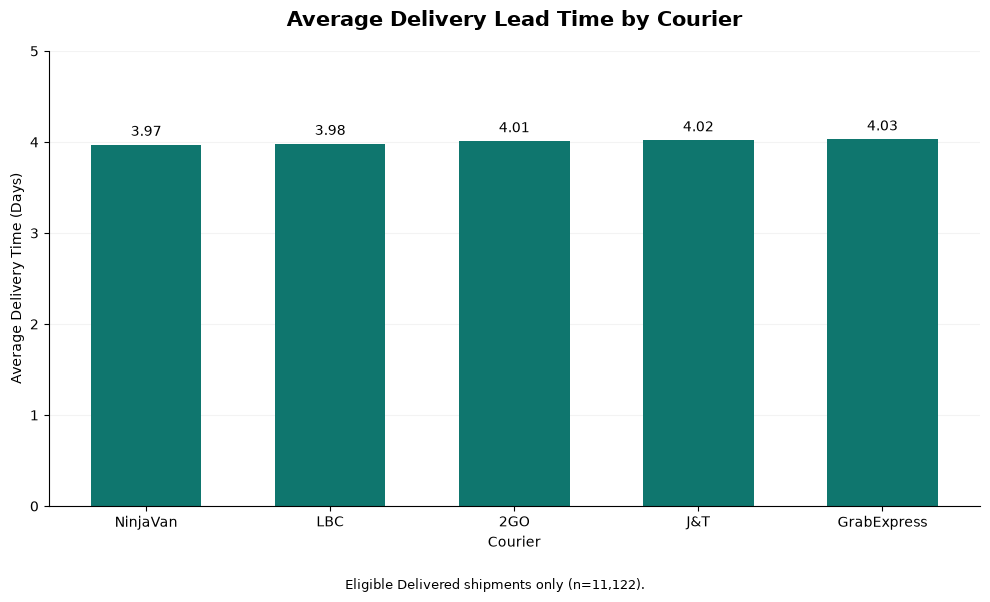

Chart saved: /Users/imacm3/Documents/Python-Learning/Python-Capstone-Option-B/Outputs/Charts/courier_average_delivery_days.png
File exists: True


In [75]:
# ============================================================
# NOTEBOOK CELL 073 — EXPORT COURIER AVERAGE DELIVERY CHART
# ============================================================
# PURPOSE: Create and save a bar chart comparing recorded courier mean durations.
# INPUT: `shipments`, `courier_performance`.
# OUTPUT: `chart_folder`, `(fig, ax)`, `bars`, `chart_path`.
# DATA SAFETY: Writes a new output artifact under Outputs; does not edit source CSV data.
# ANALYTICAL NOTE: Chart is descriptive; do not label a courier objectively best.
# ============================================================

# SECTION — REQUIRED LIBRARIES
# Create portable folder paths and manage exported files.
from pathlib import Path

# SECTION — REQUIRED LIBRARIES
# Create publication-ready analytical charts.
import matplotlib.pyplot as plt

# Set chart_folder to the project-relative output location.
chart_folder = Path.cwd() / "Outputs" / "Charts"

# Create the required output folder without failing if it already exists.
chart_folder.mkdir(parents=True, exist_ok=True)

# Create or update (fig, ax) using the immediately preceding source variables.
fig, ax = plt.subplots(figsize=(10, 6))

# Create or update bars using the immediately preceding source variables.
bars = ax.bar(
    courier_performance.index,
    courier_performance["average_days"],
    color="#0F766E",
    width=0.6
)

# Evaluate the expression and display its result for diagnostic inspection.
ax.bar_label(bars, fmt="%.2f", padding=4)

# Evaluate the expression and display its result for diagnostic inspection.
ax.set_title(
    "Average Delivery Lead Time by Courier",
    fontsize=15,
    fontweight="bold",
    pad=18
)

# Evaluate the expression and display its result for diagnostic inspection.
ax.set_xlabel("Courier")

# Evaluate the expression and display its result for diagnostic inspection.
ax.set_ylabel("Average Delivery Time (Days)")

# Evaluate the expression and display its result for diagnostic inspection.
ax.set_ylim(0, 5)

# Evaluate the expression and display its result for diagnostic inspection.
ax.spines["top"].set_visible(False)

# Evaluate the expression and display its result for diagnostic inspection.
ax.spines["right"].set_visible(False)

# Evaluate the expression and display its result for diagnostic inspection.
ax.grid(axis="y", alpha=0.15)

# Evaluate the expression and display its result for diagnostic inspection.
ax.set_axisbelow(True)

# Evaluate the expression and display its result for diagnostic inspection.
fig.text(
    0.5, 0.01,
    "Eligible Delivered shipments only (n=11,122).",
    ha="center",
    fontsize=9
)

# Evaluate the expression and display its result for diagnostic inspection.
fig.tight_layout(rect=[0, 0.05, 1, 1])

# Create or update chart_path using the immediately preceding source variables.
chart_path = chart_folder / "courier_average_delivery_days.png"

# SECTION — EXPORT OUTPUT
# Write the chart image to the dedicated Outputs/Charts folder.
fig.savefig(
    chart_path,
    dpi=300,
    bbox_inches="tight"
)

# Display the completed figure in the Jupyter notebook.
plt.show()

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("Chart saved:", chart_path)
print("File exists:", chart_path.exists())

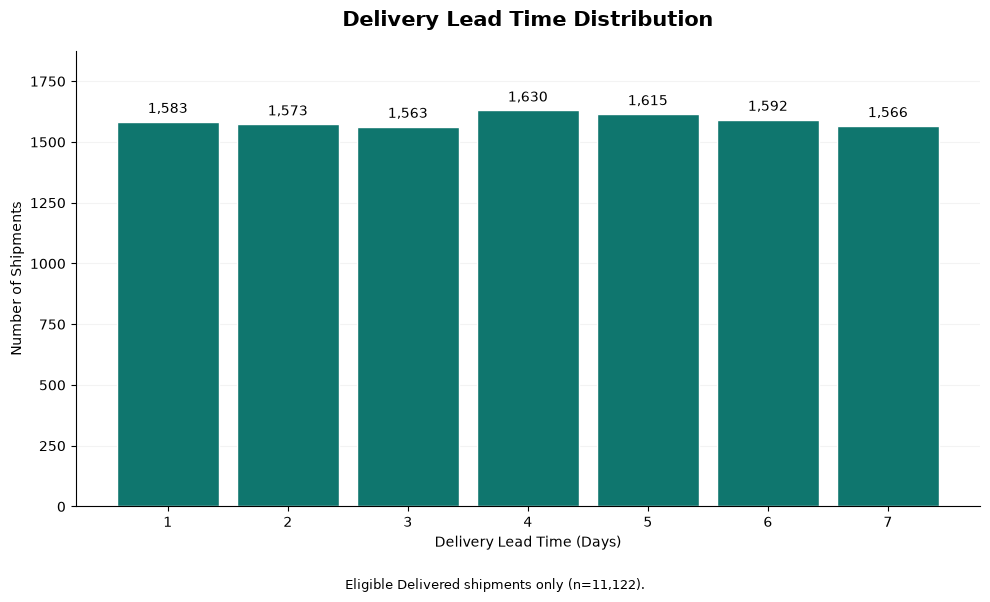

Histogram total: 11122
Matches Step 73: True
Chart saved: /Users/imacm3/Documents/Python-Learning/Python-Capstone-Option-B/Outputs/Charts/delivery_lead_time_histogram.png
File exists: True


In [76]:
# ============================================================
# NOTEBOOK CELL 074 — EXPORT DELIVERY LEAD-TIME HISTOGRAM
# ============================================================
# PURPOSE: Plot distribution of eligible recorded ship-to-delivery durations.
# INPUT: `shipments`, `shipments_clean`.
# OUTPUT: `eligible_lead_times`, `(fig, ax)`, `(counts, bin_edges, bars)`, `histogram_path`.
# DATA SAFETY: Writes a new output artifact under Outputs; does not edit source CSV data.
# ANALYTICAL NOTE: Highlight sample size and data-quality limitations for interpretation.
# ============================================================

# SECTION — REQUIRED LIBRARIES
# Use numerical helpers and Boolean classification functions.
import numpy as np

# SECTION — REQUIRED LIBRARIES
# Create publication-ready analytical charts.
import matplotlib.pyplot as plt

# Select the qualified records or column values into eligible_lead_times without deleting source rows.
eligible_lead_times = shipments_clean.loc[
    shipments_clean["lead_time_eligible"],
    "lead_time_days"
].dropna()

# Create or update (fig, ax) using the immediately preceding source variables.
fig, ax = plt.subplots(figsize=(10, 6))

# Create or update (counts, bin_edges, bars) using the immediately preceding source variables.
counts, bin_edges, bars = ax.hist(
    eligible_lead_times,
    bins=np.arange(0.5, 8.5, 1),
    color="#0F766E",
    edgecolor="white",
    rwidth=0.85
)

# Evaluate the expression and display its result for diagnostic inspection.
ax.bar_label(
    bars,
    labels=[f"{int(count):,}" for count in counts],
    padding=4,
    fontsize=10
)

# Evaluate the expression and display its result for diagnostic inspection.
ax.set_title(
    "Delivery Lead Time Distribution",
    fontsize=15,
    fontweight="bold",
    pad=18
)

# Evaluate the expression and display its result for diagnostic inspection.
ax.set_xlabel("Delivery Lead Time (Days)")

# Evaluate the expression and display its result for diagnostic inspection.
ax.set_ylabel("Number of Shipments")

# Evaluate the expression and display its result for diagnostic inspection.
ax.set_xticks(range(1, 8))

# Evaluate the expression and display its result for diagnostic inspection.
ax.set_ylim(0, max(counts) * 1.15)

# Evaluate the expression and display its result for diagnostic inspection.
ax.spines["top"].set_visible(False)

# Evaluate the expression and display its result for diagnostic inspection.
ax.spines["right"].set_visible(False)

# Evaluate the expression and display its result for diagnostic inspection.
ax.grid(axis="y", alpha=0.15)

# Evaluate the expression and display its result for diagnostic inspection.
ax.set_axisbelow(True)

# Evaluate the expression and display its result for diagnostic inspection.
fig.text(
    0.5, 0.01,
    "Eligible Delivered shipments only (n=11,122).",
    ha="center",
    fontsize=9
)

# Evaluate the expression and display its result for diagnostic inspection.
fig.tight_layout(rect=[0, 0.05, 1, 1])

# Create or update histogram_path using the immediately preceding source variables.
histogram_path = chart_folder / "delivery_lead_time_histogram.png"

# SECTION — EXPORT OUTPUT
# Write the chart image to the dedicated Outputs/Charts folder.
fig.savefig(
    histogram_path,
    dpi=300,
    bbox_inches="tight"
)

# Display the completed figure in the Jupyter notebook.
plt.show()

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("Histogram total:", int(counts.sum()))
print("Matches Step 73:",
      np.array_equal(
          counts.astype(int),
          lead_time_distribution.values
      ))
print("Chart saved:", histogram_path)
print("File exists:", histogram_path.exists())

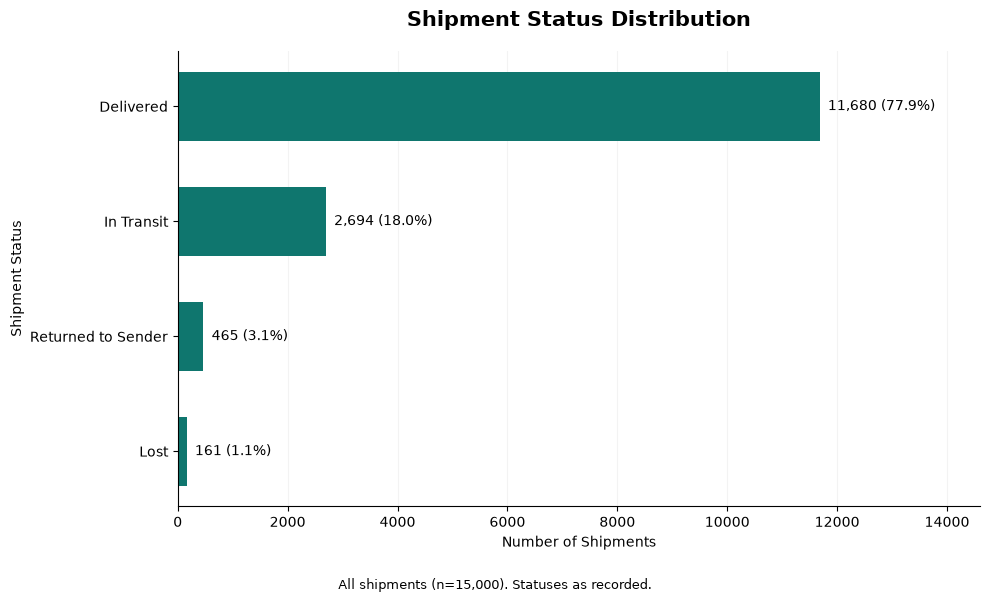

Status categories: 4
Total charted shipments: 15000
Matches shipment total: True
Chart saved: /Users/imacm3/Documents/Python-Learning/Python-Capstone-Option-B/Outputs/Charts/shipment_status_distribution.png
File exists: True


In [77]:
# ============================================================
# NOTEBOOK CELL 075 — EXPORT SHIPMENT STATUS DISTRIBUTION CHART
# ============================================================
# PURPOSE: Visualize shipment status counts and percentages.
# INPUT: `shipments`, `shipments_clean`.
# OUTPUT: `status_counts`, `(fig, ax)`, `bars`, `labels`, `status_chart_path`.
# DATA SAFETY: Writes a new output artifact under Outputs; does not edit source CSV data.
# ANALYTICAL NOTE: Recorded statuses may conflict with presence of delivery dates.
# ============================================================

# Count distinct labels or values in status_counts to understand distribution.
status_counts = (
    shipments_clean["shipment_status"]
    .value_counts()
    .sort_values()
)

# Create or update (fig, ax) using the immediately preceding source variables.
fig, ax = plt.subplots(figsize=(10, 6))

# Create or update bars using the immediately preceding source variables.
bars = ax.barh(
    status_counts.index,
    status_counts.values,
    color="#0F766E",
    height=0.6
)

# Create or update labels using the immediately preceding source variables.
labels = [
    f"{count:,} ({count / len(shipments_clean):.1%})"
    for count in status_counts.values
]

# Evaluate the expression and display its result for diagnostic inspection.
ax.bar_label(
    bars,
    labels=labels,
    padding=6,
    fontsize=10
)

# Evaluate the expression and display its result for diagnostic inspection.
ax.set_title(
    "Shipment Status Distribution",
    fontsize=15,
    fontweight="bold",
    pad=18
)

# Evaluate the expression and display its result for diagnostic inspection.
ax.set_xlabel("Number of Shipments")

# Evaluate the expression and display its result for diagnostic inspection.
ax.set_ylabel("Shipment Status")

# Evaluate the expression and display its result for diagnostic inspection.
ax.set_xlim(0, status_counts.max() * 1.25)

# Evaluate the expression and display its result for diagnostic inspection.
ax.spines["top"].set_visible(False)

# Evaluate the expression and display its result for diagnostic inspection.
ax.spines["right"].set_visible(False)

# Evaluate the expression and display its result for diagnostic inspection.
ax.grid(axis="x", alpha=0.15)

# Evaluate the expression and display its result for diagnostic inspection.
ax.set_axisbelow(True)

# Evaluate the expression and display its result for diagnostic inspection.
fig.text(
    0.5, 0.01,
    "All shipments (n=15,000). Statuses as recorded.",
    ha="center",
    fontsize=9
)

# Evaluate the expression and display its result for diagnostic inspection.
fig.tight_layout(rect=[0, 0.05, 1, 1])

# Create or update status_chart_path using the immediately preceding source variables.
status_chart_path = (
    chart_folder / "shipment_status_distribution.png"
)

# SECTION — EXPORT OUTPUT
# Write the chart image to the dedicated Outputs/Charts folder.
fig.savefig(
    status_chart_path,
    dpi=300,
    bbox_inches="tight"
)

# Display the completed figure in the Jupyter notebook.
plt.show()

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("Status categories:", status_counts.size)
print("Total charted shipments:", status_counts.sum())
print("Matches shipment total:",
      status_counts.sum() == len(shipments_clean))
print("Chart saved:", status_chart_path)
print("File exists:", status_chart_path.exists())

In [78]:
# ============================================================
# NOTEBOOK CELL 076 — PROFILE RETURNS DATASET AND REASON FIELDS
# ============================================================
# PURPOSE: Inspect available return fields, missing values, and reason labels.
# INPUT: `returns_clean`.
# OUTPUT: `reason_columns`.
# DATA SAFETY: Read-only or new in-memory objects; original input CSVs remain unchanged.
# ANALYTICAL NOTE: Understand return records before calculating return reasons.
# ============================================================

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("RETURN DATASET PROFILE")

print("\nTotal return records:")
print(len(returns_clean))

print("\nAvailable columns:")
print(returns_clean.columns.tolist())

# Create or update reason_columns using the immediately preceding source variables.
reason_columns = returns_clean.columns[
    returns_clean.columns.str.contains(
        "reason",
        case=False
    )
]

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("\nReason columns found:")
print(reason_columns.tolist())

# Run the following branch only when the stated validation condition is satisfied.
if len(reason_columns) == 1:
    reason_col = reason_columns[0]

    print("\nReturn reason distribution:")
    print(
        returns_clean[reason_col].value_counts(
            dropna=False
        )
    )

    print("\nMissing return reasons:")
    print(returns_clean[reason_col].isna().sum())

    print("\nUnique non-missing reasons:")
    print(returns_clean[reason_col].nunique())

else:
    print("\nReview the column names before proceeding.")

RETURN DATASET PROFILE

Total return records:
1200

Available columns:
['return_id', 'order_id', 'return_request_date', 'reason', 'refunded_flag', 'refund_amount', 'refund_review_required', 'refunded_flag_clean', 'refund_amount_missing', 'refund_amount_candidate', 'refund_zero_amount_review', 'order_id_unmatched']

Reason columns found:
['reason']

Return reason distribution:
reason
Changed mind     182
Defective        178
Missing parts    175
Size issue       174
Late delivery    169
Wrong item       162
Damaged item     160
Name: count, dtype: int64

Missing return reasons:
0

Unique non-missing reasons:
7


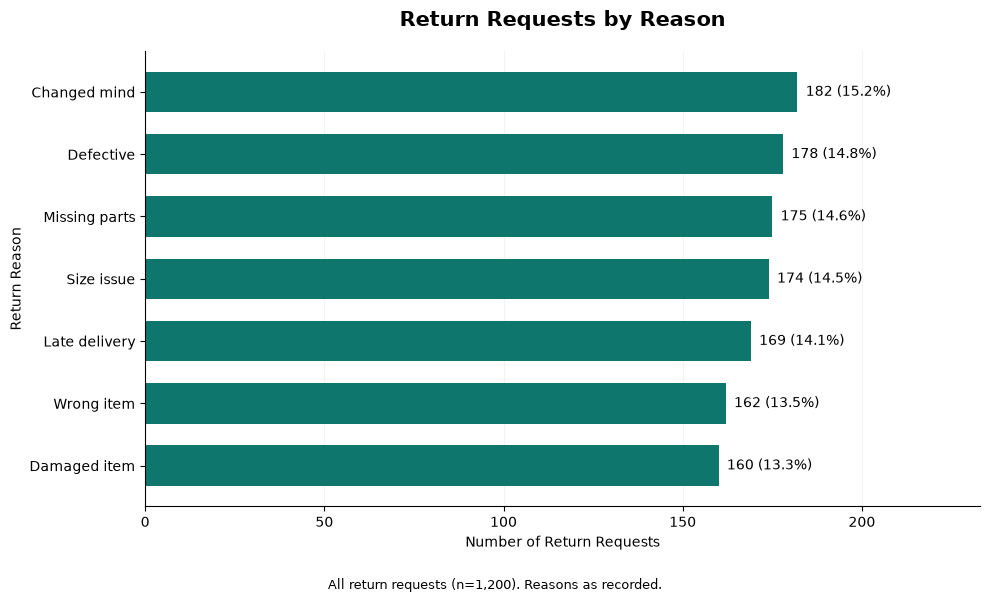

Total return requests: 1200
Total charted requests: 1200
Number of reasons: 7
Matches return total: True
Chart saved: /Users/imacm3/Documents/Python-Learning/Python-Capstone-Option-B/Outputs/Charts/return_reasons_distribution.png
File exists: True


In [79]:
# ============================================================
# NOTEBOOK CELL 077 — EXPORT RETURN REASON DISTRIBUTION CHART
# ============================================================
# PURPOSE: Rank return reasons and export an explanatory bar chart.
# INPUT: `returns_clean`.
# OUTPUT: `return_reason_counts`, `(fig, ax)`, `bars`, `labels`, `return_reasons_path`.
# DATA SAFETY: Writes a new output artifact under Outputs; does not edit source CSV data.
# ANALYTICAL NOTE: Reasons describe recorded return requests, not confirmed defects.
# ============================================================

# Count distinct labels or values in return_reason_counts to understand distribution.
return_reason_counts = (
    returns_clean["reason"]
    .value_counts()
    .sort_values()
)

# Create or update (fig, ax) using the immediately preceding source variables.
fig, ax = plt.subplots(figsize=(10, 6))

# Create or update bars using the immediately preceding source variables.
bars = ax.barh(
    return_reason_counts.index,
    return_reason_counts.values,
    color="#0F766E",
    height=0.65
)

# Create or update labels using the immediately preceding source variables.
labels = [
    f"{count:,} ({count / len(returns_clean):.1%})"
    for count in return_reason_counts.values
]

# Evaluate the expression and display its result for diagnostic inspection.
ax.bar_label(
    bars,
    labels=labels,
    padding=6,
    fontsize=10
)

# Evaluate the expression and display its result for diagnostic inspection.
ax.set_title(
    "Return Requests by Reason",
    fontsize=15,
    fontweight="bold",
    pad=18
)

# Evaluate the expression and display its result for diagnostic inspection.
ax.set_xlabel("Number of Return Requests")

# Evaluate the expression and display its result for diagnostic inspection.
ax.set_ylabel("Return Reason")

# Evaluate the expression and display its result for diagnostic inspection.
ax.set_xlim(0, return_reason_counts.max() * 1.28)

# Evaluate the expression and display its result for diagnostic inspection.
ax.spines["top"].set_visible(False)

# Evaluate the expression and display its result for diagnostic inspection.
ax.spines["right"].set_visible(False)

# Evaluate the expression and display its result for diagnostic inspection.
ax.grid(axis="x", alpha=0.15)

# Evaluate the expression and display its result for diagnostic inspection.
ax.set_axisbelow(True)

# Evaluate the expression and display its result for diagnostic inspection.
fig.text(
    0.5, 0.01,
    "All return requests (n=1,200). Reasons as recorded.",
    ha="center",
    fontsize=9
)

# Evaluate the expression and display its result for diagnostic inspection.
fig.tight_layout(rect=[0, 0.05, 1, 1])

# Create or update return_reasons_path using the immediately preceding source variables.
return_reasons_path = (
    chart_folder / "return_reasons_distribution.png"
)

# SECTION — EXPORT OUTPUT
# Write the chart image to the dedicated Outputs/Charts folder.
fig.savefig(
    return_reasons_path,
    dpi=300,
    bbox_inches="tight"
)

# Display the completed figure in the Jupyter notebook.
plt.show()

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("Total return requests:",
      len(returns_clean))

print("Total charted requests:",
      return_reason_counts.sum())

print("Number of reasons:",
      return_reason_counts.size)

print("Matches return total:",
      return_reason_counts.sum() == len(returns_clean))

print("Chart saved:", return_reasons_path)
print("File exists:", return_reasons_path.exists())

In [80]:
# ============================================================
# NOTEBOOK CELL 078 — CREATE DISTINCT ORDER-CATEGORY ASSOCIATIONS
# ============================================================
# PURPOSE: Build unique order/category pairs and mark orders with a return request.
# INPUT: `orders`, `orders_clean`, `returns_clean`, `order_items_reporting`.
# OUTPUT: `order_category_pairs`, `order_category_pairs['has_return_request']`.
# DATA SAFETY: Read-only or new in-memory objects; original input CSVs remain unchanged.
# ANALYTICAL NOTE: A returned order can involve several categories; not item-level attribution.
# ============================================================

# Create order_category_pairs by removing verified exact duplicate rows.
order_category_pairs = (
    order_items_reporting[
        ["order_id", "category_reporting"]
    ]
    .drop_duplicates()
    .copy()
)

# Use membership checks to construct order_category_pairs['has_return_request']; unmatched identifiers remain visible.
order_category_pairs["has_return_request"] = (
    order_category_pairs["order_id"].isin(
        returns_clean["order_id"]
    )
)

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("Original order-item records:",
      len(order_items_reporting))

print("Unique order-category pairs:",
      len(order_category_pairs))

print("Unique orders represented:",
      order_category_pairs["order_id"].nunique())

print("Total orders:",
      len(orders_clean))

print("Orders without order-item records:",
      (
          ~orders_clean["order_id"].isin(
              order_category_pairs["order_id"]
          )
      ).sum())

print("Unique orders with return requests:",
      returns_clean["order_id"].nunique())

print("Return orders without category pairs:",
      (
          ~returns_clean["order_id"].isin(
              order_category_pairs["order_id"]
          )
      ).sum())

print("Duplicate order-category pairs:",
      order_category_pairs.duplicated(
          subset=["order_id", "category_reporting"]
      ).sum())

print("Unknown category pairs:",
      (
          order_category_pairs["category_reporting"]
          == "Unknown / Unmapped"
      ).sum())

print("Orders associated with multiple categories:",
      (
          order_category_pairs.groupby("order_id")[
              "category_reporting"
          ].nunique() > 1
      ).sum())

print("Return-request orders represented:",
      order_category_pairs.loc[
          order_category_pairs["has_return_request"],
          "order_id"
      ].nunique())

Original order-item records: 37501
Unique order-category pairs: 33165
Unique orders represented: 15000
Total orders: 15000
Orders without order-item records: 0
Unique orders with return requests: 1200
Return orders without category pairs: 0
Duplicate order-category pairs: 0
Unknown category pairs: 129
Orders associated with multiple categories: 11033
Return-request orders represented: 1200


In [81]:
# ============================================================
# NOTEBOOK CELL 079 — CALCULATE CATEGORY-ASSOCIATED RETURN RATES
# ============================================================
# PURPOSE: Compute return-request percentages using order/category associations.
# INPUT: `orders`, `category_return_rates`.
# OUTPUT: `category_return_rates`, `category_return_rates['return_request_rate_pct']`.
# DATA SAFETY: Read-only or new in-memory objects; original input CSVs remain unchanged.
# ANALYTICAL NOTE: Do not sum category-return counts as unique returned orders.
# ============================================================

# Aggregate grouped records into category_return_rates; interpret using correct denominators.
category_return_rates = (
    order_category_pairs
    .groupby("category_reporting")
    .agg(
        orders_containing_category=("order_id", "nunique"),
        orders_with_return_request=("has_return_request", "sum")
    )
)

# Create or update category_return_rates['return_request_rate_pct'] using the immediately preceding source variables.
category_return_rates["return_request_rate_pct"] = (
    category_return_rates["orders_with_return_request"]
    / category_return_rates["orders_containing_category"]
    * 100
)

# Sort category_return_rates so the comparison can be interpreted in ranked order.
category_return_rates = (
    category_return_rates
    .sort_values(
        "return_request_rate_pct",
        ascending=False
    )
    .round(2)
)

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("CATEGORY-ASSOCIATED RETURN REQUEST RATES:")
print(category_return_rates.to_string())

print("\nCategory-order associations accounted for:",
      category_return_rates["orders_containing_category"].sum())

print("Original unique order-category pairs:",
      len(order_category_pairs))

print("Unique orders represented:",
      order_category_pairs["order_id"].nunique())

print("Unique return-request orders represented:",
      order_category_pairs.loc[
          order_category_pairs["has_return_request"],
          "order_id"
      ].nunique())

print("Number of reporting categories:",
      len(category_return_rates))

print("All rates within 0-100%:",
      category_return_rates["return_request_rate_pct"]
      .between(0, 100)
      .all())

CATEGORY-ASSOCIATED RETURN REQUEST RATES:
                    orders_containing_category  orders_with_return_request  return_request_rate_pct
category_reporting                                                                                 
Home & Kitchen                            4076                         352                     8.64
Fashion                                   4050                         341                     8.42
Sports                                    3433                         283                     8.24
Beauty                                    4279                         351                     8.20
Books                                     4440                         347                     7.82
Electronics                               4710                         363                     7.71
Toys                                      4334                         329                     7.59
Groceries                                 3714            

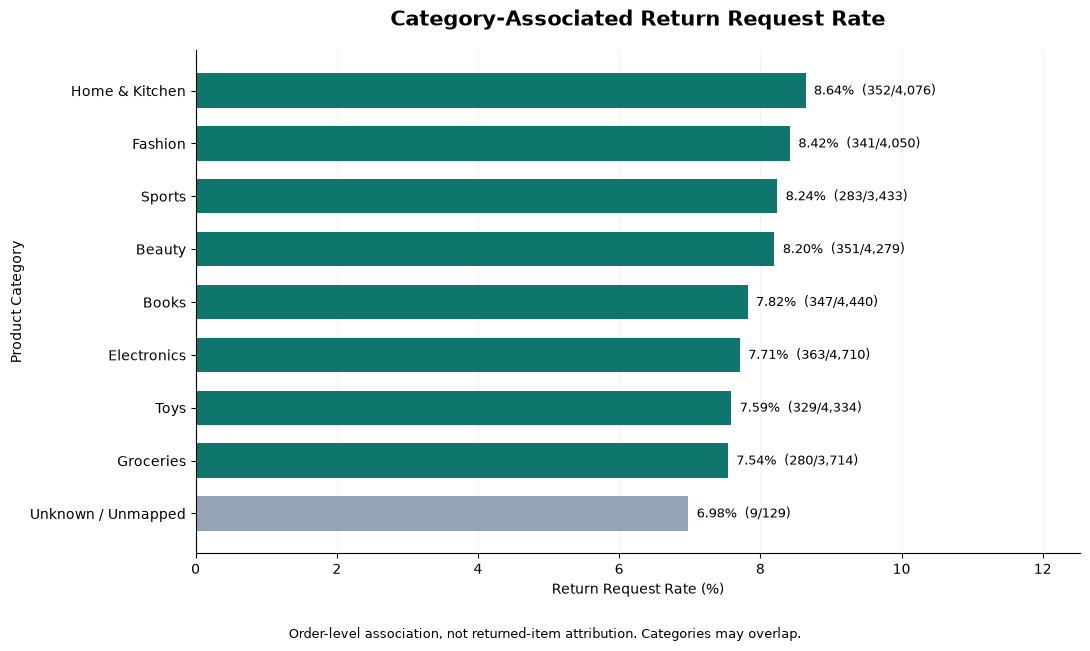

Categories charted: 9
Category-order associations: 33165
Matches source pairs: True
All rates within 0-100%: True
Chart saved: /Users/imacm3/Documents/Python-Learning/Python-Capstone-Option-B/Outputs/Charts/category_return_request_rate.png
File exists: True


In [82]:
# ============================================================
# NOTEBOOK CELL 080 — EXPORT CATEGORY RETURN-RATE CHART
# ============================================================
# PURPOSE: Visualize the category-associated return request rate.
# INPUT: `category_return_rates`.
# OUTPUT: `category_chart_data`, `bar_colors`, `(fig, ax)`, `bars`, `labels`, `...`.
# DATA SAFETY: Writes a new output artifact under Outputs; does not edit source CSV data.
# ANALYTICAL NOTE: Mark Unknown / Unmapped explicitly and avoid false item attribution.
# ============================================================

# Create a working copy in category_chart_data to preserve previous DataFrame values.
category_chart_data = (
    category_return_rates
    .sort_values("return_request_rate_pct")
    .copy()
)

# Calculate bar_colors from an explicit comparison; this flags records for review.
bar_colors = [
    "#94A3B8" if category == "Unknown / Unmapped"
    else "#0F766E"
    for category in category_chart_data.index
]

# Create or update (fig, ax) using the immediately preceding source variables.
fig, ax = plt.subplots(figsize=(11, 6.5))

# Create or update bars using the immediately preceding source variables.
bars = ax.barh(
    category_chart_data.index,
    category_chart_data["return_request_rate_pct"],
    color=bar_colors,
    height=0.65
)

# Create or update labels using the immediately preceding source variables.
labels = [
    f"{rate:.2f}%  ({returned:,}/{total:,})"
    for rate, returned, total in zip(
        category_chart_data["return_request_rate_pct"],
        category_chart_data["orders_with_return_request"],
        category_chart_data["orders_containing_category"]
    )
]

# Evaluate the expression and display its result for diagnostic inspection.
ax.bar_label(
    bars,
    labels=labels,
    padding=6,
    fontsize=9
)

# Evaluate the expression and display its result for diagnostic inspection.
ax.set_title(
    "Category-Associated Return Request Rate",
    fontsize=15,
    fontweight="bold",
    pad=18
)

# Evaluate the expression and display its result for diagnostic inspection.
ax.set_xlabel("Return Request Rate (%)")

# Evaluate the expression and display its result for diagnostic inspection.
ax.set_ylabel("Product Category")

# Evaluate the expression and display its result for diagnostic inspection.
ax.set_xlim(
    0,
    category_chart_data["return_request_rate_pct"].max() * 1.45
)

# Evaluate the expression and display its result for diagnostic inspection.
ax.spines["top"].set_visible(False)

# Evaluate the expression and display its result for diagnostic inspection.
ax.spines["right"].set_visible(False)

# Evaluate the expression and display its result for diagnostic inspection.
ax.grid(axis="x", alpha=0.15)

# Evaluate the expression and display its result for diagnostic inspection.
ax.set_axisbelow(True)

# Evaluate the expression and display its result for diagnostic inspection.
fig.text(
    0.5, 0.01,
    "Order-level association, not returned-item attribution. "
    "Categories may overlap.",
    ha="center",
    fontsize=9
)

# Evaluate the expression and display its result for diagnostic inspection.
fig.tight_layout(rect=[0, 0.05, 1, 1])

# Create or update category_chart_path using the immediately preceding source variables.
category_chart_path = (
    chart_folder / "category_return_request_rate.png"
)

# SECTION — EXPORT OUTPUT
# Write the chart image to the dedicated Outputs/Charts folder.
fig.savefig(
    category_chart_path,
    dpi=300,
    bbox_inches="tight"
)

# Display the completed figure in the Jupyter notebook.
plt.show()

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("Categories charted:", len(category_chart_data))

print("Category-order associations:",
      category_chart_data["orders_containing_category"].sum())

print("Matches source pairs:",
      category_chart_data["orders_containing_category"].sum()
      == len(order_category_pairs))

print("All rates within 0-100%:",
      category_chart_data["return_request_rate_pct"]
      .between(0, 100)
      .all())

print("Chart saved:", category_chart_path)
print("File exists:", category_chart_path.exists())

### Historical debugging note — invalid column name (not executable)

This original diagnostic cell raised **`KeyError: 'order_date'`**, because the orders table has a column named **`order_datetime`**, not `order_date`. The original code is retained below for learning and audit history. It is intentionally **not executed** during **Run All**. The following notebook cells discover the correct schema and use `order_datetime`.

```python
# ============================================================
# NOTEBOOK CELL 081 — HISTORICAL FAILED ORDER-DATE COLUMN CHECK
# ============================================================
# PURPOSE: Preserve the earlier inspection attempt using a nonexistent order_date field.
# INPUT: `orders`, `orders_clean`.
# OUTPUT: `order_date_patterns`.
# DATA SAFETY: Read-only or new in-memory objects; original input CSVs remain unchanged.
# ANALYTICAL NOTE: This cell originally raised a KeyError; next cell diagnoses real schema.
# ============================================================

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("ORDER DATE PROFILE")

print("\nTotal orders:")
print(len(orders_clean))

print("\nOrder Date data type:")
print(orders_clean["order_date"].dtype)

print("\nMissing Order Dates:")
print(orders_clean["order_date"].isna().sum())

print("\nSample Order Dates:")
print(orders_clean["order_date"].head(10).to_string(index=False))

# Count distinct labels or values in order_date_patterns to understand distribution.
order_date_patterns = (
    orders_clean["order_date"]
    .astype("string")
    .str.replace(r"\d", "9", regex=True)
    .value_counts(dropna=False)
)

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("\nOrder Date Format Patterns:")
print(order_date_patterns.to_string())

print("\nTotal records in pattern profile:")
print(order_date_patterns.sum())
```

**Original observed result:** `KeyError: 'order_date'`.


In [83]:
# ============================================================
# NOTEBOOK CELL 082 — FIND ACTUAL ORDER DATE-TIME COLUMN
# ============================================================
# PURPOSE: Print exact Orders fields and look for date/time names.
# INPUT: `orders`, `orders_clean`.
# OUTPUT: Printed tables, charts, or diagnostic summaries; no assigned object.
# DATA SAFETY: Read-only or new in-memory objects; original input CSVs remain unchanged.
# ANALYTICAL NOTE: Schema inspection prevents repeating the order_date naming mistake.
# ============================================================

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("ACTUAL ORDERS COLUMN NAMES:")

# Iterate over observed values or column names to profile each case without altering source records.
for column in orders_clean.columns:
    print(repr(column))

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("\nPOSSIBLE DATE/TIME COLUMNS:")

# Iterate over observed values or column names to profile each case without altering source records.
for column in orders_clean.columns:
    if "date" in column.lower() or "time" in column.lower():
        print(column)

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("\nTotal orders:", len(orders_clean))

ACTUAL ORDERS COLUMN NAMES:
'order_id'
'customer_id'
'order_datetime'
'order_status'
'sales_channel'
'shipping_method'
'discount_pct'
'shipping_fee'
'shipping_fee_missing'
'discount_pct_missing'
'customer_id_unmatched'

POSSIBLE DATE/TIME COLUMNS:
order_datetime

Total orders: 15000


In [84]:
# ============================================================
# NOTEBOOK CELL 083 — PROFILE RAW ORDER TIMESTAMP FORMATS
# ============================================================
# PURPOSE: Count patterns, missing values, and data types for order_datetime.
# INPUT: `orders`, `orders_clean`.
# OUTPUT: `order_datetime_patterns`.
# DATA SAFETY: Read-only or new in-memory objects; original input CSVs remain unchanged.
# ANALYTICAL NOTE: Date conversion should use observed source formats.
# ============================================================

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("ORDER DATETIME PROFILE")

print("\nTotal orders:")
print(len(orders_clean))

print("\nOrder Datetime data type:")
print(orders_clean["order_datetime"].dtype)

print("\nMissing Order Datetimes:")
print(orders_clean["order_datetime"].isna().sum())

print("\nSample Order Datetimes:")
print(
    orders_clean["order_datetime"]
    .head(10)
    .to_string(index=False)
)

# Count distinct labels or values in order_datetime_patterns to understand distribution.
order_datetime_patterns = (
    orders_clean["order_datetime"]
    .astype("string")
    .str.replace(r"\d", "9", regex=True)
    .value_counts(dropna=False)
)

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("\nOrder Datetime Format Patterns:")
print(order_datetime_patterns.to_string())

print("\nTotal records in pattern profile:")
print(order_datetime_patterns.sum())

ORDER DATETIME PROFILE

Total orders:
15000

Order Datetime data type:
str

Missing Order Datetimes:
0

Sample Order Datetimes:
2025-11-07 17:02:00
09/18/2025 09:13 AM
2025-08-08 04:59:00
2025-10-14 12:56:00
2024-05-30 04:56:00
2024-08-13 18:42:00
2025-08-11 23:17:00
03/25/2024 10:47 AM
2024-09-28 02:01:00
2024-09-17 05:31:00

Order Datetime Format Patterns:
order_datetime
9999-99-99 99:99:99    11688
99/99/9999 99:99 AM      915
99/99/9999 99:99 PM      892
99-Jan-9999 99:99        163
99-Apr-9999 99:99        136
99-Jul-9999 99:99        132
99-Oct-9999 99:99        132
99-Mar-9999 99:99        130
99-Aug-9999 99:99        128
99-Jun-9999 99:99        127
99-May-9999 99:99        121
99-Nov-9999 99:99        116
99-Dec-9999 99:99        114
99-Feb-9999 99:99        105
99-Sep-9999 99:99        101

Total records in pattern profile:
15000


In [85]:
# ============================================================
# NOTEBOOK CELL 084 — PARSE MIXED ORDER DATE-TIME FORMATS
# ============================================================
# PURPOSE: Convert ISO, US AM/PM, and day-month English order timestamps.
# INPUT: `orders`, `orders_clean`.
# OUTPUT: `order_iso`, `order_us`, `order_english`, `orders_clean['order_datetime_parsed']`.
# DATA SAFETY: Updates derived fields only in working table(s): orders_clean. Original input CSVs remain untouched.
# ANALYTICAL NOTE: Preserve original text and validate conversion completeness.
# ============================================================

# Parse dates into order_iso using the stated format; coercion exposes nonmatching inputs.
order_iso = pd.to_datetime(
    orders_clean["order_datetime"],
    format="%Y-%m-%d %H:%M:%S",
    errors="coerce"
)

# Parse dates into order_us using the stated format; coercion exposes nonmatching inputs.
order_us = pd.to_datetime(
    orders_clean["order_datetime"],
    format="%m/%d/%Y %I:%M %p",
    errors="coerce"
)

# Parse dates into order_english using the stated format; coercion exposes nonmatching inputs.
order_english = pd.to_datetime(
    orders_clean["order_datetime"],
    format="%d-%b-%Y %H:%M",
    errors="coerce"
)

# Create or update orders_clean['order_datetime_parsed'] using the immediately preceding source variables.
orders_clean["order_datetime_parsed"] = (
    order_iso
    .fillna(order_us)
    .fillna(order_english)
)

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("Original missing datetimes:",
      orders_clean["order_datetime"].isna().sum())

print("Parsed missing datetimes:",
      orders_clean["order_datetime_parsed"].isna().sum())

print("New conversion failures:",
      (
          orders_clean["order_datetime"].notna()
          & orders_clean["order_datetime_parsed"].isna()
      ).sum())

print("ISO format converted:", order_iso.notna().sum())

print("US AM/PM format converted:", order_us.notna().sum())

print("English month format converted:",
      order_english.notna().sum())

print("Parsed data type:",
      orders_clean["order_datetime_parsed"].dtype)

print("Total orders:", len(orders_clean))

Original missing datetimes: 0
Parsed missing datetimes: 0
New conversion failures: 0
ISO format converted: 11688
US AM/PM format converted: 1807
English month format converted: 1505
Parsed data type: datetime64[us]
Total orders: 15000


In [86]:
# ============================================================
# NOTEBOOK CELL 085 — AUDIT ORDER-TO-SHIPPING CHRONOLOGY
# ============================================================
# PURPOSE: Join orders to shipments and classify ship-before/same/after order dates.
# INPUT: `orders`, `shipments`, `orders_clean`, `shipments_clean`, `order_ship_audit`.
# OUTPUT: `order_ship_audit`, `order_ship_audit['order_calendar_date']`, `order_ship_audit['ship_before_order']`, `order_ship_audit['ship_same_day']`, `order_ship_audit['ship_after_order']`.
# DATA SAFETY: Read-only or new in-memory objects; original input CSVs remain unchanged.
# ANALYTICAL NOTE: Calendar date comparisons avoid false errors from time-of-day mismatch.
# ============================================================

# Create order_ship_audit by joining rows on explicitly chosen keys; validate join cardinality.
order_ship_audit = shipments_clean[
    ["shipment_id", "order_id", "ship_date_parsed"]
].merge(
    orders_clean[
        ["order_id", "order_datetime_parsed"]
    ],
    on="order_id",
    how="left",
    validate="one_to_one",
    indicator=True
)

# Create or update order_ship_audit['order_calendar_date'] using the immediately preceding source variables.
order_ship_audit["order_calendar_date"] = (
    order_ship_audit["order_datetime_parsed"].dt.normalize()
)

# Calculate order_ship_audit['ship_before_order'] from an explicit comparison; this flags records for review.
order_ship_audit["ship_before_order"] = (
    order_ship_audit["ship_date_parsed"]
    < order_ship_audit["order_calendar_date"]
)

# Calculate order_ship_audit['ship_same_day'] from an explicit comparison; this flags records for review.
order_ship_audit["ship_same_day"] = (
    order_ship_audit["ship_date_parsed"]
    == order_ship_audit["order_calendar_date"]
)

# Calculate order_ship_audit['ship_after_order'] from an explicit comparison; this flags records for review.
order_ship_audit["ship_after_order"] = (
    order_ship_audit["ship_date_parsed"]
    > order_ship_audit["order_calendar_date"]
)

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("ORDER-TO-SHIPPING CHRONOLOGY AUDIT")

print("\nTotal shipment records:",
      len(order_ship_audit))

print("Matched orders:",
      (order_ship_audit["_merge"] == "both").sum())

print("Shipping BEFORE order date:",
      order_ship_audit["ship_before_order"].sum())

print("Shipping SAME DAY as order:",
      order_ship_audit["ship_same_day"].sum())

print("Shipping AFTER order date:",
      order_ship_audit["ship_after_order"].sum())

print("Missing order datetimes:",
      order_ship_audit["order_datetime_parsed"].isna().sum())

print("Missing shipping dates:",
      order_ship_audit["ship_date_parsed"].isna().sum())

print("Chronology categories accounted for:",
      (
          order_ship_audit["ship_before_order"].sum()
          + order_ship_audit["ship_same_day"].sum()
          + order_ship_audit["ship_after_order"].sum()
      ))

print("Original shipments unchanged:",
      len(shipments_clean) == 15000)

ORDER-TO-SHIPPING CHRONOLOGY AUDIT

Total shipment records: 15000
Matched orders: 15000
Shipping BEFORE order date: 7397
Shipping SAME DAY as order: 21
Shipping AFTER order date: 7582
Missing order datetimes: 0
Missing shipping dates: 0
Chronology categories accounted for: 15000
Original shipments unchanged: True


In [87]:
# ============================================================
# NOTEBOOK CELL 086 — VERIFY SHIPPING CHRONOLOGY WITH RAW ISO STRINGS
# ============================================================
# PURPOSE: Compare original ISO date strings without parsed datetime conversions.
# INPUT: `orders_clean`, `shipments_clean`.
# OUTPUT: `raw_date_check`, `iso_order_mask`, `iso_ship_mask`, `raw_iso_pairs`, `raw_iso_pairs['order_date_text']`, `...`.
# DATA SAFETY: Read-only or new in-memory objects; original input CSVs remain unchanged.
# ANALYTICAL NOTE: Raw ISO-to-ISO string ordering independently tests parsing artifacts.
# ============================================================

# Create raw_date_check by joining rows on explicitly chosen keys; validate join cardinality.
raw_date_check = shipments_clean[
    ["order_id", "ship_date"]
].merge(
    orders_clean[
        ["order_id", "order_datetime"]
    ],
    on="order_id",
    how="left",
    validate="one_to_one"
)

# Create iso_order_mask to identify values matching the entire expected date-text pattern.
iso_order_mask = (
    raw_date_check["order_datetime"]
    .str.fullmatch(
        r"\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2}",
        na=False
    )
)

# Create iso_ship_mask to identify values matching the entire expected date-text pattern.
iso_ship_mask = (
    raw_date_check["ship_date"]
    .str.fullmatch(
        r"\d{4}-\d{2}-\d{2}",
        na=False
    )
)

# Select the qualified records or column values into raw_iso_pairs without deleting source rows.
raw_iso_pairs = raw_date_check.loc[
    iso_order_mask & iso_ship_mask
].copy()

# Create or update raw_iso_pairs['order_date_text'] using the immediately preceding source variables.
raw_iso_pairs["order_date_text"] = (
    raw_iso_pairs["order_datetime"].str[:10]
)

# Calculate raw_iso_pairs['ship_before_order_raw'] from an explicit comparison; this flags records for review.
raw_iso_pairs["ship_before_order_raw"] = (
    raw_iso_pairs["ship_date"]
    < raw_iso_pairs["order_date_text"]
)

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("Original ISO-to-ISO records:",
      len(raw_iso_pairs))

print("Shipping BEFORE order (original strings):",
      raw_iso_pairs["ship_before_order_raw"].sum())

print("Shipping BEFORE order percentage:",
      round(
          raw_iso_pairs["ship_before_order_raw"].mean() * 100,
          2
      ))

print("\nEXAMPLES FROM ORIGINAL DATA:")
print(
    raw_iso_pairs.loc[
        raw_iso_pairs["ship_before_order_raw"],
        ["order_id", "order_datetime", "ship_date"]
    ].head(10).to_string(index=False)
)

print("\nOriginal Orders rows:", len(orders_clean))
print("Original Shipments rows:", len(shipments_clean))

Original ISO-to-ISO records: 9912
Shipping BEFORE order (original strings): 4917
Shipping BEFORE order percentage: 49.61

EXAMPLES FROM ORIGINAL DATA:
  order_id      order_datetime  ship_date
ORD0000001 2025-11-07 17:02:00 2025-09-05
ORD0000003 2025-08-08 04:59:00 2025-07-23
ORD0000004 2025-10-14 12:56:00 2025-01-21
ORD0000006 2024-08-13 18:42:00 2024-01-10
ORD0000009 2024-09-28 02:01:00 2024-02-02
ORD0000019 2025-07-08 11:15:00 2024-11-15
ORD0000027 2025-06-16 04:06:00 2024-06-07
ORD0000034 2026-01-05 10:05:00 2025-12-23
ORD0000036 2026-01-25 16:27:00 2024-12-21
ORD0000037 2025-07-27 09:52:00 2024-04-09

Original Orders rows: 15000
Original Shipments rows: 15000


In [88]:
# ============================================================
# NOTEBOOK CELL 087 — CROSS-CHECK RAW AND PARSED ISO CLASSIFICATIONS
# ============================================================
# PURPOSE: Confirm raw ISO date strings and parsed flags agree record by record.
# INPUT: `order_ship_audit`.
# OUTPUT: `iso_verification`, `order_text_from_parsed`, `ship_text_from_parsed`.
# DATA SAFETY: Read-only or new in-memory objects; original input CSVs remain unchanged.
# ANALYTICAL NOTE: Zero disagreement strengthens evidence of source-level chronology issues.
# ============================================================

# Create iso_verification by joining rows on explicitly chosen keys; validate join cardinality.
iso_verification = raw_iso_pairs[
    [
        "order_id",
        "order_datetime",
        "ship_date",
        "ship_before_order_raw"
    ]
].merge(
    order_ship_audit[
        [
            "order_id",
            "order_datetime_parsed",
            "ship_date_parsed",
            "ship_before_order"
        ]
    ],
    on="order_id",
    how="left",
    validate="one_to_one"
)

# Create or update order_text_from_parsed using the immediately preceding source variables.
order_text_from_parsed = (
    iso_verification["order_datetime_parsed"]
    .dt.strftime("%Y-%m-%d %H:%M:%S")
)

# Create or update ship_text_from_parsed using the immediately preceding source variables.
ship_text_from_parsed = (
    iso_verification["ship_date_parsed"]
    .dt.strftime("%Y-%m-%d")
)

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("ISO VERIFICATION RESULTS")

print("\nISO records checked:",
      len(iso_verification))

print("Original Order Date mismatches:",
      (
          iso_verification["order_datetime"]
          != order_text_from_parsed
      ).sum())

print("Original Shipping Date mismatches:",
      (
          iso_verification["ship_date"]
          != ship_text_from_parsed
      ).sum())

print("Original ISO chronology violations:",
      iso_verification["ship_before_order_raw"].sum())

print("Parsed ISO chronology violations:",
      iso_verification["ship_before_order"].sum())

print("Original vs parsed classification disagreements:",
      (
          iso_verification["ship_before_order_raw"]
          != iso_verification["ship_before_order"]
      ).sum())

print("\nRemaining non-ISO pairs:",
      len(order_ship_audit) - len(iso_verification))

print("Chronology violations outside ISO-to-ISO pairs:",
      (
          order_ship_audit["ship_before_order"].sum()
          - iso_verification["ship_before_order"].sum()
      ))

print("All detected chronology violations:",
      order_ship_audit["ship_before_order"].sum())

ISO VERIFICATION RESULTS

ISO records checked: 9912
Original Order Date mismatches: 0
Original Shipping Date mismatches: 0
Original ISO chronology violations: 4917
Parsed ISO chronology violations: 4917
Original vs parsed classification disagreements: 0

Remaining non-ISO pairs: 5088
Chronology violations outside ISO-to-ISO pairs: 2480
All detected chronology violations: 7397


In [89]:
# ============================================================
# NOTEBOOK CELL 088 — INSPECT NEGATIVE ORDER-TO-SHIP GAPS
# ============================================================
# PURPOSE: Measure days shipping precedes order and inspect extreme violations.
# INPUT: `shipments`, `shipments_clean`, `order_ship_audit`.
# OUTPUT: `order_ship_audit['order_to_ship_days']`, `negative_gaps`.
# DATA SAFETY: Read-only or new in-memory objects; original input CSVs remain unchanged.
# ANALYTICAL NOTE: Large negative gaps are material integrity issues, not routine timing noise.
# ============================================================

# Calculate calendar-day differences for order_ship_audit['order_to_ship_days']; confirm timestamp assumptions.
order_ship_audit["order_to_ship_days"] = (
    order_ship_audit["ship_date_parsed"]
    - order_ship_audit["order_calendar_date"]
).dt.days

# Select the qualified records or column values into negative_gaps without deleting source rows.
negative_gaps = order_ship_audit.loc[
    order_ship_audit["ship_before_order"]
].copy()

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("ORDER-TO-SHIPPING GAP INVESTIGATION")

print("\nShipping before order:",
      len(negative_gaps))

print("Percentage of all shipments:",
      round(
          len(negative_gaps) / len(order_ship_audit) * 100,
          2
      ))

print("\nNegative gap statistics (days):")
print(
    negative_gaps["order_to_ship_days"]
    .describe()
    .round(2)
    .to_string()
)

print("\nShipping more than 7 days before order:",
      (negative_gaps["order_to_ship_days"] < -7).sum())

print("\nShipping more than 30 days before order:",
      (negative_gaps["order_to_ship_days"] < -30).sum())

print("\nFive most extreme records:")
print(
    negative_gaps.nsmallest(
        5, "order_to_ship_days"
    )[
        [
            "order_id",
            "order_datetime_parsed",
            "ship_date_parsed",
            "order_to_ship_days"
        ]
    ].to_string(index=False)
)

print("\nTotal audit records:",
      len(order_ship_audit))

print("Original shipments unchanged:",
      len(shipments_clean) == 15000)

ORDER-TO-SHIPPING GAP INVESTIGATION

Shipping before order: 7397
Percentage of all shipments: 49.31

Negative gap statistics (days):
count    7397.00
mean     -256.93
std       179.36
min      -757.00
25%      -386.00
50%      -228.00
75%      -107.00
max        -1.00

Shipping more than 7 days before order: 7273

Shipping more than 30 days before order: 6828

Five most extreme records:
  order_id order_datetime_parsed ship_date_parsed  order_to_ship_days
ORD0012487   2026-01-30 02:48:00       2024-01-04                -757
ORD0013189   2026-01-26 08:37:00       2024-01-02                -755
ORD0014314   2026-01-28 07:40:00       2024-01-15                -744
ORD0000780   2026-01-27 09:05:00       2024-01-17                -741
ORD0013895   2026-01-18 18:01:00       2024-01-08                -741

Total audit records: 15000
Original shipments unchanged: True


In [90]:
# ============================================================
# NOTEBOOK CELL 089 — COMPARE VIOLATIONS ACROSS DATE-FORMAT GROUPS
# ============================================================
# PURPOSE: Profile chronology failure rates by order and shipping format combination.
# INPUT: `orders_clean`, `shipments_clean`, `order_ship_audit`.
# OUTPUT: `format_audit`, `format_audit['order_format']`, `format_audit['ship_format']`, `format_comparison`, `format_comparison['violation_pct']`.
# DATA SAFETY: Read-only or new in-memory objects; original input CSVs remain unchanged.
# ANALYTICAL NOTE: Similar rates across formats argue against a single parsing-format cause.
# ============================================================

# SECTION — REQUIRED LIBRARIES
# Use numerical helpers and Boolean classification functions.
import numpy as np

# Create format_audit by joining rows on explicitly chosen keys; validate join cardinality.
format_audit = raw_date_check[
    ["order_id", "order_datetime", "ship_date"]
].merge(
    order_ship_audit[
        ["order_id", "ship_before_order"]
    ],
    on="order_id",
    how="left",
    validate="one_to_one"
)

# Create format_audit['order_format'] to identify values matching the entire expected date-text pattern.
format_audit["order_format"] = np.select(
    [
        format_audit["order_datetime"].str.fullmatch(
            r"\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2}",
            na=False
        ),
        format_audit["order_datetime"].str.fullmatch(
            r"\d{2}/\d{2}/\d{4} \d{2}:\d{2} (AM|PM)",
            na=False
        ),
        format_audit["order_datetime"].str.fullmatch(
            r"\d{2}-[A-Za-z]{3}-\d{4} \d{2}:\d{2}",
            na=False
        )
    ],
    ["ISO", "US AM/PM", "DD-Mon-YYYY"],
    default="Other"
)

# Create format_audit['ship_format'] to identify values matching the entire expected date-text pattern.
format_audit["ship_format"] = np.select(
    [
        format_audit["ship_date"].str.fullmatch(
            r"\d{4}-\d{2}-\d{2}",
            na=False
        ),
        format_audit["ship_date"].str.fullmatch(
            r"\d{2}-[A-Za-z]{3}-\d{4}",
            na=False
        )
    ],
    ["ISO", "DD-Mon-YYYY"],
    default="Other"
)

# Aggregate grouped records into format_comparison; interpret using correct denominators.
format_comparison = (
    format_audit
    .groupby(["order_format", "ship_format"])
    .agg(
        total_pairs=("order_id", "size"),
        violations=("ship_before_order", "sum")
    )
)

# Create or update format_comparison['violation_pct'] using the immediately preceding source variables.
format_comparison["violation_pct"] = (
    format_comparison["violations"]
    / format_comparison["total_pairs"]
    * 100
)

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("CHRONOLOGY VIOLATIONS BY DATE FORMAT:")
print(format_comparison.round(2).to_string())

print("\nTotal analyzed pairs:",
      format_comparison["total_pairs"].sum())

print("Total violations:",
      format_comparison["violations"].sum())

print("Unrecognized date formats:",
      (
          (format_audit["order_format"] == "Other")
          | (format_audit["ship_format"] == "Other")
      ).sum())

print("Original ISO-to-ISO violations:",
      format_comparison.loc[("ISO", "ISO"), "violations"])

print("Source Orders unchanged:", len(orders_clean) == 15000)
print("Source Shipments unchanged:", len(shipments_clean) == 15000)

CHRONOLOGY VIOLATIONS BY DATE FORMAT:
                          total_pairs  violations  violation_pct
order_format ship_format                                        
DD-Mon-YYYY  DD-Mon-YYYY          240         117          48.75
             ISO                 1265         604          47.75
ISO          DD-Mon-YYYY         1776         872          49.10
             ISO                 9912        4917          49.61
US AM/PM     DD-Mon-YYYY          279         144          51.61
             ISO                 1528         743          48.63

Total analyzed pairs: 15000
Total violations: 7397
Unrecognized date formats: 0
Original ISO-to-ISO violations: 4917
Source Orders unchanged: True
Source Shipments unchanged: True


In [91]:
# ============================================================
# NOTEBOOK CELL 090 — INTEGRATE SHIPPING CHRONOLOGY FLAG
# ============================================================
# PURPOSE: Map audited ship-before-order flags back to working Shipments.
# INPUT: `shipments`, `shipments_clean`, `order_ship_audit`.
# OUTPUT: `shipments_clean['ship_before_order']`.
# DATA SAFETY: Updates derived fields only in working table(s): shipments_clean. Original input CSVs remain untouched.
# ANALYTICAL NOTE: Use keyed mapping rather than matching by row position.
# ============================================================

# Populate shipments_clean['ship_before_order'] by key-based lookup, independent of row ordering.
shipments_clean["ship_before_order"] = (
    shipments_clean["order_id"].map(
        order_ship_audit.set_index("order_id")[
            "ship_before_order"
        ]
    )
)

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("CHRONOLOGY FLAG VALIDATION")

print("\nFlagged shipments:",
      shipments_clean["ship_before_order"].sum())

print("Unflagged shipments:",
      shipments_clean["ship_before_order"].eq(False).sum())

print("Unmapped or missing flags:",
      shipments_clean["ship_before_order"].isna().sum())

print("Original audit flagged count:",
      order_ship_audit["ship_before_order"].sum())

print("Flag counts match:",
      shipments_clean["ship_before_order"].sum()
      == order_ship_audit["ship_before_order"].sum())

print("Total shipments:", len(shipments_clean))

print("\nFlag distribution:")
print(
    shipments_clean["ship_before_order"]
    .value_counts(dropna=False)
)

CHRONOLOGY FLAG VALIDATION

Flagged shipments: 7397
Unflagged shipments: 7603
Unmapped or missing flags: 0
Original audit flagged count: 7397
Flag counts match: True
Total shipments: 15000

Flag distribution:
ship_before_order
False    7603
True     7397
Name: count, dtype: int64


In [92]:
# ============================================================
# NOTEBOOK CELL 091 — SCREEN LEAD TIMES FOR ORDER-TO-SHIP CHRONOLOGY
# ============================================================
# PURPOSE: Compare baseline delivery durations with chronology-consistent subset.
# INPUT: `shipments`, `shipments_clean`.
# OUTPUT: `shipments_clean['lead_time_chronology_consistent']`, `baseline_lead_times`, `screened_lead_times`, `flagged_eligible`.
# DATA SAFETY: Updates derived fields only in working table(s): shipments_clean. Original input CSVs remain untouched.
# ANALYTICAL NOTE: Sensitivity checks do not independently verify all source dates.
# ============================================================

# Create or update shipments_clean['lead_time_chronology_consistent'] using the immediately preceding source variables.
shipments_clean["lead_time_chronology_consistent"] = (
    shipments_clean["lead_time_eligible"]
    & ~shipments_clean["ship_before_order"]
)

# Select the qualified records or column values into baseline_lead_times without deleting source rows.
baseline_lead_times = shipments_clean.loc[
    shipments_clean["lead_time_eligible"],
    "lead_time_days"
]

# Select the qualified records or column values into screened_lead_times without deleting source rows.
screened_lead_times = shipments_clean.loc[
    shipments_clean["lead_time_chronology_consistent"],
    "lead_time_days"
]

# Calculate the relevant count or total for flagged_eligible from observed values.
flagged_eligible = (
    shipments_clean["lead_time_eligible"]
    & shipments_clean["ship_before_order"]
).sum()

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("DELIVERY LEAD-TIME SENSITIVITY ANALYSIS")

print("\nBaseline eligible shipments:",
      len(baseline_lead_times))

print("Eligible but chronology-flagged:",
      flagged_eligible)

print("Chronology-consistent eligible shipments:",
      len(screened_lead_times))

print("Group counts reconcile:",
      len(screened_lead_times) + flagged_eligible
      == len(baseline_lead_times))

print("\nBaseline average days:",
      round(baseline_lead_times.mean(), 2))

print("Chronology-consistent average days:",
      round(screened_lead_times.mean(), 2))

print("Average difference (screened minus baseline):",
      round(
          screened_lead_times.mean()
          - baseline_lead_times.mean(),
          2
      ))

print("\nBaseline median days:",
      baseline_lead_times.median())

print("Chronology-consistent median days:",
      screened_lead_times.median())

print("\nMissing lead times in screened group:",
      screened_lead_times.isna().sum())

print("Chronology violations in screened group:",
      (
          shipments_clean["lead_time_chronology_consistent"]
          & shipments_clean["ship_before_order"]
      ).sum())

print("Total original shipments:", len(shipments_clean))

DELIVERY LEAD-TIME SENSITIVITY ANALYSIS

Baseline eligible shipments: 11122
Eligible but chronology-flagged: 5455
Chronology-consistent eligible shipments: 5667
Group counts reconcile: True

Baseline average days: 4.0
Chronology-consistent average days: 4.02
Average difference (screened minus baseline): 0.02

Baseline median days: 4.0
Chronology-consistent median days: 4.0

Missing lead times in screened group: 0
Chronology violations in screened group: 0
Total original shipments: 15000


In [93]:
# ============================================================
# NOTEBOOK CELL 092 — COMPARE SCREENED AND BASELINE COURIER PERFORMANCE
# ============================================================
# PURPOSE: Calculate per-courier sample sizes, averages, differences, and rankings.
# INPUT: `shipments`, `shipments_clean`, `courier_sensitivity`.
# OUTPUT: `courier_sensitivity_source`, `courier_sensitivity_source['screened_days']`, `courier_sensitivity`, `courier_sensitivity['flagged_eligible_n']`, `courier_sensitivity['screened_share_pct']`, `...`.
# DATA SAFETY: Read-only or new in-memory objects; original input CSVs remain unchanged.
# ANALYTICAL NOTE: Rankings can shift even when overall delivery average barely changes.
# ============================================================

# Create a working copy in courier_sensitivity_source to preserve previous DataFrame values.
courier_sensitivity_source = shipments_clean[
    [
        "courier",
        "lead_time_days",
        "lead_time_chronology_consistent"
    ]
].copy()

# Keep eligible values in courier_sensitivity_source['screened_days'] and leave ineligible observations missing.
courier_sensitivity_source["screened_days"] = (
    courier_sensitivity_source["lead_time_days"].where(
        courier_sensitivity_source[
            "lead_time_chronology_consistent"
        ]
    )
)

# Aggregate grouped records into courier_sensitivity; interpret using correct denominators.
courier_sensitivity = (
    courier_sensitivity_source
    .groupby("courier")
    .agg(
        baseline_n=("lead_time_days", "count"),
        baseline_avg_days=("lead_time_days", "mean"),
        screened_n=("screened_days", "count"),
        screened_avg_days=("screened_days", "mean")
    )
)

# Create or update courier_sensitivity['flagged_eligible_n'] using the immediately preceding source variables.
courier_sensitivity["flagged_eligible_n"] = (
    courier_sensitivity["baseline_n"]
    - courier_sensitivity["screened_n"]
)

# Create or update courier_sensitivity['screened_share_pct'] using the immediately preceding source variables.
courier_sensitivity["screened_share_pct"] = (
    courier_sensitivity["screened_n"]
    / courier_sensitivity["baseline_n"]
    * 100
)

# Create or update courier_sensitivity['avg_change_days'] using the immediately preceding source variables.
courier_sensitivity["avg_change_days"] = (
    courier_sensitivity["screened_avg_days"]
    - courier_sensitivity["baseline_avg_days"]
)

# Assign ranks in courier_sensitivity['baseline_rank'] using the underlying, unrounded metric.
courier_sensitivity["baseline_rank"] = (
    courier_sensitivity["baseline_avg_days"]
    .rank(method="min")
    .astype(int)
)

# Assign ranks in courier_sensitivity['screened_rank'] using the underlying, unrounded metric.
courier_sensitivity["screened_rank"] = (
    courier_sensitivity["screened_avg_days"]
    .rank(method="min")
    .astype(int)
)

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("COURIER SENSITIVITY COMPARISON")

print(
    courier_sensitivity
    .sort_values("baseline_rank")
    .round(3)
    .to_string()
)

print("\nTotal baseline shipments:",
      courier_sensitivity["baseline_n"].sum())

print("Total screened shipments:",
      courier_sensitivity["screened_n"].sum())

print("Total flagged eligible shipments:",
      courier_sensitivity["flagged_eligible_n"].sum())

print("Couriers represented:",
      len(courier_sensitivity))

print("All couriers have screened observations:",
      (courier_sensitivity["screened_n"] > 0).all())

print("Total source shipments:",
      len(shipments_clean))

COURIER SENSITIVITY COMPARISON
             baseline_n  baseline_avg_days  screened_n  screened_avg_days  flagged_eligible_n  screened_share_pct  avg_change_days  baseline_rank  screened_rank
courier                                                                                                                                                         
NinjaVan           2233              3.974        1149              4.026                1084              51.455            0.052              1              3
LBC                2262              3.980        1143              3.965                1119              50.531           -0.015              2              1
2GO                2169              4.012        1110              4.063                1059              51.176            0.051              3              5
J&T                2221              4.022        1135              4.055                1086              51.103            0.033              4              4
Gra

In [94]:
# ============================================================
# NOTEBOOK CELL 093 — COMPUTE APPROXIMATE COURIER CONFIDENCE INTERVALS
# ============================================================
# PURPOSE: Estimate standard errors and 95% normal-approximation intervals by courier.
# INPUT: `shipments`, `shipments_clean`, `screened_courier_stats`.
# OUTPUT: `screened_courier_stats`, `screened_courier_stats['standard_error']`, `screened_courier_stats['ci_margin']`, `screened_courier_stats['ci_lower']`, `screened_courier_stats['ci_upper']`.
# DATA SAFETY: Read-only or new in-memory objects; original input CSVs remain unchanged.
# ANALYTICAL NOTE: Sampling intervals do not capture source timestamp reliability errors.
# ============================================================

# SECTION — REQUIRED LIBRARIES
# Use numerical helpers and Boolean classification functions.
import numpy as np

# Aggregate grouped records into screened_courier_stats; interpret using correct denominators.
screened_courier_stats = (
    shipments_clean.loc[
        shipments_clean["lead_time_chronology_consistent"],
        ["courier", "lead_time_days"]
    ]
    .groupby("courier")["lead_time_days"]
    .agg(
        n="count",
        mean_days="mean",
        std_days="std"
    )
)

# Calculate a standard error component in screened_courier_stats['standard_error'] using sample size.
screened_courier_stats["standard_error"] = (
    screened_courier_stats["std_days"]
    / np.sqrt(screened_courier_stats["n"])
)

# Calculate an approximate two-sided 95% normal confidence-interval margin in screened_courier_stats['ci_margin'].
screened_courier_stats["ci_margin"] = (
    1.96 * screened_courier_stats["standard_error"]
)

# Create or update screened_courier_stats['ci_lower'] using the immediately preceding source variables.
screened_courier_stats["ci_lower"] = (
    screened_courier_stats["mean_days"]
    - screened_courier_stats["ci_margin"]
)

# Create or update screened_courier_stats['ci_upper'] using the immediately preceding source variables.
screened_courier_stats["ci_upper"] = (
    screened_courier_stats["mean_days"]
    + screened_courier_stats["ci_margin"]
)

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("SCREENED COURIER 95% CONFIDENCE INTERVALS")

print(
    screened_courier_stats
    .sort_values("mean_days")
    .round(3)
    .to_string()
)

print("\nTotal screened observations:",
      screened_courier_stats["n"].sum())

print("All couriers have more than 30 observations:",
      (screened_courier_stats["n"] > 30).all())

print("Missing statistical summary values:",
      screened_courier_stats.isna().sum().sum())

print("All confidence intervals have positive width:",
      (
          screened_courier_stats["ci_upper"]
          > screened_courier_stats["ci_lower"]
      ).all())

print("Total source shipments:", len(shipments_clean))

SCREENED COURIER 95% CONFIDENCE INTERVALS
                n  mean_days  std_days  standard_error  ci_margin  ci_lower  ci_upper
courier                                                                              
LBC          1143      3.965     1.994           0.059      0.116     3.849     4.081
GrabExpress  1130      3.989     2.002           0.060      0.117     3.873     4.106
NinjaVan     1149      4.026     2.026           0.060      0.117     3.909     4.143
J&T          1135      4.055     1.958           0.058      0.114     3.941     4.169
2GO          1110      4.063     2.021           0.061      0.119     3.944     4.182

Total screened observations: 5667
All couriers have more than 30 observations: True
Missing statistical summary values: 0
All confidence intervals have positive width: True
Total source shipments: 15000


In [95]:
# ============================================================
# NOTEBOOK CELL 094 — PROFILE PAYMENT DATE FORMATS
# ============================================================
# PURPOSE: Inspect payment schema, raw date formats, and missing values.
# INPUT: `payments_clean`.
# OUTPUT: `payment_datetime_columns`.
# DATA SAFETY: Read-only or new in-memory objects; original input CSVs remain unchanged.
# ANALYTICAL NOTE: Do not assume a field name or date format without checking the source.
# ============================================================

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("PAYMENT DATETIME PROFILE")

print("\nTotal payment records:")
print(len(payments_clean))

print("\nACTUAL PAYMENT COLUMN NAMES:")

# Iterate over observed values or column names to profile each case without altering source records.
for column in payments_clean.columns:
    print(repr(column))

# Create or update payment_datetime_columns using the immediately preceding source variables.
payment_datetime_columns = [
    column
    for column in payments_clean.columns
    if "date" in column.lower()
    or "time" in column.lower()
]

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("\nDate/Time columns found:")
print(payment_datetime_columns)

# Iterate over observed values or column names to profile each case without altering source records.
for column in payment_datetime_columns:

    print("\nCOLUMN:", column)

    print("Data type:",
          payments_clean[column].dtype)

    print("Missing values:",
          payments_clean[column].isna().sum())

    print("Sample values:")
    print(
        payments_clean[column]
        .head(10)
        .to_string(index=False)
    )

    payment_patterns = (
        payments_clean[column]
        .astype("string")
        .str.replace(r"\d", "9", regex=True)
        .value_counts(dropna=False)
    )

    print("\nDate/Time format patterns:")
    print(payment_patterns.to_string())

    print("Total profiled records:",
          payment_patterns.sum())

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("\nSource payment rows unchanged:",
      len(payments_clean) == 15000)

PAYMENT DATETIME PROFILE

Total payment records:
15000

ACTUAL PAYMENT COLUMN NAMES:
'payment_id'
'order_id'
'payment_method'
'payment_status'
'payment_date'
'amount_paid'
'order_id_unmatched'

Date/Time columns found:
['payment_date']

COLUMN: payment_date
Data type: str
Missing values: 0
Sample values:
2024-05-09
06/25/2024
2025-06-10
2025-06-21
06/28/2024
2025-11-22
2025-02-10
2024-07-21
2024-06-26
2025-10-03

Date/Time format patterns:
payment_date
9999-99-99    12740
99/99/9999     2260
Total profiled records: 15000

Source payment rows unchanged: True


In [96]:
# ============================================================
# NOTEBOOK CELL 095 — PARSE MIXED PAYMENT DATES
# ============================================================
# PURPOSE: Convert ISO and US payment dates into a separate datetime field.
# INPUT: `payments`, `payments_clean`.
# OUTPUT: `payment_iso`, `payment_us`, `payments_clean['payment_date_parsed']`.
# DATA SAFETY: Updates derived fields only in working table(s): payments_clean. Original input CSVs remain untouched.
# ANALYTICAL NOTE: Explicit parsing avoids silently switching day and month.
# ============================================================

# Parse dates into payment_iso using the stated format; coercion exposes nonmatching inputs.
payment_iso = pd.to_datetime(
    payments_clean["payment_date"],
    format="%Y-%m-%d",
    errors="coerce"
)

# Parse dates into payment_us using the stated format; coercion exposes nonmatching inputs.
payment_us = pd.to_datetime(
    payments_clean["payment_date"],
    format="%m/%d/%Y",
    errors="coerce"
)

# Create or update payments_clean['payment_date_parsed'] using the immediately preceding source variables.
payments_clean["payment_date_parsed"] = (
    payment_iso.fillna(payment_us)
)

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("PAYMENT DATE CONVERSION VALIDATION")

print("\nOriginal missing dates:",
      payments_clean["payment_date"].isna().sum())

print("Parsed missing dates:",
      payments_clean["payment_date_parsed"].isna().sum())

print("New conversion failures:",
      (
          payments_clean["payment_date"].notna()
          & payments_clean["payment_date_parsed"].isna()
      ).sum())

print("ISO format converted:",
      payment_iso.notna().sum())

print("US format converted:",
      payment_us.notna().sum())

print("Both formats parsed same record:",
      (
          payment_iso.notna()
          & payment_us.notna()
      ).sum())

print("Parsed data type:",
      payments_clean["payment_date_parsed"].dtype)

print("Total payments:", len(payments_clean))

PAYMENT DATE CONVERSION VALIDATION

Original missing dates: 0
Parsed missing dates: 0
New conversion failures: 0
ISO format converted: 12740
US format converted: 2260
Both formats parsed same record: 0
Parsed data type: datetime64[us]
Total payments: 15000


In [97]:
# ============================================================
# NOTEBOOK CELL 096 — AUDIT PAYMENT-TO-ORDER CHRONOLOGY
# ============================================================
# PURPOSE: Join Payments and Orders and classify payments before/on/after order day.
# INPUT: `orders`, `payments`, `orders_clean`, `payments_clean`, `payment_order_audit`.
# OUTPUT: `payment_order_audit`, `payment_order_audit['order_calendar_date']`, `payment_order_audit['payment_before_order']`, `payment_order_audit['payment_same_day']`, `payment_order_audit['payment_after_order']`, `...`.
# DATA SAFETY: Read-only or new in-memory objects; original input CSVs remain unchanged.
# ANALYTICAL NOTE: Payment workflows may allow exceptions; treat flags as review evidence.
# ============================================================

# SECTION — REQUIRED LIBRARIES
# Use numerical helpers and Boolean classification functions.
import numpy as np

# Create payment_order_audit by joining rows on explicitly chosen keys; validate join cardinality.
payment_order_audit = payments_clean[
    [
        "payment_id",
        "order_id",
        "payment_status",
        "payment_date_parsed"
    ]
].merge(
    orders_clean[
        ["order_id", "order_datetime_parsed"]
    ],
    on="order_id",
    how="left",
    validate="one_to_one",
    indicator=True
)

# Create or update payment_order_audit['order_calendar_date'] using the immediately preceding source variables.
payment_order_audit["order_calendar_date"] = (
    payment_order_audit["order_datetime_parsed"]
    .dt.normalize()
)

# Calculate payment_order_audit['payment_before_order'] from an explicit comparison; this flags records for review.
payment_order_audit["payment_before_order"] = (
    payment_order_audit["payment_date_parsed"]
    < payment_order_audit["order_calendar_date"]
)

# Calculate payment_order_audit['payment_same_day'] from an explicit comparison; this flags records for review.
payment_order_audit["payment_same_day"] = (
    payment_order_audit["payment_date_parsed"]
    == payment_order_audit["order_calendar_date"]
)

# Calculate payment_order_audit['payment_after_order'] from an explicit comparison; this flags records for review.
payment_order_audit["payment_after_order"] = (
    payment_order_audit["payment_date_parsed"]
    > payment_order_audit["order_calendar_date"]
)

# Create payment_order_audit['payment_timing'] from explicitly ordered logical conditions and labels.
payment_order_audit["payment_timing"] = np.select(
    [
        payment_order_audit["payment_before_order"],
        payment_order_audit["payment_same_day"],
        payment_order_audit["payment_after_order"]
    ],
    [
        "Before order",
        "Same day",
        "After order"
    ],
    default="Unclassified"
)

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("PAYMENT-TO-ORDER CHRONOLOGY AUDIT")

print("\nTotal payment records:",
      len(payment_order_audit))

print("Matched orders:",
      payment_order_audit["_merge"].eq("both").sum())

print("Payment BEFORE order:",
      payment_order_audit["payment_before_order"].sum())

print("Payment SAME DAY as order:",
      payment_order_audit["payment_same_day"].sum())

print("Payment AFTER order:",
      payment_order_audit["payment_after_order"].sum())

print("Unclassified records:",
      payment_order_audit["payment_timing"].eq(
          "Unclassified"
      ).sum())

print("\nChronology categories accounted for:",
      (
          payment_order_audit["payment_before_order"].sum()
          + payment_order_audit["payment_same_day"].sum()
          + payment_order_audit["payment_after_order"].sum()
      ))

print("\nPAYMENT STATUS VS TIMING:")
print(
    pd.crosstab(
        payment_order_audit["payment_status"],
        payment_order_audit["payment_timing"],
        margins=True
    ).to_string()
)

print("\nOriginal payments unchanged:",
      len(payments_clean) == 15000)

print("Original orders unchanged:",
      len(orders_clean) == 15000)

PAYMENT-TO-ORDER CHRONOLOGY AUDIT

Total payment records: 15000
Matched orders: 15000
Payment BEFORE order: 7436
Payment SAME DAY as order: 27
Payment AFTER order: 7537
Unclassified records: 0

Chronology categories accounted for: 15000

PAYMENT STATUS VS TIMING:
payment_timing  After order  Before order  Same day    All
payment_status                                            
Failed                  310           303         1    614
Paid                   6247          6179        22  12448
Pending                 767           722         3   1492
Refunded                213           232         1    446
All                    7537          7436        27  15000

Original payments unchanged: True
Original orders unchanged: True


In [98]:
# ============================================================
# NOTEBOOK CELL 097 — VERIFY PAYMENTS AGAINST ORIGINAL ISO STRINGS
# ============================================================
# PURPOSE: Independently validate payment-before-order findings on raw ISO pairs.
# INPUT: `orders`, `payments`, `orders_clean`, `payments_clean`, `payment_order_audit`.
# OUTPUT: `payment_raw_check`, `iso_payment_mask`, `iso_order_mask`, `payment_iso_pairs`, `payment_iso_pairs['order_date_text']`, `...`.
# DATA SAFETY: Read-only or new in-memory objects; original input CSVs remain unchanged.
# ANALYTICAL NOTE: Match raw-string comparisons to parsed flags to rule out parsing errors.
# ============================================================

# Create payment_raw_check by joining rows on explicitly chosen keys; validate join cardinality.
payment_raw_check = payments_clean[
    ["payment_id", "order_id", "payment_status", "payment_date"]
].merge(
    orders_clean[
        ["order_id", "order_datetime"]
    ],
    on="order_id",
    how="left",
    validate="one_to_one",
    indicator=True
)

# Create iso_payment_mask to identify values matching the entire expected date-text pattern.
iso_payment_mask = (
    payment_raw_check["payment_date"]
    .str.fullmatch(
        r"\d{4}-\d{2}-\d{2}",
        na=False
    )
)

# Create iso_order_mask to identify values matching the entire expected date-text pattern.
iso_order_mask = (
    payment_raw_check["order_datetime"]
    .str.fullmatch(
        r"\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2}",
        na=False
    )
)

# Select the qualified records or column values into payment_iso_pairs without deleting source rows.
payment_iso_pairs = payment_raw_check.loc[
    iso_payment_mask & iso_order_mask
].copy()

# Create or update payment_iso_pairs['order_date_text'] using the immediately preceding source variables.
payment_iso_pairs["order_date_text"] = (
    payment_iso_pairs["order_datetime"].str[:10]
)

# Calculate payment_iso_pairs['payment_before_order_raw'] from an explicit comparison; this flags records for review.
payment_iso_pairs["payment_before_order_raw"] = (
    payment_iso_pairs["payment_date"]
    < payment_iso_pairs["order_date_text"]
)

# Create payment_iso_pairs by joining rows on explicitly chosen keys; validate join cardinality.
payment_iso_pairs = payment_iso_pairs.merge(
    payment_order_audit[
        ["payment_id", "payment_before_order"]
    ],
    on="payment_id",
    how="left",
    validate="one_to_one"
)

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("ORIGINAL PAYMENT DATE VERIFICATION")

print("\nTotal original payment records:",
      len(payment_raw_check))

print("Matched orders:",
      payment_raw_check["_merge"].eq("both").sum())

print("\nOriginal ISO-to-ISO pairs:",
      len(payment_iso_pairs))

print("Payment before order (original strings):",
      payment_iso_pairs["payment_before_order_raw"].sum())

print("Payment before order percentage:",
      round(
          payment_iso_pairs["payment_before_order_raw"].mean() * 100,
          2
      ))

print("\nRaw versus parsed classification disagreements:",
      (
          payment_iso_pairs["payment_before_order_raw"]
          != payment_iso_pairs["payment_before_order"]
      ).sum())

print("\nNon-ISO combinations:",
      len(payment_order_audit) - len(payment_iso_pairs))

print("Before-order cases outside ISO pairs:",
      (
          payment_order_audit["payment_before_order"].sum()
          - payment_iso_pairs["payment_before_order"].sum()
      ))

print("\nFIVE EXAMPLES FROM ORIGINAL DATA:")
print(
    payment_iso_pairs.loc[
        payment_iso_pairs["payment_before_order_raw"],
        ["order_id", "payment_date", "order_datetime"]
    ].head(5).to_string(index=False)
)

print("\nSource payments unchanged:",
      len(payments_clean) == 15000)

print("Source orders unchanged:",
      len(orders_clean) == 15000)

ORIGINAL PAYMENT DATE VERIFICATION

Total original payment records: 15000
Matched orders: 15000

Original ISO-to-ISO pairs: 9896
Payment before order (original strings): 4939
Payment before order percentage: 49.91

Raw versus parsed classification disagreements: 0

Non-ISO combinations: 5104
Before-order cases outside ISO pairs: 2497

FIVE EXAMPLES FROM ORIGINAL DATA:
  order_id payment_date      order_datetime
ORD0000001   2024-05-09 2025-11-07 17:02:00
ORD0000003   2025-06-10 2025-08-08 04:59:00
ORD0000004   2025-06-21 2025-10-14 12:56:00
ORD0000007   2025-02-10 2025-08-11 23:17:00
ORD0000009   2024-06-26 2024-09-28 02:01:00

Source payments unchanged: True
Source orders unchanged: True


In [99]:
# ============================================================
# NOTEBOOK CELL 098 — INTEGRATE PAYMENT CHRONOLOGY FLAGS
# ============================================================
# PURPOSE: Map validated payment timing classifications into working Payments.
# INPUT: `payments_clean`, `payment_order_audit`.
# OUTPUT: `payment_flag_lookup`, `payments_clean['payment_before_order']`, `payments_clean['payment_timing']`.
# DATA SAFETY: Updates derived fields only in working table(s): payments_clean. Original input CSVs remain untouched.
# ANALYTICAL NOTE: Preserve raw payment_date and parsed fields for future inspection.
# ============================================================

# Create or update payment_flag_lookup using the immediately preceding source variables.
payment_flag_lookup = (
    payment_order_audit
    .set_index("order_id")
)

# Populate payments_clean['payment_before_order'] by key-based lookup, independent of row ordering.
payments_clean["payment_before_order"] = (
    payments_clean["order_id"].map(
        payment_flag_lookup["payment_before_order"]
    )
)

# Populate payments_clean['payment_timing'] by key-based lookup, independent of row ordering.
payments_clean["payment_timing"] = (
    payments_clean["order_id"].map(
        payment_flag_lookup["payment_timing"]
    )
)

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("PAYMENT CHRONOLOGY FLAG INTEGRATION")

print("\nTotal payment records:",
      len(payments_clean))

print("Payment before order:",
      payments_clean["payment_before_order"].sum())

print("Payment same day:",
      payments_clean["payment_timing"].eq(
          "Same day"
      ).sum())

print("Payment after order:",
      payments_clean["payment_timing"].eq(
          "After order"
      ).sum())

print("\nMissing Boolean flags:",
      payments_clean["payment_before_order"].isna().sum())

print("Missing timing classifications:",
      payments_clean["payment_timing"].isna().sum())

print("Flag counts match original audit:",
      payments_clean["payment_before_order"].sum()
      == payment_order_audit["payment_before_order"].sum())

print("\nPayment timing distribution:")
print(
    payments_clean["payment_timing"]
    .value_counts(dropna=False)
    .to_string()
)

print("\nOriginal payment date preserved:",
      "payment_date" in payments_clean.columns)

print("Parsed payment date preserved:",
      "payment_date_parsed" in payments_clean.columns)

print("Total records unchanged:",
      len(payments_clean) == 15000)

PAYMENT CHRONOLOGY FLAG INTEGRATION

Total payment records: 15000
Payment before order: 7436
Payment same day: 27
Payment after order: 7537

Missing Boolean flags: 0
Missing timing classifications: 0
Flag counts match original audit: True

Payment timing distribution:
payment_timing
After order     7537
Before order    7436
Same day          27

Original payment date preserved: True
Parsed payment date preserved: True
Total records unchanged: True


In [100]:
# ============================================================
# NOTEBOOK CELL 099 — AUDIT ORDER, SHIPMENT, AND PAYMENT STATUSES
# ============================================================
# PURPOSE: Identify Cancelled + Delivered and Cancelled + Delivered + Paid cases.
# INPUT: `orders`, `orders_clean`, `payments_clean`, `shipments_clean`, `status_audit`.
# OUTPUT: `status_audit`, `status_audit['review_cancelled_delivered']`, `status_audit['review_cancelled_delivered_paid']`.
# DATA SAFETY: Read-only or new in-memory objects; original input CSVs remain unchanged.
# ANALYTICAL NOTE: Status combinations are review candidates, not automatically proven errors.
# ============================================================

# Create status_audit by joining rows on explicitly chosen keys; validate join cardinality.
status_audit = (
    orders_clean[
        ["order_id", "order_status"]
    ]
    .merge(
        shipments_clean[
            ["order_id", "shipment_status"]
        ],
        on="order_id",
        how="left",
        validate="one_to_one"
    )
    .merge(
        payments_clean[
            ["order_id", "payment_status"]
        ],
        on="order_id",
        how="left",
        validate="one_to_one"
    )
)

# Create or update status_audit['review_cancelled_delivered'] using the immediately preceding source variables.
status_audit["review_cancelled_delivered"] = (
    status_audit["order_status"].eq("Cancelled")
    & status_audit["shipment_status"].eq("Delivered")
)

# Create or update status_audit['review_cancelled_delivered_paid'] using the immediately preceding source variables.
status_audit["review_cancelled_delivered_paid"] = (
    status_audit["review_cancelled_delivered"]
    & status_audit["payment_status"].eq("Paid")
)

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("CROSS-SYSTEM STATUS CONSISTENCY AUDIT")

print("\nTotal joined orders:", len(status_audit))

print("Missing shipment statuses:",
      status_audit["shipment_status"].isna().sum())

print("Missing payment statuses:",
      status_audit["payment_status"].isna().sum())

print("\nORDER STATUS VS SHIPMENT STATUS:")
print(
    pd.crosstab(
        status_audit["order_status"],
        status_audit["shipment_status"],
        margins=True
    ).to_string()
)

print("\nORDER STATUS VS PAYMENT STATUS:")
print(
    pd.crosstab(
        status_audit["order_status"],
        status_audit["payment_status"],
        margins=True
    ).to_string()
)

print("\nCancelled but Delivered:",
      status_audit["review_cancelled_delivered"].sum())

print("Cancelled, Delivered AND Paid:",
      status_audit["review_cancelled_delivered_paid"].sum())

print("\nFIVE RECORDS FOR INVESTIGATION:")
print(
    status_audit.loc[
        status_audit["review_cancelled_delivered_paid"],
        [
            "order_id",
            "order_status",
            "shipment_status",
            "payment_status"
        ]
    ].head(5).to_string(index=False)
)

print("\nOrders unchanged:", len(orders_clean) == 15000)
print("Shipments unchanged:", len(shipments_clean) == 15000)
print("Payments unchanged:", len(payments_clean) == 15000)

CROSS-SYSTEM STATUS CONSISTENCY AUDIT

Total joined orders: 15000
Missing shipment statuses: 0
Missing payment statuses: 0

ORDER STATUS VS SHIPMENT STATUS:
shipment_status  Delivered  In Transit  Lost  Returned to Sender    All
order_status                                                           
Cancelled              938         246    15                  36   1235
Completed             7665        1759   112                 314   9850
Pending               1219         252    14                  44   1529
Returned               446         106     7                  19    578
Shipped               1412         331    13                  52   1808
All                  11680        2694   161                 465  15000

ORDER STATUS VS PAYMENT STATUS:
payment_status  Failed   Paid  Pending  Refunded    All
order_status                                           
Cancelled           50   1036      110        39   1235
Completed          409   8195      959       287   9850
Pending   

In [101]:
# ============================================================
# NOTEBOOK CELL 100 — CONSOLIDATE DATA QUALITY FINDINGS REGISTER
# ============================================================
# PURPOSE: Assemble the five validated data-quality measures with counts and rates.
# INPUT: `orders_clean`, `payments_clean`, `shipments_clean`, `quality_register`, `status_audit`.
# OUTPUT: `quality_register`, `quality_register['flagged_pct']`.
# DATA SAFETY: Read-only or new in-memory objects; original input CSVs remain unchanged.
# ANALYTICAL NOTE: Checks overlap; totals must not be added as unique affected orders.
# ============================================================

# Construct quality_register as a new summary DataFrame from the explicitly listed columns.
quality_register = pd.DataFrame({
    "quality_check": [
        "Shipping date before order",
        "Payment date before order",
        "Cancelled order with Delivered shipment",
        "Cancelled, Delivered and Paid",
        "Shipment status/date conflict"
    ],

    "flagged_records": [
        int(order_ship_audit["ship_before_order"].sum()),

        int(payment_order_audit["payment_before_order"].sum()),

        int(status_audit["review_cancelled_delivered"].sum()),

        int(status_audit["review_cancelled_delivered_paid"].sum()),

        int(shipments_clean["shipment_status_date_conflict"].sum())
    ],

    "records_checked": [15000] * 5
})

# Create or update quality_register['flagged_pct'] using the immediately preceding source variables.
quality_register["flagged_pct"] = (
    quality_register["flagged_records"]
    / quality_register["records_checked"]
    * 100
)

# Sort quality_register so the comparison can be interpreted in ranked order.
quality_register = quality_register.sort_values(
    "flagged_records",
    ascending=False
).reset_index(drop=True)

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("DATA QUALITY FINDINGS REGISTER")

print(
    quality_register
    .round(2)
    .to_string(index=False)
)

print("\nVALIDATION CHECKS")

print("Quality checks registered:",
      len(quality_register))

print("All percentages between 0 and 100:",
      quality_register["flagged_pct"]
      .between(0, 100).all())

print("Triple-status cases are subset of cancelled/delivered:",
      status_audit["review_cancelled_delivered_paid"].sum()
      <= status_audit["review_cancelled_delivered"].sum())

print("Orders remain unchanged:",
      len(orders_clean) == 15000)

print("Shipments remain unchanged:",
      len(shipments_clean) == 15000)

print("Payments remain unchanged:",
      len(payments_clean) == 15000)

DATA QUALITY FINDINGS REGISTER
                          quality_check  flagged_records  records_checked  flagged_pct
              Payment date before order             7436            15000        49.57
             Shipping date before order             7397            15000        49.31
          Shipment status/date conflict             3707            15000        24.71
Cancelled order with Delivered shipment              938            15000         6.25
          Cancelled, Delivered and Paid              782            15000         5.21

VALIDATION CHECKS
Quality checks registered: 5
All percentages between 0 and 100: True
Triple-status cases are subset of cancelled/delivered: True
Orders remain unchanged: True
Shipments remain unchanged: True
Payments remain unchanged: True


In [102]:
# ============================================================
# NOTEBOOK CELL 101 — EXPORT AND READ BACK THE QUALITY REGISTER
# ============================================================
# PURPOSE: Save the validated register to CSV and independently reload it.
# INPUT: `quality_register`.
# OUTPUT: `output_folder`, `output_file`, `export_check`.
# DATA SAFETY: Writes a new output artifact under Outputs; does not edit source CSV data.
# ANALYTICAL NOTE: Verify exported values and preserve the seven source CSV files.
# ============================================================

# SECTION — REQUIRED LIBRARIES
# Create portable folder paths and manage exported files.
from pathlib import Path

# 1. Define the output folder

# Set output_folder to the project-relative output location.
output_folder = Path("Outputs") / "Tables"

# 2. Create folder if it doesn't exist

# Create the required output folder without failing if it already exists.
output_folder.mkdir(
    parents=True,
    exist_ok=True
)

# 3. Define the CSV filename

# Create or update output_file using the immediately preceding source variables.
output_file = (
    output_folder
    / "data_quality_findings_register.csv"
)

# 4. Export the DataFrame

# SECTION — EXPORT OUTPUT
# Export the current summary DataFrame to CSV; the original input files are untouched.
quality_register.to_csv(
    output_file,
    index=False
)

# 5. Independently read the exported file

# Load an existing CSV into export_check; no source CSV content is edited.
export_check = pd.read_csv(output_file)

# 6. Validate exported content

# SECTION — VALIDATE OR DISPLAY RESULTS
# Display the calculated diagnostic or validation results for review.
print("DATA QUALITY REGISTER EXPORT VALIDATION")

print("\nCSV saved successfully:",
      output_file.exists())

print("Saved file location:")
print(output_file.resolve())

print("\nExported rows:", len(export_check))

print("Exported columns:",
      export_check.columns.tolist())

print("Quality checks match original:",
      export_check["quality_check"].tolist()
      == quality_register["quality_check"].tolist())

print("Flagged record counts match:",
      export_check["flagged_records"].tolist()
      == quality_register["flagged_records"].tolist())

print("Percentages match:",
      (
          export_check["flagged_pct"]
          - quality_register["flagged_pct"]
      ).abs().max() < 0.000001)

print("\nEXPORTED CSV PREVIEW:")
print(
    export_check
    .round(2)
    .to_string(index=False)
)

DATA QUALITY REGISTER EXPORT VALIDATION

CSV saved successfully: True
Saved file location:
/Users/imacm3/Documents/Python-Learning/Python-Capstone-Option-B/Outputs/Tables/data_quality_findings_register.csv

Exported rows: 5
Exported columns: ['quality_check', 'flagged_records', 'records_checked', 'flagged_pct']
Quality checks match original: True
Flagged record counts match: True
Percentages match: True

EXPORTED CSV PREVIEW:
                          quality_check  flagged_records  records_checked  flagged_pct
              Payment date before order             7436            15000        49.57
             Shipping date before order             7397            15000        49.31
          Shipment status/date conflict             3707            15000        24.71
Cancelled order with Delivered shipment              938            15000         6.25
          Cancelled, Delivered and Paid              782            15000         5.21


In [103]:
# ============================================================
# STEP 103 — EXECUTIVE KPI SNAPSHOT (PENDING EXECUTION)
# ============================================================
# PURPOSE: Assemble the logistics, delivery, and return KPIs.
# INPUT: orders_clean, shipments_clean, returns_clean.
# OUTPUT: executive_kpi_snapshot, a 13-row KPI DataFrame.
# DATA SAFETY: Read-only metrics; no source rows are modified.
# NOTE: Do not treat this step as complete until its output is validated.
# ============================================================

# SECTION 1 — ORDER AND SHIPMENT COUNTS
# Count unique order IDs rather than blindly counting all records.
total_orders = orders_clean["order_id"].nunique()

# Count the shipment records retained in the working table.
total_shipments = len(shipments_clean)

# Count distinct orders with at least one recorded return request.
return_request_orders = (
    returns_clean["order_id"].nunique()
)

# SECTION 2 — SHIPMENT STATUS DISTRIBUTION
# Count each shipment status for the operational status indicators.
shipment_status_counts = (
    shipments_clean["shipment_status"].value_counts()
)

# SECTION 3 — RECORDED DELIVERY LEAD TIMES
# Select only the previously validated lead-time-eligible observations.
baseline_days = shipments_clean.loc[
    shipments_clean["lead_time_eligible"],
    "lead_time_days"
]

# Select eligible durations with no order-before-shipment date violation.
# This provides a sensitivity check; it does not verify source accuracy.
screened_days = shipments_clean.loc[
    shipments_clean["lead_time_chronology_consistent"],
    "lead_time_days"
]

# SECTION 4 — CONSOLIDATE EXECUTIVE KPIs
# Build one summary table using the validated counts and duration series.
executive_kpi_snapshot = pd.DataFrame({
    # Labels and numerical values must remain in the same order.
    "metric": [
        "Total Orders",
        "Total Shipments",
        "Delivered Shipments",
        "In Transit Shipments",
        "Lost Shipments",
        "Returned to Sender Shipments",
        "Orders with Return Requests",
        "Return Request Rate (%)",
        "Baseline Eligible Lead Times",
        "Baseline Average Delivery Days",
        "Baseline Median Delivery Days",
        "Chronology-Screened Lead Times",
        "Screened Average Delivery Days"
    ],

    # Compute measures from existing working DataFrames and summary Series.
    "value": [
        total_orders,
        total_shipments,
        shipment_status_counts.get("Delivered", 0),
        shipment_status_counts.get("In Transit", 0),
        shipment_status_counts.get("Lost", 0),
        shipment_status_counts.get("Returned to Sender", 0),
        return_request_orders,
        return_request_orders / total_orders * 100,
        baseline_days.count(),
        baseline_days.mean(),
        baseline_days.median(),
        screened_days.count(),
        screened_days.mean()
    ]
})

# SECTION 5 — DISPLAY THE SUMMARY
# Show the KPI table for review; rounding affects display, not source data.
print("EXECUTIVE KPI SNAPSHOT")

print(
    executive_kpi_snapshot
    .round(2)
    .to_string(index=False)
)

# SECTION 6 — VALIDATE COUNTS, RATES, AND MISSING VALUES
# Verify reconciliation and completeness before reporting these numbers.
print("\nVALIDATION CHECKS")

# Confirm that the 13 business metrics were created.
print("Total KPIs:",
      len(executive_kpi_snapshot))

# All shipment statuses must add up to the total shipment count.
print("Shipment statuses reconcile:",
      shipment_status_counts.sum()
      == total_shipments)

# The order-level return request rate must lie within valid percentage bounds.
print("Return request rate is within 0-100:",
      0 <= (
          return_request_orders / total_orders * 100
      ) <= 100)

# Report the number of observations underlying the lead-time KPI.
print("Baseline eligible shipments:",
      baseline_days.count())

# Report the sample size after applying the chronology screen.
print("Screened eligible shipments:",
      screened_days.count())

# Make sure each KPI has a numeric result.
print("No missing KPI values:",
      executive_kpi_snapshot["value"].notna().all())

# SECTION 7 — PRESERVATION CHECKS
# Ensure the working table counts were not changed by KPI calculations.
print("\nOriginal orders unchanged:",
      len(orders_clean) == 15000)

print("Original shipments unchanged:",
      len(shipments_clean) == 15000)

print("Original returns unchanged:",
      len(returns_clean) == 1200)

EXECUTIVE KPI SNAPSHOT
                        metric    value
                  Total Orders 15000.00
               Total Shipments 15000.00
           Delivered Shipments 11680.00
          In Transit Shipments  2694.00
                Lost Shipments   161.00
  Returned to Sender Shipments   465.00
   Orders with Return Requests  1200.00
       Return Request Rate (%)     8.00
  Baseline Eligible Lead Times 11122.00
Baseline Average Delivery Days     4.00
 Baseline Median Delivery Days     4.00
Chronology-Screened Lead Times  5667.00
Screened Average Delivery Days     4.02

VALIDATION CHECKS
Total KPIs: 13
Shipment statuses reconcile: True
Return request rate is within 0-100: True
Baseline eligible shipments: 11122
Screened eligible shipments: 5667
No missing KPI values: True

Original orders unchanged: True
Original shipments unchanged: True
Original returns unchanged: True


In [104]:
# ============================================================
# STEP 104 — BUSINESS INSIGHTS & RECOMMENDATIONS
# ============================================================
# PURPOSE:
# Convert validated analytical results into executive insights
# and practical business recommendations.
#
# INPUT:
# executive_kpi_snapshot, shipments_clean, returns_clean,
# courier_sensitivity, category_return_rates,
# quality_register, status_audit.
#
# OUTPUT:
# business_insights — 7-row DataFrame.
# business_recommendations — 2-row DataFrame.
#
# DATA SAFETY:
# Read-only calculations. No original records are changed.
#
# ANALYTICAL CAUTION:
# The dataset is synthetic and contains chronology and
# cross-system status inconsistencies.
# ============================================================


# SECTION 1 — PREPARE EVIDENCE FOR INSIGHTS

# Calculate the percentage of shipments marked Delivered.
delivered_pct = (
    shipment_status_counts.get("Delivered", 0)
    / total_shipments * 100
)

# Identify the most frequently recorded return reason.
reason_counts = returns_clean["reason"].value_counts()

top_reason = reason_counts.idxmax()
top_reason_count = int(reason_counts.max())

# Calculate that reason's share of all return requests.
top_reason_pct = (
    top_reason_count / len(returns_clean) * 100
)

# Identify the category with the highest associated
# order-level return request rate.
category_rate_series = (
    category_return_rates["return_request_rate_pct"]
)

top_category = category_rate_series.idxmax()
top_category_rate = category_rate_series.max()

# Identify which courier had the lowest average lead time
# before and after chronology screening.
baseline_fastest = (
    courier_sensitivity["baseline_avg_days"].idxmin()
)

screened_fastest = (
    courier_sensitivity["screened_avg_days"].idxmin()
)

# Measure the difference between the highest and lowest
# screened courier average delivery times.
screened_courier_spread = (
    courier_sensitivity["screened_avg_days"].max()
    - courier_sensitivity["screened_avg_days"].min()
)

# Retrieve validated quality-issue counts.
ship_before_count = int(
    order_ship_audit["ship_before_order"].sum()
)

payment_before_count = int(
    payment_order_audit["payment_before_order"].sum()
)

cancelled_delivered_count = int(
    status_audit["review_cancelled_delivered"].sum()
)


# SECTION 2 — BUILD SEVEN BUSINESS INSIGHTS

# Create a structured table for the executive case study.
business_insights = pd.DataFrame([
    {
        "id": "I01",
        "topic": "Shipment Status",
        "finding": (
            f"{shipment_status_counts.get('Delivered', 0):,} "
            f"of {total_shipments:,} shipments "
            f"({delivered_pct:.2f}%) are marked Delivered."
        ),
        "interpretation": (
            "Delivered is the dominant recorded shipment status."
        ),
        "limitation": (
            "Shipment status and delivery-date conflicts "
            "limit independent verification."
        )
    },
    {
        "id": "I02",
        "topic": "Delivery Lead Time",
        "finding": (
            f"Average recorded delivery lead time is "
            f"{baseline_days.mean():.2f} days, with "
            f"{baseline_days.count():,} eligible observations."
        ),
        "interpretation": (
            "Eligible recorded delivery durations "
            "cluster around four days."
        ),
        "limitation": (
            "Recorded durations are not independently "
            "verified operational performance."
        )
    },
    {
        "id": "I03",
        "topic": "Courier Sensitivity",
        "finding": (
            f"The lowest average changes from "
            f"{baseline_fastest} to {screened_fastest} "
            f"after chronology screening; the screened "
            f"courier mean range is "
            f"{screened_courier_spread:.3f} days."
        ),
        "interpretation": (
            "Courier rankings depend on the screening rule, "
            "while observed average differences are small."
        ),
        "limitation": (
            "Do not declare a definitively best courier "
            "from these descriptive comparisons."
        )
    },
    {
        "id": "I04",
        "topic": "Return Request Rate",
        "finding": (
            f"{return_request_orders:,} of "
            f"{total_orders:,} orders have a recorded "
            f"return request "
            f"({return_request_orders / total_orders * 100:.2f}%)."
        ),
        "interpretation": (
            "The recorded order-level return-request rate "
            "is eight percent."
        ),
        "limitation": (
            "Return requests are not equivalent to "
            "completed returns or confirmed defects."
        )
    },
    {
        "id": "I05",
        "topic": "Return Reasons",
        "finding": (
            f"{top_reason} is the most frequent reason, "
            f"with {top_reason_count:,} requests "
            f"({top_reason_pct:.2f}% of return records)."
        ),
        "interpretation": (
            "The leading return reason accounts for "
            "a minority of recorded requests."
        ),
        "limitation": (
            "Reasons are recorded classifications, "
            "not independently confirmed root causes."
        )
    },
    {
        "id": "I06",
        "topic": "Category Return Association",
        "finding": (
            f"{top_category} has the highest recorded "
            f"order-category return-request association "
            f"rate at {top_category_rate:.2f}%."
        ),
        "interpretation": (
            "This category is a candidate for "
            "further return-driver investigation."
        ),
        "limitation": (
            "An order may contain multiple categories; "
            "the returned product is not identified."
        )
    },
    {
        "id": "I07",
        "topic": "Source Data Reliability",
        "finding": (
            f"{ship_before_count:,} shipments precede "
            f"their orders, {payment_before_count:,} "
            f"payments precede orders, and "
            f"{cancelled_delivered_count:,} cancelled "
            f"orders have Delivered shipment status."
        ),
        "interpretation": (
            "Cross-system chronology and status "
            "consistency require stronger validation."
        ),
        "limitation": (
            "These are overlapping quality indicators "
            "from a synthetic training dataset."
        )
    }
])


# SECTION 3 — CREATE TWO ACTIONABLE RECOMMENDATIONS

# Develop recommendations based on the observed findings.
business_recommendations = pd.DataFrame([
    {
        "id": "R01",
        "recommendation": (
            "Implement automated chronology and "
            "cross-system status reconciliation."
        ),
        "action": (
            "Validate linked order, payment, shipment, "
            "and delivery events; flag exceptions "
            "before operational reporting."
        ),
        "success_measure": (
            "Number and percentage of unresolved "
            "chronology and status exceptions."
        )
    },
    {
        "id": "R02",
        "recommendation": (
            "Strengthen return-reason tracking "
            "and category-level investigation."
        ),
        "action": (
            "Record returned product IDs, verify "
            "return reasons, and investigate "
            "recurring category-related issues."
        ),
        "success_measure": (
            "Return-reason completeness and validated "
            "item-level return rates over time."
        )
    }
])


# SECTION 4 — DISPLAY BUSINESS INSIGHTS

print("SEVEN EVIDENCE-BASED BUSINESS INSIGHTS")

for row in business_insights.itertuples(index=False):
    print(f"\n{row.id} — {row.topic}")
    print("FINDING:", row.finding)
    print("INTERPRETATION:", row.interpretation)
    print("LIMITATION:", row.limitation)


# SECTION 5 — DISPLAY RECOMMENDATIONS

print("\nTWO ACTIONABLE BUSINESS RECOMMENDATIONS")

for row in business_recommendations.itertuples(index=False):
    print(f"\n{row.id} — {row.recommendation}")
    print("ACTION:", row.action)
    print("SUCCESS MEASURE:", row.success_measure)


# SECTION 6 — VALIDATE RESULTS

print("\nSTEP 104 VALIDATION CHECKS")

# Confirm that exactly seven insights were created.
print("Total business insights:",
      len(business_insights))

# Confirm that exactly two recommendations were created.
print("Total recommendations:",
      len(business_recommendations))

# Verify that required fields are populated.
print("No missing insight fields:",
      business_insights.notna().all().all())

print("No missing recommendation fields:",
      business_recommendations.notna().all().all())

# Confirm that return reason counts reconcile.
print("Return reasons reconcile:",
      reason_counts.sum() == len(returns_clean))

# Verify that category rates are valid percentages.
print("Category rates within 0-100:",
      category_rate_series.between(0, 100).all())

# Confirm original working table sizes are preserved.
print("Orders unchanged:", len(orders_clean) == 15000)
print("Shipments unchanged:", len(shipments_clean) == 15000)
print("Returns unchanged:", len(returns_clean) == 1200)

SEVEN EVIDENCE-BASED BUSINESS INSIGHTS

I01 — Shipment Status
FINDING: 11,680 of 15,000 shipments (77.87%) are marked Delivered.
INTERPRETATION: Delivered is the dominant recorded shipment status.
LIMITATION: Shipment status and delivery-date conflicts limit independent verification.

I02 — Delivery Lead Time
FINDING: Average recorded delivery lead time is 4.00 days, with 11,122 eligible observations.
INTERPRETATION: Eligible recorded delivery durations cluster around four days.
LIMITATION: Recorded durations are not independently verified operational performance.

I03 — Courier Sensitivity
FINDING: The lowest average changes from NinjaVan to LBC after chronology screening; the screened courier mean range is 0.098 days.
INTERPRETATION: Courier rankings depend on the screening rule, while observed average differences are small.
LIMITATION: Do not declare a definitively best courier from these descriptive comparisons.

I04 — Return Request Rate
FINDING: 1,200 of 15,000 orders have a reco

In [105]:
# ============================================================
# STEP 105 — EXPORT BUSINESS INSIGHTS AND RECOMMENDATIONS
# ============================================================
# PURPOSE:
# Save the validated business insights and recommendations
# as reusable CSV files.
#
# INPUT:
# business_insights — 7-row DataFrame.
# business_recommendations — 2-row DataFrame.
#
# OUTPUT:
# Outputs/Tables/business_insights.csv
# Outputs/Tables/business_recommendations.csv
#
# DATA SAFETY:
# Export only. No source DataFrames or RAW CSVs are modified.
# ============================================================


# SECTION 1 — PREPARE OUTPUT FOLDER

# Import Path for cross-platform file management.
from pathlib import Path

# Define the folder for exported analysis tables.
output_folder = Path("Outputs") / "Tables"

# Create the folder if it does not already exist.
output_folder.mkdir(parents=True, exist_ok=True)


# SECTION 2 — DEFINE OUTPUT FILE PATHS

# Set the destination for the seven business insights.
insights_file = (
    output_folder / "business_insights.csv"
)

# Set the destination for the two recommendations.
recommendations_file = (
    output_folder / "business_recommendations.csv"
)


# SECTION 3 — EXPORT THE DATAFRAMES

# Save insights without the extra Pandas index column.
business_insights.to_csv(
    insights_file,
    index=False
)

# Save recommendations without the extra index column.
business_recommendations.to_csv(
    recommendations_file,
    index=False
)


# SECTION 4 — READ BACK THE EXPORTED FILES

# Reload the CSV files independently to verify their content.
insights_export_check = pd.read_csv(insights_file)

recommendations_export_check = pd.read_csv(
    recommendations_file
)


# SECTION 5 — VALIDATE THE EXPORTED FILES

print("BUSINESS INSIGHTS EXPORT VALIDATION")

# Confirm the insights file exists on disk.
print("Insights file exists:",
      insights_file.exists())

# Confirm all seven insights were exported.
print("Exported insights:",
      len(insights_export_check))

# Compare the saved file against the in-memory DataFrame.
print("Insights content matches:",
      insights_export_check.equals(business_insights))

# Confirm the recommendations file exists on disk.
print("\nRecommendations file exists:",
      recommendations_file.exists())

# Confirm both recommendations were exported.
print("Exported recommendations:",
      len(recommendations_export_check))

# Verify that the saved recommendations are identical.
print("Recommendations content matches:",
      recommendations_export_check.equals(
          business_recommendations
      ))


# SECTION 6 — DISPLAY ACTUAL FILE LOCATIONS

print("\nSAVED FILE LOCATIONS")

# Print full paths to make the CSV files easy to locate.
print("Insights:", insights_file.resolve())

print("Recommendations:",
      recommendations_file.resolve())


# SECTION 7 — SOURCE PRESERVATION CHECKS

print("\nSOURCE DATA VALIDATION")

# Confirm the original working table row counts.
print("Orders unchanged:",
      len(orders_clean) == 15000)

print("Shipments unchanged:",
      len(shipments_clean) == 15000)

print("Returns unchanged:",
      len(returns_clean) == 1200)

BUSINESS INSIGHTS EXPORT VALIDATION
Insights file exists: True
Exported insights: 7
Insights content matches: True

Recommendations file exists: True
Exported recommendations: 2
Recommendations content matches: True

SAVED FILE LOCATIONS
Insights: /Users/imacm3/Documents/Python-Learning/Python-Capstone-Option-B/Outputs/Tables/business_insights.csv
Recommendations: /Users/imacm3/Documents/Python-Learning/Python-Capstone-Option-B/Outputs/Tables/business_recommendations.csv

SOURCE DATA VALIDATION
Orders unchanged: True
Shipments unchanged: True
Returns unchanged: True


In [106]:
# ============================================================
# STEP 106 — PREPARE STREAMLIT DASHBOARD DATA
# ============================================================
# PURPOSE:
# Export validated analysis-ready datasets for the
# interactive Streamlit dashboard.
#
# INPUT:
# shipments_clean, returns_clean, order_category_pairs,
# executive_kpi_snapshot.
#
# OUTPUT:
# Four CSV files inside Outputs/Dashboard_Data.
#
# DATA SAFETY:
# Create copies before export. Do not modify source tables.
#
# ANALYTICAL CAUTION:
# Order-category return associations do not establish
# which specific product was returned.
# ============================================================


# SECTION 1 — IMPORT FILE MANAGEMENT TOOLS

# Import Path for creating and managing file locations.
from pathlib import Path

# Define the dedicated folder for dashboard datasets.
dashboard_folder = Path("Outputs") / "Dashboard_Data"

# Create the folder if it does not already exist.
dashboard_folder.mkdir(
    parents=True,
    exist_ok=True
)


# SECTION 2 — PREPARE SHIPMENT DASHBOARD DATA

# Select validated shipment fields for courier filtering,
# shipment status analysis, and data-quality screening.
shipments_dashboard = shipments_clean[
    [
        "order_id",
        "courier",
        "shipment_status",
        "lead_time_days",
        "lead_time_eligible",
        "lead_time_chronology_consistent",
        "ship_before_order",
        "shipment_status_date_conflict"
    ]
].copy()


# SECTION 3 — PREPARE RETURN DASHBOARD DATA

# Select each return request's Order ID and recorded reason.
# Keep return requests separate from completed returns.
returns_dashboard = returns_clean[
    ["order_id", "reason"]
].copy()


# SECTION 4 — PREPARE ORDER-CATEGORY DATA

# Preserve category associations and return-request flags.
# Multiple categories can belong to the same order.
order_category_dashboard = order_category_pairs[
    [
        "order_id",
        "category_reporting",
        "has_return_request"
    ]
].copy()


# SECTION 5 — PREPARE EXECUTIVE KPI DATA

# Copy the previously validated 13-KPI summary table.
kpi_dashboard = executive_kpi_snapshot.copy()


# SECTION 6 — DEFINE THE DASHBOARD FILES

# Store each output filename and corresponding DataFrame.
dashboard_exports = {
    "shipments_dashboard.csv": shipments_dashboard,
    "returns_dashboard.csv": returns_dashboard,
    "order_category_dashboard.csv": order_category_dashboard,
    "executive_kpis.csv": kpi_dashboard
}


# SECTION 7 — EXPORT AND VERIFY ALL FILES

# Loop through the four dashboard datasets.
for filename, dataframe in dashboard_exports.items():

    # Construct the destination CSV path.
    file_path = dashboard_folder / filename

    # Export without the extra Pandas index column.
    dataframe.to_csv(file_path, index=False)

    # Read the saved CSV back from disk.
    readback = pd.read_csv(file_path)

    # Compare exported data to the original working copy.
    # CSV conversion may produce minor floating-point
    # differences, so exact numerical matching is not required.
    pd.testing.assert_frame_equal(
        dataframe.reset_index(drop=True),
        readback,
        check_dtype=False,
        check_exact=False
    )

    # Display each file's export and validation result.
    print(f"\nFILE: {filename}")
    print("Saved:", file_path.exists())
    print("Rows:", len(readback))
    print("Columns:", len(readback.columns))
    print("Read-back validation: PASSED")


# SECTION 8 — FINAL DASHBOARD DATA VALIDATION

print("\nDASHBOARD DATA PREPARATION VALIDATION")

# Confirm expected shipment count.
print("Shipment records:",
      len(shipments_dashboard))

# Confirm expected return request records.
print("Return request records:",
      len(returns_dashboard))

# Confirm expected order-category associations.
print("Order-category associations:",
      len(order_category_dashboard))

# Confirm the validated executive KPI count.
print("Executive KPIs:",
      len(kpi_dashboard))

# Confirm unique shipment-to-order relationship.
print("Unique shipment Order IDs:",
      shipments_dashboard["order_id"].is_unique)

# Confirm that exactly four dashboard files were prepared.
print("Dashboard files prepared:",
      len(dashboard_exports))

# Verify original working tables are preserved.
print("\nOrders unchanged:",
      len(orders_clean) == 15000)

print("Shipments unchanged:",
      len(shipments_clean) == 15000)

print("Returns unchanged:",
      len(returns_clean) == 1200)

print("\nDashboard data folder:")
print(dashboard_folder.resolve())


FILE: shipments_dashboard.csv
Saved: True
Rows: 15000
Columns: 8
Read-back validation: PASSED

FILE: returns_dashboard.csv
Saved: True
Rows: 1200
Columns: 2
Read-back validation: PASSED

FILE: order_category_dashboard.csv
Saved: True
Rows: 33165
Columns: 3
Read-back validation: PASSED

FILE: executive_kpis.csv
Saved: True
Rows: 13
Columns: 2
Read-back validation: PASSED

DASHBOARD DATA PREPARATION VALIDATION
Shipment records: 15000
Return request records: 1200
Order-category associations: 33165
Executive KPIs: 13
Unique shipment Order IDs: True
Dashboard files prepared: 4

Orders unchanged: True
Shipments unchanged: True
Returns unchanged: True

Dashboard data folder:
/Users/imacm3/Documents/Python-Learning/Python-Capstone-Option-B/Outputs/Dashboard_Data


In [107]:

# STEP 107 — EXPORT AND VALIDATE CLEANED DATASETS
# ============================================================
# PURPOSE:
# Export the seven datasets already cleaned in this notebook.
#
# WHY:
# Provide reproducible cleaned CSV evidence for the capstone.
#
# DATA SAFETY:
# Do not change the original Data/Raw CSV files.
# Do not repeat the cleaning operations.
# ============================================================

# SECTION 1 — IMPORT FILE MANAGEMENT TOOLS

from pathlib import Path

# SECTION 2 — CREATE OUTPUT FOLDER

cleaned_folder = Path("Outputs") / "Cleaned_Data"

cleaned_folder.mkdir(parents=True, exist_ok=True)

# SECTION 3 — REFERENCE EXISTING CLEANED DATAFRAMES

cleaned_tables = {
    "customers_clean.csv": customers_clean,
    "products_clean.csv": products_clean,
    "orders_clean.csv": orders_clean,
    "order_items_clean.csv": order_items_clean,
    "payments_clean.csv": payments_clean,
    "shipments_clean.csv": shipments_clean,
    "returns_clean.csv": returns_clean
}

# SECTION 4 — DEFINE EXPECTED ROW COUNTS

expected_rows = {
    "customers_clean.csv": 5000,
    "products_clean.csv": 800,
    "orders_clean.csv": 15000,
    "order_items_clean.csv": 37501,
    "payments_clean.csv": 15000,
    "shipments_clean.csv": 15000,
    "returns_clean.csv": 1200
}

# SECTION 5 — EXPORT AND VALIDATE

for filename, dataframe in cleaned_tables.items():

    # Verify the cleaned row count before exporting.
    assert len(dataframe) == expected_rows[filename], (
        f"Unexpected row count in {filename}"
    )

    # Save the cleaned DataFrame as CSV.
    file_path = cleaned_folder / filename
    dataframe.to_csv(file_path, index=False)

    # Read the exported CSV to verify its structure.
    readback = pd.read_csv(file_path)

    # Confirm the row and column counts match.
    assert len(readback) == len(dataframe)
    assert list(readback.columns) == list(dataframe.columns)

    print(f"PASSED: {filename} | {len(readback):,} rows")

# SECTION 6 — FINAL EXPORT CHECK

assert len(cleaned_tables) == 7

print("\nSTEP 107 — VALIDATION PASSED")
print("Seven cleaned datasets exported.")
print("Original raw CSV files were not modified by this step.")
print("Output folder:", cleaned_folder.resolve())


PASSED: customers_clean.csv | 5,000 rows
PASSED: products_clean.csv | 800 rows
PASSED: orders_clean.csv | 15,000 rows
PASSED: order_items_clean.csv | 37,501 rows
PASSED: payments_clean.csv | 15,000 rows
PASSED: shipments_clean.csv | 15,000 rows
PASSED: returns_clean.csv | 1,200 rows

STEP 107 — VALIDATION PASSED
Seven cleaned datasets exported.
Original raw CSV files were not modified by this step.
Output folder: /Users/imacm3/Documents/Python-Learning/Python-Capstone-Option-B/Outputs/Cleaned_Data


In [108]:

# STEP 108 — FINAL CLEANING & VALIDATION REGISTER
# ============================================================
# PURPOSE:
# Document the six required cleaning operations already done.
#
# OUTPUT:
# Three audit CSVs in Outputs/Cleaning_Evidence.
#
# DATA SAFETY:
# Read existing DataFrames only. Preserve all raw and
# cleaned source data. Do not repeat transformations.
# ============================================================

from pathlib import Path

# SECTION 1 — REFERENCE EXISTING DATA

raw_tables = {
    "customers": customers,
    "products": products,
    "orders": orders,
    "order_items": order_items,
    "payments": payments,
    "shipments": shipments,
    "returns": returns
}

prepared_tables = {
    "customers": customers_clean,
    "products": products_clean,
    "orders": orders_clean,
    "order_items": order_items_clean,
    "payments": payments_clean,
    "shipments": shipments_clean,
    "returns": returns_clean
}

audit_folder = Path("Outputs") / "Cleaning_Evidence"
audit_folder.mkdir(parents=True, exist_ok=True)

# SECTION 2 — RECONCILE BEFORE/AFTER RECORDS

inventory_rows = []

for name, raw in raw_tables.items():

    cleaned = prepared_tables[name]

    # Verify that removed records are exact duplicates.
    duplicates = int(raw.duplicated().sum())
    removed = len(raw) - len(cleaned)

    assert duplicates == removed, (
        f"Unexpected row removal: {name}"
    )

    inventory_rows.append({
        "dataset": name,
        "raw_rows": len(raw),
        "exact_duplicates_removed": removed,
        "cleaned_rows": len(cleaned),
        "rows_reconcile": len(raw) == removed + len(cleaned)
    })

inventory = pd.DataFrame(inventory_rows)

assert inventory["rows_reconcile"].all()
assert inventory["exact_duplicates_removed"].sum() == 387

# SECTION 3 — DOCUMENT MISSING-VALUE DECISIONS
# Missing values are not automatically interpreted as zero.

null_policies = {
    ("customers", "loyalty_tier"):
        "Source retained; separate reporting label Unknown",
    ("orders", "shipping_fee"):
        "Retained; missing-fee flag",
    ("orders", "discount_pct"):
        "Retained; missing-discount flag",
    ("order_items", "unit_price_at_purchase"):
        "Retained; excluded from price-based calculations",
    ("shipments", "delivered_date"):
        "Retained; missing-date flag; lead-time exclusion",
    ("returns", "refunded_flag"):
        "Retained; separate Unknown label and review flag",
    ("returns", "refund_amount"):
        "Retained; refund review and missing-amount flags"
}

null_rows = []

for name, raw in raw_tables.items():

    cleaned = prepared_tables[name]

    # Profile all original fields after duplicate removal.
    for column in raw.columns:

        missing = int(cleaned[column].isna().sum())

        if missing > 0:

            treatment = null_policies.get(
                (name, column),
                "Preserved and profiled; not imputed for Option B KPIs"
            )

            null_rows.append({
                "dataset": name,
                "column": column,
                "missing_after_deduplication": missing,
                "treatment": treatment
            })

null_audit = pd.DataFrame(null_rows)

# SECTION 4 — BUILD SIX-REQUIREMENT CLEANING REGISTER

results = []

def log(rule, test, checked, flagged, treatment):

    results.append({
        "requirement": rule,
        "validation_test": test,
        "records_checked": int(checked),
        "affected_or_flagged": int(flagged),
        "documented_treatment": treatment
    })

# RULE 1 — Exact duplicate removal.
for record in inventory.itertuples(index=False):

    log(
        "01 Duplicate removal",
        record.dataset,
        record.raw_rows,
        record.exact_duplicates_removed,
        "All-column exact duplicate; keep first"
    )

# RULE 2 — Missing-value handling.
log(
    "02 Missing values",
    f"{len(null_audit)} source fields with missing values",
    sum(len(t) for t in prepared_tables.values()),
    null_audit["missing_after_deduplication"].sum(),
    "Retain, flag, or use separate reporting labels"
)

# RULE 3 — Product category standardization.
category_changes = (
    products_clean["category"]
    != products_clean["category_clean"]
).sum()

assert products_clean["category_clean"].notna().all()

log(
    "03 Categories",
    "Changed product category labels",
    len(products_clean),
    category_changes,
    "Original category preserved; canonical label added"
)

# RULE 4 — Mixed-date parsing.
date_fields = [
    (orders_clean, "order_datetime", "order_datetime_parsed"),
    (shipments_clean, "ship_date", "ship_date_parsed"),
    (shipments_clean, "delivered_date", "delivered_date_parsed"),
    (payments_clean, "payment_date", "payment_date_parsed")
]

for table, original, parsed in date_fields:

    failures = (
        table[original].notna()
        & table[parsed].isna()
    ).sum()

    log(
        "04 Mixed dates",
        original,
        len(table),
        failures,
        "Explicit date-format parsing; original retained"
    )

    assert failures == 0, f"Date parsing issue: {original}"

# RULE 5 — Currency-string conversion.
price_failures = (
    order_items_clean["unit_price_at_purchase"].notna()
    & order_items_clean["unit_price_numeric"].isna()
).sum()

log(
    "05 Currency conversion",
    "unit_price_at_purchase to unit_price_numeric",
    len(order_items_clean),
    price_failures,
    "Remove peso symbol; parse numeric; retain original"
)

assert price_failures == 0

# RULE 6 — Join-key and orphan validation.
joins = [
    ("Item to product", order_items_clean, "product_id_unmatched"),
    ("Item to order", order_items_clean, "order_id_unmatched"),
    ("Order to customer", orders_clean, "customer_id_unmatched"),
    ("Payment to order", payments_clean, "order_id_unmatched"),
    ("Shipment to order", shipments_clean, "order_id_unmatched"),
    ("Return to order", returns_clean, "order_id_unmatched")
]

for name, table, flag in joins:

    log(
        "06 Join integrity",
        name,
        len(table),
        table[flag].sum(),
        "Unmatched references retained and flagged"
    )

# SECTION 5 — EXPORT AND VERIFY EVIDENCE FILES

audit_files = {
    "before_after_reconciliation.csv": inventory,
    "missing_value_decisions.csv": null_audit,
    "cleaning_rules_register.csv": pd.DataFrame(results)
}

for filename, table in audit_files.items():

    path = audit_folder / filename

    # Save the audit results generated by Python.
    table.to_csv(path, index=False)

    # Read back and verify the exported structure.
    readback = pd.read_csv(path)

    assert len(readback) == len(table)
    assert readback.columns.tolist() == table.columns.tolist()

    print(f"PASSED: {filename} | {len(table)} rows")

# SECTION 6 — FINAL VALIDATION

print("\nSTEP 108 — VALIDATION PASSED")
print(
    "Cleaning requirements documented:",
    len(set(row["requirement"] for row in results))
)
print("Evidence folder:", audit_folder.resolve())


PASSED: before_after_reconciliation.csv | 7 rows
PASSED: missing_value_decisions.csv | 13 rows
PASSED: cleaning_rules_register.csv | 20 rows

STEP 108 — VALIDATION PASSED
Cleaning requirements documented: 6
Evidence folder: /Users/imacm3/Documents/Python-Learning/Python-Capstone-Option-B/Outputs/Cleaning_Evidence


In [109]:

# STEP 109 — FINAL DATA, KPI & CHART RECONCILIATION
# ============================================================
# PURPOSE:
# Verify consistency across cleaned CSVs, dashboard exports,
# executive KPIs, chart data, and cleaning evidence.
#
# INPUT:
# Existing Python DataFrames from Steps 001–108.
#
# OUTPUT:
# Outputs/Cleaning_Evidence/step109_final_validation.csv
#
# DATA SAFETY:
# Read-only validation of existing data.
# Only the new Step 109 evidence report is created.
# ============================================================


# SECTION 1 — IMPORT VALIDATION LIBRARIES

from pathlib import Path
import hashlib
import numpy as np
import pandas as pd
from PIL import Image

# Store validation results for the final Cleaning Log.
validation_results = []


# SECTION 2 — DEFINE THE VALIDATION FUNCTION

def verify(label, condition, evidence):

    # Convert each check result into a Boolean.
    passed = bool(condition)

    # Document the check and its outcome.
    validation_results.append({
        "check": label,
        "result": "PASS" if passed else "FAIL",
        "evidence": str(evidence)
    })

    # Stop immediately when a discrepancy is found.
    if not passed:
        raise AssertionError(
            f"STEP 109 failed: {label}"
        )


# SECTION 3 — VALIDATE SEVEN CLEANED DATASETS

clean_dir = Path("Outputs") / "Cleaned_Data"

expected_rows = {
    "customers": 5000,
    "products": 800,
    "orders": 15000,
    "order_items": 37501,
    "payments": 15000,
    "shipments": 15000,
    "returns": 1200
}

for name, expected in expected_rows.items():

    # Reference the cleaned DataFrame from Step 108.
    frame = prepared_tables[name]

    # Locate the corresponding CSV from Step 107.
    csv_path = clean_dir / f"{name}_clean.csv"

    verify(
        f"Cleaned file exists: {name}",
        csv_path.is_file(),
        csv_path
    )

    # Read the saved CSV without modifying it.
    saved = pd.read_csv(csv_path)

    # Validate the exact row count.
    verify(
        f"Cleaned row count: {name}",
        len(frame) == len(saved) == expected,
        f"{len(saved):,} records"
    )

    # Confirm exported column names and sequence.
    verify(
        f"Cleaned columns: {name}",
        list(saved.columns) == list(frame.columns),
        f"{len(saved.columns)} columns"
    )

    # Independently compare exported file contents.
    # SHA-256 detects differences beyond row counts.
    expected_hash = hashlib.sha256(
        frame.to_csv(index=False).encode("utf-8")
    ).hexdigest()

    actual_hash = hashlib.sha256(
        csv_path.read_bytes()
    ).hexdigest()

    verify(
        f"Cleaned CSV matches Python: {name}",
        expected_hash == actual_hash,
        "SHA-256 content verification"
    )


# SECTION 4 — VALIDATE DUPLICATE RECONCILIATION

verify(
    "Original-to-cleaned record reconciliation",

    (
        (
            inventory["raw_rows"]
            - inventory["exact_duplicates_removed"]
            == inventory["cleaned_rows"]
        ).all()

        and inventory[
            "exact_duplicates_removed"
        ].sum() == 387
    ),

    "387 exact duplicates removed; 89,501 records retained"
)


# SECTION 5 — VALIDATE FOUR DASHBOARD EXPORTS

for filename, frame in dashboard_exports.items():

    # Locate the existing Step 106 export.
    path = (
        Path("Outputs")
        / "Dashboard_Data"
        / filename
    )

    verify(
        f"Dashboard export exists: {filename}",
        path.is_file(),
        path
    )

    # Compare the saved CSV with the notebook DataFrame.
    exported_hash = hashlib.sha256(
        path.read_bytes()
    ).hexdigest()

    expected_hash = hashlib.sha256(
        frame.to_csv(index=False).encode("utf-8")
    ).hexdigest()

    verify(
        f"Dashboard export matches Python: {filename}",
        exported_hash == expected_hash,
        f"{len(frame):,} records"
    )


# SECTION 6 — INDEPENDENTLY RECALCULATE EXECUTIVE KPIs

# Recount shipment statuses from cleaned source data.
statuses = shipments_clean[
    "shipment_status"
].value_counts()

# Recalculate the eligible delivery sample.
base = shipments_clean.loc[
    shipments_clean["lead_time_eligible"],
    "lead_time_days"
]

# Recalculate the chronology-screened sample.
screened = shipments_clean.loc[
    shipments_clean["lead_time_chronology_consistent"],
    "lead_time_days"
]

# Count distinct orders and return-request orders.
order_total = orders_clean["order_id"].nunique()

request_total = returns_clean[
    "order_id"
].nunique()

# Recalculate the complete 13-KPI snapshot.
recalculated = {
    "Total Orders":
        order_total,

    "Total Shipments":
        len(shipments_clean),

    "Delivered Shipments":
        statuses.get("Delivered", 0),

    "In Transit Shipments":
        statuses.get("In Transit", 0),

    "Lost Shipments":
        statuses.get("Lost", 0),

    "Returned to Sender Shipments":
        statuses.get("Returned to Sender", 0),

    "Orders with Return Requests":
        request_total,

    "Return Request Rate (%)":
        request_total / order_total * 100,

    "Baseline Eligible Lead Times":
        base.count(),

    "Baseline Average Delivery Days":
        base.mean(),

    "Baseline Median Delivery Days":
        base.median(),

    "Chronology-Screened Lead Times":
        screened.count(),

    "Screened Average Delivery Days":
        screened.mean()
}

# Load the actual dashboard KPI CSV.
kpi_export = pd.read_csv(
    Path("Outputs")
    / "Dashboard_Data"
    / "executive_kpis.csv"
)

# Confirm all 13 KPI labels are present.
verify(
    "13 KPI labels reconcile",

    len(kpi_export) == 13
    and len(executive_kpi_snapshot) == 13
    and set(kpi_export["metric"]) == set(recalculated),

    "All 13 executive KPIs"
)

# Check notebook KPIs and dashboard KPIs separately.
for table_name, table in [
    ("Notebook", executive_kpi_snapshot),
    ("Dashboard CSV", kpi_export)
]:

    metric_values = table.set_index(
        "metric"
    )["value"]

    for metric, expected_value in recalculated.items():

        verify(
            f"{table_name} KPI: {metric}",

            np.isclose(
                float(metric_values.loc[metric]),
                float(expected_value),
                rtol=1e-9,
                atol=1e-9
            ),

            f"{float(expected_value):.6f}"
        )


# SECTION 7 — VERIFY KPI DENOMINATORS

verify(
    "Shipment status denominator",

    int(statuses.sum()) == len(shipments_clean),

    f"{int(statuses.sum()):,} total shipments"
)

verify(
    "Lead-time sample is internally consistent",

    (
        base.notna().sum()
        == shipments_clean["lead_time_eligible"].sum()

        and not (
            shipments_clean[
                "lead_time_chronology_consistent"
            ]

            & ~shipments_clean[
                "lead_time_eligible"
            ]
        ).any()
    ),

    (
        f"Baseline n={base.count():,}; "
        f"screened n={screened.count():,}"
    )
)


# SECTION 8 — VALIDATE THE FIVE CHART DATASETS

# CHART 1 — Delivery Lead-Time Distribution
verify(
    "Chart data: lead-time distribution",

    int(lead_time_distribution.sum())
    == int(base.count()),

    f"{int(base.count()):,} eligible deliveries"
)

# CHART 2 — Shipment Status Breakdown
verify(
    "Chart data: shipment status distribution",

    int(statuses.sum()) == len(shipments_clean),

    f"{len(statuses)} shipment statuses"
)

# CHART 3 — Return Reasons Distribution
verify(
    "Chart data: return reasons",

    int(
        returns_clean["reason"]
        .value_counts()
        .sum()
    ) == len(returns_clean),

    f"{len(returns_clean):,} return requests"
)

# CHART 4 — Courier Performance Comparison
# Compare independently recalculated averages.
courier_means = (
    shipments_clean
    .groupby("courier")["lead_time_days"]
    .mean()
)

verify(
    "Chart data: courier averages",

    np.allclose(
        courier_means.sort_index().round(2).values,

        courier_performance[
            "average_days"
        ].sort_index().values,

        rtol=0,
        atol=0.011
    ),

    f"{len(courier_means)} couriers"
)

# CHART 5 — Return-Request Rate by Category
# This measures order-category associations,
# NOT confirmed returned products.

category_check = (
    order_category_pairs
    .groupby("category_reporting")
    .agg(
        orders=("order_id", "nunique"),
        request_orders=("has_return_request", "sum")
    )
)

# Independently recalculate the category percentages.
category_check["rate"] = (
    category_check["request_orders"]
    / category_check["orders"]
    * 100
).round(2)

verify(
    "Chart data: category return-request rates",

    np.allclose(
        category_check["rate"].sort_index().values,

        category_return_rates[
            "return_request_rate_pct"
        ].sort_index().values,

        atol=0.011
    ),

    f"{len(category_check)} reporting categories"
)

# Independently verify the Home & Kitchen finding.
home = category_check.loc["Home & Kitchen"]

verify(
    "Home & Kitchen example",

    int(home["orders"]) == 4076
    and int(home["request_orders"]) == 352
    and np.isclose(home["rate"], 8.64),

    "352 / 4,076 = 8.64% order-category association"
)


# SECTION 9 — VALIDATE FIVE EXPORTED CHART IMAGES

chart_dir = Path("Outputs") / "Charts"

chart_names = [
    "delivery_lead_time_histogram.png",
    "courier_average_delivery_days.png",
    "return_reasons_distribution.png",
    "category_return_request_rate.png",
    "shipment_status_distribution.png"
]

for name in chart_names:

    path = chart_dir / name

    # Confirm the PNG exists.
    verify(
        f"Chart image exists: {name}",
        path.is_file(),
        name
    )

    # Confirm it is a readable high-resolution PNG.
    with Image.open(path) as image:

        verify(
            f"Chart image valid: {name}",

            image.format == "PNG"
            and min(image.size) >= 800,

            f"PNG {image.width} x {image.height}"
        )

        image.verify()


# SECTION 10 — VERIFY STEP 108 CLEANING EVIDENCE

evidence_files = [
    ("before_after_reconciliation.csv", 7),
    ("missing_value_decisions.csv", 13),
    ("cleaning_rules_register.csv", 20)
]

for name, expected_count in evidence_files:

    path = (
        Path("Outputs")
        / "Cleaning_Evidence"
        / name
    )

    verify(
        f"Cleaning evidence: {name}",

        path.is_file()
        and len(pd.read_csv(path)) == expected_count,

        f"{expected_count} documented rows"
    )


# SECTION 11 — EXPORT FINAL RECONCILIATION REPORT

report_path = (
    Path("Outputs")
    / "Cleaning_Evidence"
    / "step109_final_validation.csv"
)

# Convert validation results to a structured DataFrame.
report = pd.DataFrame(validation_results)

# Export evidence without the Pandas index column.
report.to_csv(report_path, index=False)

# Confirm saved validation rows match actual checks.
assert report_path.exists()

assert len(pd.read_csv(report_path)) == len(
    validation_results
)


# SECTION 12 — FINAL EXECUTION SUMMARY

print("\nSTEP 109 — FINAL VALIDATION PASSED")

print("Cleaned datasets verified: 7 / 7")

print("Dashboard exports verified: 4 / 4")

print("Executive KPI checks: 13 / 13")

print("Chart data and PNG files verified: 5 / 5")

print("Cleaning evidence files verified: 3 / 3")

print(
    "Total validation checks passed:",
    len(validation_results)
)

print(
    "Report saved:",
    report_path.resolve()
)

print(
    "Original raw CSVs, cleaned CSVs, dashboard, "
    "and charts were not edited."
)



STEP 109 — FINAL VALIDATION PASSED
Cleaned datasets verified: 7 / 7
Dashboard exports verified: 4 / 4
Executive KPI checks: 13 / 13
Chart data and PNG files verified: 5 / 5
Cleaning evidence files verified: 3 / 3
Total validation checks passed: 85
Report saved: /Users/imacm3/Documents/Python-Learning/Python-Capstone-Option-B/Outputs/Cleaning_Evidence/step109_final_validation.csv
Original raw CSVs, cleaned CSVs, dashboard, and charts were not edited.
